In [1]:
# =============================================================================
#  Progetto MOR — Navier–Stokes parametrico:  POD-Galerkin  vs  PODNN  vs  PINN
#  Template di riferimento. Adatta le import della libreria FEM ai tuoi labs.
# =============================================================================
#
#  Problema:
#       -mu0 Δu + (∇u)u + ∇p = f(x; mu1)  in Ω = (0,1)^2
#                       ∇·u  = 0
#                          u = 0  su ∂Ω
#                       p(0,0) = 0
#       mu = (mu0, mu1) ∈ P = [0.1, 10] x [1.0, 3.0]
#
#  Sorgente f come dal Lab 11 (ROMStokes), ma con mu1 parametrico.
# =============================================================================
 
import numpy as np
import scipy.sparse
import scipy.sparse.linalg
import time
import os
import matplotlib.pyplot as plt
 
# --- libreria FEM dei labs (polydim/gedim) -----------------------------------
from pypolydim import polydim, gedim
from pypolydim.export_vtk_utilities import ExportVTKUtilities
from pypolydim.assembler_utilities import assembler_utilities
import sys; sys.path.insert(1, '../')
import other_utilities as other_ut

In [2]:
# =============================================================================
# 1)  MESH + SPAZI FE (Taylor–Hood P2-P1) ------ esercitazioni ROMStokes / ns
# =============================================================================
geometry_utilities_config = gedim.GeometryUtilitiesConfig()
geometry_utilities_config.tolerance1_d = 1.0e-6
geometry_utilities_config.tolerance2_d = 1.0e-12
geometry_utilities = gedim.GeometryUtilities(geometry_utilities_config)
mesh_utilities     = gedim.MeshUtilities()
vtk_utilities      = ExportVTKUtilities()

In [3]:
export_file_path = "./Export/NS_Project"
if not os.path.exists(export_file_path):
    os.makedirs(export_file_path)

export_mesh_path = export_file_path + "/Mesh"
if not os.path.exists(export_mesh_path):
    os.makedirs(export_mesh_path)

export_solution_path = export_file_path + "/Solution"
if not os.path.exists(export_solution_path):
    os.makedirs(export_solution_path)

In [4]:
pde_domain = polydim.pde_tools.mesh.pde_mesh_utilities.PDE_Domain_2D() # creazione dell'oggetto dominio 2D
pde_domain.vertices = np.array([[0.0, 1.0, 1.0, 0.0],                  # 4 vertici, 3 coordinate
                                [0.0, 0.0, 1.0, 1.0],
                                [0.0, 0.0, 0.0, 0.0]])
pde_domain.shape_type = polydim.pde_tools.mesh.pde_mesh_utilities.PDE_Domain_2D.Domain_Shape_Types.parallelogram
pde_domain.area = 1.0

In [5]:
# Spazio dei parametri
mu0_range = [0.1, 10.0]    # viscosità
mu1_range = [1.0, 3.0]     # parametro del forcing
P = np.array([mu0_range, mu1_range])

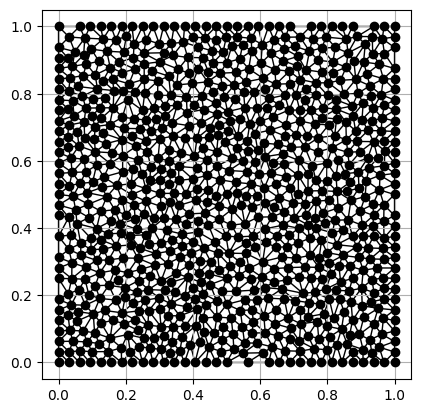

In [6]:
mesh_type = polydim.pde_tools.mesh.pde_mesh_utilities.MeshGenerator_Types_2D.triangular # specifica il tipo di mesh -> triangolare
method_type = polydim.pde_tools.local_space_pcc_2_d.MethodTypes.fem_pcc
mesh_size = 0.001    #genera dei triangoli di area massima data dall'area= 1 * 0.001 = 0.0001
mesh_data = gedim.MeshMatrices()
mesh = gedim.MeshMatricesDAO(mesh_data)
polydim.pde_tools.mesh.pde_mesh_utilities.create_mesh_2_d(
    geometry_utilities,
    mesh_utilities,
    mesh_type,
    pde_domain,
    mesh_size,
    mesh
)
mesh_geometric_data = polydim.pde_tools.mesh.pde_mesh_utilities.compute_mesh_2_d_geometry_data(
    geometry_utilities,
    mesh_utilities,
    mesh
)
vtk_utilities.export_mesh(export_mesh_path, mesh)
other_ut.plot_mesh(mesh) # plot della mesh 

In [7]:
mesh_connectivity_data = polydim.pde_tools.mesh.MeshMatricesDAO_mesh_connectivity_data(mesh)
pressure_reference_element_data = polydim.pde_tools.local_space_pcc_2_d.create_reference_element(
    method_type, 1
)
speed_reference_element_data = polydim.pde_tools.local_space_pcc_2_d.create_reference_element(
    method_type, 2
)

In [8]:
info_internal = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(
    polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none
)
info_internal.marker = 0

info_dirichlet = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(
    polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.strong
)
info_dirichlet.marker = 1

info_neumann_none = polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo(
    polydim.pde_tools.do_fs.DOFsManager.MeshDOFsInfo.BoundaryInfo.BoundaryTypes.none
)
info_neumann_none.marker = 0
pressure_boundary_info = {
    0: info_internal,       
    1: info_dirichlet,      # vertice (0,0): pressione fissata
    2: info_neumann_none,
    3: info_neumann_none,
    4: info_neumann_none,
    5: info_neumann_none,
    6: info_neumann_none,
    7: info_neumann_none,
    8: info_neumann_none
}
speed_boundary_info = {
    0: info_internal,
    1: info_dirichlet,      # vertice (0,0)
    2: info_dirichlet,      # vertice (1,0)
    3: info_dirichlet,      # vertice (1,1)
    4: info_dirichlet,      # vertice (0,1)
    5: info_dirichlet,      # lato y=0
    6: info_dirichlet,      # lato x=1
    7: info_dirichlet,      # lato y=1
    8: info_dirichlet       # lato x=0
}

In [9]:
dof_manager = polydim.pde_tools.do_fs.DOFsManager()

pressure_mesh_dofs_info = polydim.pde_tools.local_space_pcc_2_d.set_mesh_do_fs_info(
    pressure_reference_element_data,
    mesh,
    pressure_boundary_info
)
pressure_dofs_data = dof_manager.create_do_fs_2_d(
    pressure_mesh_dofs_info,
    mesh_connectivity_data
)

speed_mesh_dofs_info = polydim.pde_tools.local_space_pcc_2_d.set_mesh_do_fs_info(
    speed_reference_element_data,
    mesh,
    speed_boundary_info
)
speed_dofs_data = dof_manager.create_do_fs_2_d(
    speed_mesh_dofs_info,
    mesh_connectivity_data
)

In [10]:
### ATTENZIONE CAMBIANDO LA MESH SIZE CAMBIANO I GRADI DI LIBERTà

pressure_n_dofs = pressure_dofs_data.number_do_fs      # Numero totale di gradi di libertà della pressione
pressure_n_strongs = pressure_dofs_data.number_strongs # Numero di gradi di libertà della pressione con condizione di Dirichlet forte
speed_n_dofs = speed_dofs_data.number_do_fs            # Numero di gradi di libertà di una componente della velocità
speed_n_strongs = speed_dofs_data.number_strongs       # Numero di gradi di libertà vincolati di una componente della velocità


tot_dofs = 2 * speed_n_dofs + pressure_n_dofs
tot_strongs = 2 * speed_n_strongs + pressure_n_strongs

print("P dofs\t", "P stgs\t", "U dofs\t", "U stgs\t", "T dofs\t", "T stgs")
print(pressure_n_dofs, "\t", pressure_n_strongs, "\t",
      speed_n_dofs, "\t", speed_n_strongs, "\t",
      tot_dofs, "\t", tot_strongs)

# La discretizzazione genera complessivamente 6761 gradi di libertà: 829 associati alla pressione e 2966 per ciascuna componente della velocità.
# Di questi, 469 sono imposti mediante condizioni di Dirichlet forti, 
# mentre i restanti 6292 costituiscono le incognite effettive del sistema da determinare numericamente.

P dofs	 P stgs	 U dofs	 U stgs	 T dofs	 T stgs
829 	 1 	 2966 	 234 	 6761 	 469


In [11]:
# Definisce il parametro globale mu_1 e le due componenti del termine forzante
# parametrico f = (f_x, f_y), aggiornate automaticamente al variare di mu_1.
mu_1 = 2.0   # valore di default, lo aggiorneremo per ogni snapshot

def f_x_function(x, y, z):
    return (- (mu_1**3 * np.pi**2 * np.cos(mu_1**2 * np.pi * x) - mu_1**2 * np.pi**2)
              * np.sin(mu_1 * np.pi * y) * np.cos(mu_1 * np.pi * y)
            + mu_1 * np.pi * np.cos(mu_1 * np.pi * x) * np.cos(mu_1 * np.pi * y))

def f_y_function(x, y, z):
    return (- (-mu_1**3 * np.pi**2 * np.cos(mu_1**2 * np.pi * y) + mu_1**2 * np.pi**2)
              * np.sin(mu_1 * np.pi * x) * np.cos(mu_1 * np.pi * x)
            - mu_1 * np.pi * np.sin(mu_1 * np.pi * x) * np.sin(mu_1 * np.pi * y))

In [12]:
# Definisce condizioni di Dirichlet omogenee: entrambe le componenti della velocità
# e la pressione nei DOF vincolati sono poste uguali a zero.
def speed_x_strong_function(marker, x, y, z):
    return 0.0

def speed_y_strong_function(marker, x, y, z):
    return 0.0

def pressure_strong_function(marker, x, y, z):
    return 0.0

In [13]:
# Assembla i valori delle condizioni di Dirichlet forti per le componenti
# della velocità u_x, u_y e per la pressione nei rispettivi gradi di libertà vincolati.
u_x_strong = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_strong_solution(
    geometry_utilities, mesh, mesh_geometric_data,
    speed_mesh_dofs_info, speed_dofs_data,
    speed_reference_element_data, speed_x_strong_function
)
u_y_strong = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_strong_solution(
    geometry_utilities, mesh, mesh_geometric_data,
    speed_mesh_dofs_info, speed_dofs_data,
    speed_reference_element_data, speed_y_strong_function
)
p_strong = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_strong_solution(
    geometry_utilities, mesh, mesh_geometric_data,
    pressure_mesh_dofs_info, pressure_dofs_data,
    pressure_reference_element_data, pressure_strong_function
)

In [14]:
# Definisce la viscosità costante ν = 1 e i versori cartesiani utilizzati
# per identificare separatamente le direzioni x e y.
def nu_term(x, y, z):
    return 1.0

def b_x_term(x, y, z):
    return np.array([1.0, 0.0, 0.0])

def b_y_term(x, y, z):
    return np.array([0.0, 1.0, 0.0])

In [15]:

# COSTRUZIONE DEI BLOCCHI DEL SISTEMA FEM VELOCITÀ–PRESSIONE
#
# Il vettore globale delle incognite è ordinato come:
#
#     X = [u_x, u_y, p]^T
#
# dove:
# - u_x contiene i speed_n_dofs coefficienti della componente orizzontale della velocità;
# - u_y contiene i speed_n_dofs coefficienti della componente verticale della velocità;
# - p contiene i pressure_n_dofs coefficienti della pressione.
#
# La matrice globale ha quindi dimensione:
#
#     tot_dofs × tot_dofs
#
# e presenta, a meno dei segni dipendenti dalla formulazione debole adottata,
# la tipica struttura a blocchi del problema di Stokes/Navier–Stokes:
#
#               | A      0      B_x^T |
#     J =       | 0      A      B_y^T |
#               | B_x    B_y      0   |
#
# ---------------------------------------------------------------------------
# 1. OPERATORE DIFFUSIVO A
# ---------------------------------------------------------------------------
#
# A_operator assembla la matrice FEM scalare associata al termine viscoso:
#
#     A_ij = ∫_Ω ν ∇φ_j · ∇φ_i dΩ
#
# dove φ_j e φ_i sono le funzioni di forma dello spazio della velocità e
# ν è la viscosità definita dalla funzione nu_term.
#
# In concreto, questa matrice descrive la diffusione viscosa della velocità:
# penalizza forti variazioni spaziali di u e rappresenta numericamente il
# termine -νΔu presente nelle equazioni di Stokes/Navier–Stokes.
#
# A_operator contiene inizialmente l’operatore relativo a una sola componente
# scalare della velocità. Lo stesso operatore deve quindi essere inserito due
# volte nella matrice globale:
#
# - J_A_x inserisce A nel blocco relativo all’equazione di u_x e all’incognita u_x.
#   L’offset [0, 0] indica che il blocco parte dalla prima riga e prima colonna.
#
# - J_A_y inserisce A nel blocco relativo all’equazione di u_y e all’incognita u_y.
#   L’offset [speed_n_dofs, speed_n_dofs] salta tutti i DOF di u_x e posiziona
#   la matrice nel secondo blocco diagonale.
#
# Non ci sono blocchi diffusivi misti tra u_x e u_y, perciò i blocchi
# fuori diagonale tra le due componenti della velocità restano nulli.
#
# ---------------------------------------------------------------------------
# 2. OPERATORI B_x E B_y: ACCOPPIAMENTO VELOCITÀ–PRESSIONE
# ---------------------------------------------------------------------------
#
# B_x_operator e B_y_operator sono costruiti tramite assemble_advection_operator,
# ma in questo caso i vettori costanti:
#
#     b_x = (1, 0, 0)
#     b_y = (0, 1, 0)
#
# servono a selezionare rispettivamente la derivata nella direzione x e nella
# direzione y.
#
# Le matrici ottenute rappresentano quindi, in forma discreta, i contributi:
#
#     (B_x)_ij ≈ ∫_Ω ψ_i ∂φ_j/∂x dΩ
#     (B_y)_ij ≈ ∫_Ω ψ_i ∂φ_j/∂y dΩ
#
# dove:
# - φ_j è una funzione di forma della velocità;
# - ψ_i è una funzione di forma della pressione.
#
# Questi operatori permettono di costruire la divergenza discreta:
#
#     B_x u_x + B_y u_y ≈ ∂u_x/∂x + ∂u_y/∂y.
#
# Perciò l’ultima riga a blocchi del sistema:
#
#     B_x u_x + B_y u_y = 0
#
# rappresenta il vincolo di incomprimibilità:
#
#     ∇·u = 0.
#
# ---------------------------------------------------------------------------
# 3. INSERIMENTO DEI BLOCCHI B_x E B_y NELLA MATRICE GLOBALE
# ---------------------------------------------------------------------------
#
# J_B_x inserisce B_x nelle righe associate alla pressione e nelle colonne
# associate a u_x.
#
# L’offset:
#
#     [2 * speed_n_dofs, 0]
#
# significa:
# - saltare le righe di u_x e u_y e iniziare dalle equazioni della pressione;
# - partire dalla prima colonna, cioè dai DOF di u_x.
#
# J_B_y inserisce B_y nelle righe associate alla pressione e nelle colonne
# associate a u_y.
#
# L’offset:
#
#     [2 * speed_n_dofs, speed_n_dofs]
#
# significa:
# - iniziare dalle equazioni della pressione;
# - saltare le colonne di u_x e iniziare da quelle di u_y.
#
# Insieme, J_B_x e J_B_y formano il blocco di divergenza:
#
#     [B_x  B_y].
#
# ---------------------------------------------------------------------------
# 4. OPERATORI TRASPOSTI B_x^T E B_y^T
# ---------------------------------------------------------------------------
#
# J_BT_x e J_BT_y utilizzano gli stessi operatori B_x e B_y, ma con il flag
# True, che richiede la costruzione della loro trasposta.
#
# Le matrici trasposte rappresentano l’azione discreta del gradiente
# della pressione nelle equazioni della quantità di moto:
#
#     B_x^T p ≈ contributo di ∂p/∂x,
#     B_y^T p ≈ contributo di ∂p/∂y.
#
# In concreto:
# - B_x^T accoppia la pressione con l’equazione della velocità u_x;
# - B_y^T accoppia la pressione con l’equazione della velocità u_y.
#
# Questi blocchi costituiscono la colonna:
#
#     [B_x^T, B_y^T]^T
#
# della matrice globale. Il segno con cui verranno sommati alla matrice finale
# dipende dalla convenzione scelta nella formulazione debole, per esempio
# B^T oppure -B^T.
#
# In sintesi:
# - A descrive la diffusione viscosa della velocità;
# - B_x e B_y impongono il vincolo di divergenza nulla;
# - B_x^T e B_y^T introducono il gradiente della pressione nelle equazioni
#   delle due componenti della velocità;
# - la matrice globale risultante è un sistema misto a blocchi di tipo
#   saddle-point, tipico dei problemi incomprimibili.



A_operator = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_diffusion_operator(
    geometry_utilities,
    mesh,
    mesh_geometric_data,
    speed_dofs_data,
    speed_dofs_data,
    speed_reference_element_data,
    speed_reference_element_data,
    nu_term)

J_A_x = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [0, 0])

J_A_y = other_ut.make_np_sparse(
    A_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [speed_n_dofs, speed_n_dofs])

B_x_operator = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_advection_operator(
    geometry_utilities,
    mesh,
    mesh_geometric_data,
    speed_dofs_data,
    pressure_dofs_data,
    speed_reference_element_data,
    pressure_reference_element_data,
    b_x_term) 

B_y_operator = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_advection_operator(
    geometry_utilities,
    mesh,
    mesh_geometric_data,
    speed_dofs_data,
    pressure_dofs_data,
    speed_reference_element_data,
    pressure_reference_element_data,
    b_y_term)


J_B_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0])

J_B_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs])


J_BT_x = other_ut.make_np_sparse(
    B_x_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, 0],
    True)   # flag che attiva la trasposizione
    
J_BT_y = other_ut.make_np_sparse(
    B_y_operator.operator_dofs,
    [tot_dofs, tot_dofs],
    [2 * speed_n_dofs, speed_n_dofs],
    True)

In [16]:
# Matrice Stokes con mu_0 = 1 (la useremo nel Newton scalando per il vero mu_0)

# Costruisce la matrice globale di Stokes per viscosità di riferimento mu_0 = 1,
# combinando i blocchi diffusivi della velocità e gli accoppiamenti
# velocità-pressione.
# Successivamente controlla:
# - dimensione e numero di elementi non nulli della matrice;
# - densità della matrice sparsa;
# - simmetria tramite la norma di J_S_base - J_S_base^T;
# - presenza di eventuali righe vuote;
# - valori minimo e massimo della somma assoluta degli elementi di ogni riga.
# La matrice è attesa simmetrica perché i blocchi -B e -B^T sono trasposti.


J_S_base = (J_A_x + J_A_y) - J_B_x - J_B_y - J_BT_x - J_BT_y

print(f"J_S_base.shape = {J_S_base.shape}")
print(f"J_S_base.nnz   = {J_S_base.nnz} (entries non nulle)")
print(f"densità        = {J_S_base.nnz / (tot_dofs**2):.2%}")

diff = J_S_base - J_S_base.T
print(f"||J_S - J_S^T||_F (Frobenius) = {scipy.sparse.linalg.norm(diff):.2e}")
# atteso: 0 perché -B^T sopra e -B sotto sono trasposti l'uno dell'altro
row_sums = np.asarray(np.abs(J_S_base).sum(axis=1)).flatten()
n_empty_rows = int(np.sum(row_sums < 1e-14))
print(f"Numero di righe vuote in J_S_base: {n_empty_rows}")
print(f"Norma minima di riga: {row_sums.min():.2e}")
print(f"Norma massima di riga: {row_sums.max():.2e}")

J_S_base.shape = (6761, 6761)
J_S_base.nnz   = 121046 (entries non nulle)
densità        = 0.26%
||J_S - J_S^T||_F (Frobenius) = 4.67e-13
Numero di righe vuote in J_S_base: 0
Norma minima di riga: 1.04e-02
Norma massima di riga: 1.58e+01


In [17]:
# Assembla il vettore dei termini noti per un dato valore del parametro mu_1.
# La variabile globale mu_1 viene aggiornata, così le funzioni f_x_function e  f_y_function calcolano il forcing corrispondente. 
# I due contributi vengono assemblati separatamente per le componenti x e y della velocità e infine
# concatenati nel vettore globale [f_x; f_y; 0], poiché nell’equazione della # pressione non è presente un termine sorgente.

def assemble_forcing(mu1_val):
    """
    Assembla il vettore rhs di lunghezza N_h corrispondente al forcing f(x; mu1).
    Aggiorna la variabile globale mu_1 e chiama l'assemblatore del framework.
    """
    global mu_1
    mu_1 = mu1_val   # le funzioni f_x_function, f_y_function leggono questa

    f_x = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_source_term(
        geometry_utilities, mesh, mesh_geometric_data,
        speed_dofs_data, speed_reference_element_data, speed_reference_element_data,
        f_x_function
    )
    f_y = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_source_term(
        geometry_utilities, mesh, mesh_geometric_data,
        speed_dofs_data, speed_reference_element_data, speed_reference_element_data,
        f_y_function
    )

    # Concatena nel formato del sistema saddle-point: [u_1; u_2; p]
    return np.concatenate([f_x, f_y, np.zeros(pressure_n_dofs)])

In [18]:

# Risolve il problema Navier–Stokes parametrico per mu = (mu0, mu1) mediante
# il metodo di Newton: assembla forcing e matrice di Stokes, linearizza il
# termine convettivo a ogni iterazione, risolve il sistema per l’incremento du
# e aggiorna la soluzione finché l’errore relativo è sotto la tolleranza o
# viene raggiunto il numero massimo di iterazioni. Restituisce soluzione,
# numero di iterazioni e tempo di calcolo.
#    Restituisce:
#      x_full   : vettore soluzione [u_1; u_2; p] di lunghezza tot_dofs
#      n_iter   : numero di iterazioni di Newton
#      elapsed  : tempo totale in secondi
def solve_fom(mu, newton_tol=1e-6, max_iterations=15, verbose=False):

    mu0, mu1 = mu[0], mu[1]
    t_start = time.time()
    rhs_f = assemble_forcing(mu1)
    # 6.3.2 -- matrice Stokes lineare scalata per mu0
    J_S = mu0 * (J_A_x + J_A_y) - J_B_x - J_B_y - J_BT_x - J_BT_y

    # 6.3.3 -- inizializzazione: partiamo da soluzione nulla
    u_k = np.zeros(tot_dofs)
    u_x_num = np.zeros(speed_n_dofs)
    u_y_num = np.zeros(speed_n_dofs)

    residual_norm = 1.0
    solution_norm = 1.0
    n_iter = 0

    # 6.3.4 -- ciclo di Newton
    while n_iter < max_iterations and residual_norm > newton_tol * solution_norm:
        # Assembla operatore di convezione linearizzato attorno a u_k
        c_op = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_ns_operators(
            geometry_utilities, mesh, mesh_geometric_data,
            speed_dofs_data, speed_reference_element_data,
            u_x_num, u_y_num,
            u_x_strong, u_y_strong
        )

        # Embed nei due oggetti N_h x N_h
        J_C = other_ut.make_np_sparse(
            c_op.convective_operator.operator_dofs,
            [tot_dofs, tot_dofs], [0, 0]
        )
        f_C = np.concatenate([c_op.convective_rhs, np.zeros(pressure_n_dofs)])

        # Costruisci rhs di Newton: F - C(u_k)u_k - J_S * u_k
        rhs_newton = rhs_f - f_C - J_S @ u_k

        # Risolvi il sistema linearizzato
        du = scipy.sparse.linalg.spsolve(J_S + J_C, rhs_newton)

        # Aggiorna
        u_k = u_k + du
        u_x_num = u_k[:speed_n_dofs]
        u_y_num = u_k[speed_n_dofs:2 * speed_n_dofs]

        # Norme per il criterio di arresto
        residual_norm = np.linalg.norm(du)
        solution_norm = max(np.linalg.norm(u_k), 1e-12)

        n_iter += 1
        if verbose:
            print(f"  Newton iter {n_iter:2d}: ||du|| = {residual_norm:.3e}, "
                  f"||u|| = {solution_norm:.3e}, ratio = {residual_norm/solution_norm:.3e}")

    elapsed = time.time() - t_start
    return u_k, n_iter, elapsed

In [19]:
print("=" * 60)
print("Test FOM per mu = (1.0, 2.0)")
print("=" * 60)

x_full, n_iter, elapsed = solve_fom(np.array([1.0, 2.0]), verbose=True)

print(f"\nConvergenza in {n_iter} iterazioni, tempo: {elapsed:.3f} s")
print(f"||u_1|| = {np.linalg.norm(x_full[:speed_n_dofs]):.4f}")
print(f"||u_2|| = {np.linalg.norm(x_full[speed_n_dofs:2*speed_n_dofs]):.4f}")
print(f"||p||   = {np.linalg.norm(x_full[2*speed_n_dofs:]):.4f}")

Test FOM per mu = (1.0, 2.0)
  Newton iter  1: ||du|| = 1.680e+01, ||u|| = 1.680e+01, ratio = 1.000e+00
  Newton iter  2: ||du|| = 6.814e-01, ||u|| = 1.681e+01, ratio = 4.053e-02
  Newton iter  3: ||du|| = 3.947e-08, ||u|| = 1.681e+01, ratio = 2.348e-09

Convergenza in 3 iterazioni, tempo: 0.505 s
||u_1|| = 6.0001
||u_2|| = 6.0076
||p||   = 14.5094


In [20]:
print(x_full)

[-1.04850155e-05 -5.64541655e-05  1.98689012e-04 ... -1.24085511e-01
 -2.64294597e-02 -5.34476916e-01]


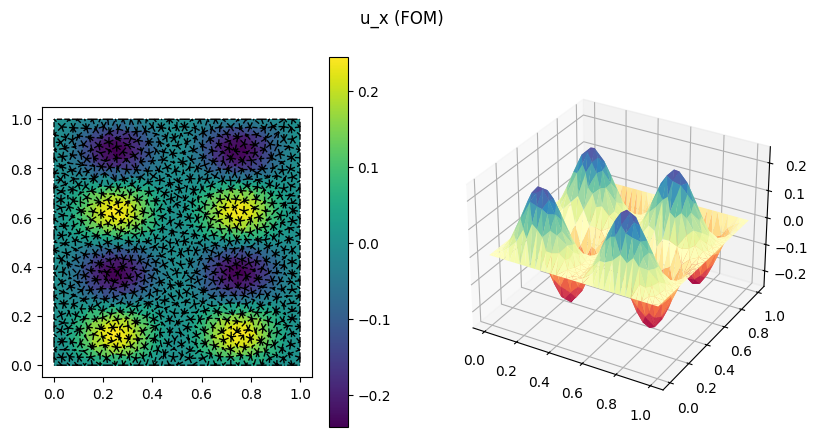

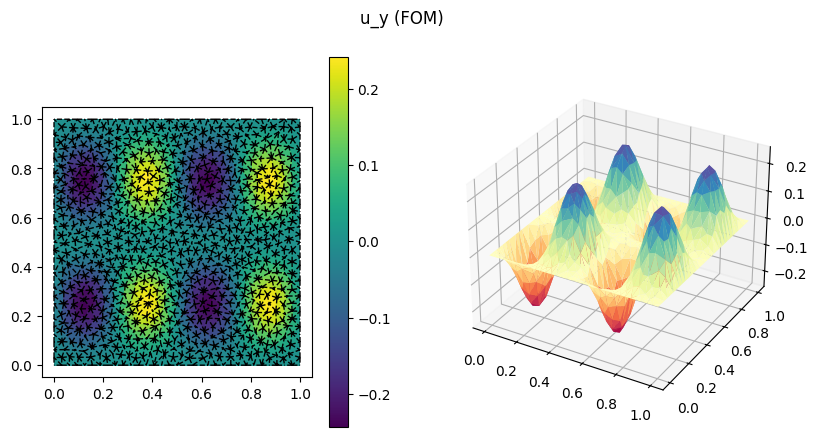

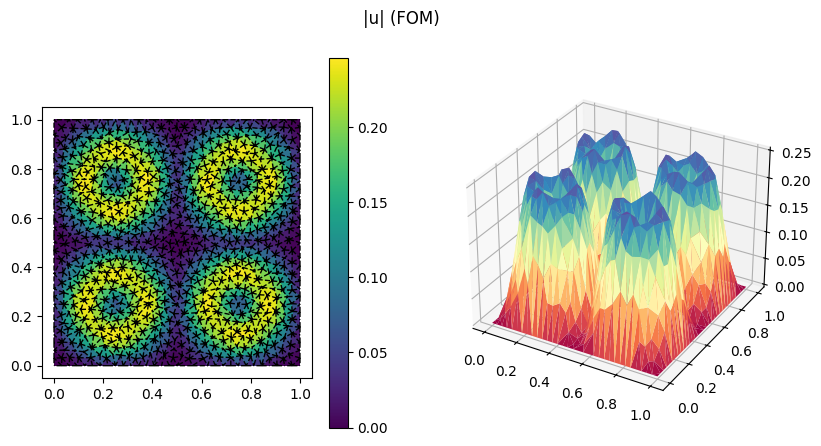

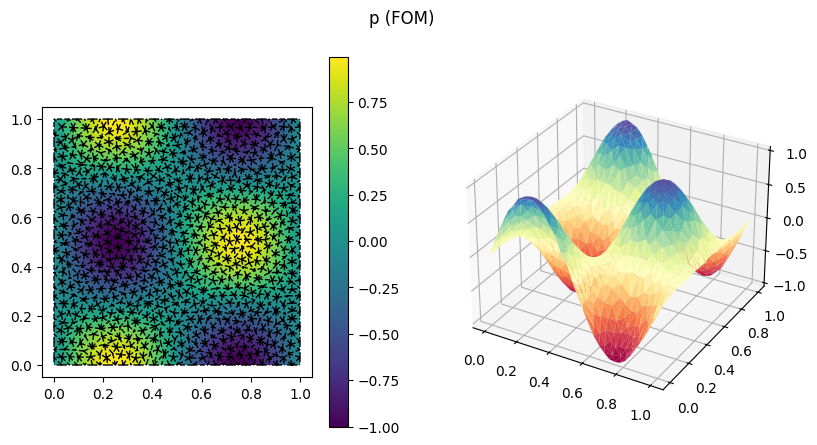

In [21]:
# Estraggo le tre componenti
u_x_sol = x_full[:speed_n_dofs]
u_y_sol = x_full[speed_n_dofs:2*speed_n_dofs]
p_sol   = x_full[2*speed_n_dofs:]

# Le proietto sui vertici della mesh per il plot
u_x_on_cell0Ds = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(
    mesh, speed_dofs_data, u_x_sol, u_x_strong
)
u_y_on_cell0Ds = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(
    mesh, speed_dofs_data, u_y_sol, u_y_strong
)
p_on_cell0Ds = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(
    mesh, pressure_dofs_data, p_sol, p_strong
)

# Esporto VTK (per ParaView)
vtk_utilities.export_solution_2(export_solution_path + '/fom_u_x',
                                mesh, u_x_on_cell0Ds.numeric_solution)
vtk_utilities.export_solution_2(export_solution_path + '/fom_u_y',
                                mesh, u_y_on_cell0Ds.numeric_solution)
vtk_utilities.export_solution_2(export_solution_path + '/fom_p',
                                mesh, p_on_cell0Ds.numeric_solution)

# Plot inline
other_ut.plot_solution(mesh, u_x_on_cell0Ds.numeric_solution, "u_x (FOM)")
other_ut.plot_solution(mesh, u_y_on_cell0Ds.numeric_solution, "u_y (FOM)")
u_mag = np.sqrt(u_x_on_cell0Ds.numeric_solution**2 + u_y_on_cell0Ds.numeric_solution**2)
other_ut.plot_solution(mesh, u_mag, "|u| (FOM)")
other_ut.plot_solution(mesh, p_on_cell0Ds.numeric_solution, "p (FOM)")

In [22]:
# Stiffness vettoriale 2*N_u^delta x 2*N_u^delta (prodotto interno H1 della velocità)

# Costruisce gli operatori necessari per definire il prodotto interno della
# velocità e l’operatore di divergenza nel problema misto velocità–pressione.
#
# X_1 e X_2 inseriscono la matrice di stiffness A nei blocchi associati,
# rispettivamente, alle componenti u_x e u_y. La loro somma produce la matrice
# vettoriale:
#
#                 | A  0 |
#     X =         | 0  A |
#
# di dimensione 2*N_u × 2*N_u. Essa rappresenta il prodotto interno basato sui
# gradienti delle due componenti della velocità:
#
#     u^T X v ≈ ∫_Ω (∇u_x·∇v_x + ∇u_y·∇v_y) dΩ.
#
# Si tratta propriamente del prodotto interno associato alla seminorma H1;
# con condizioni di Dirichlet omogenee è equivalente alla norma H1 completa.
# Questa matrice serve, ad esempio, per calcolare norme ed errori della velocità,
# costruire basi POD ortonormali rispetto a H1 e risolvere i problemi dei supremizer.
#
# B_1 e B_2 inseriscono gli operatori delle derivate nelle colonne relative,
# rispettivamente, a u_x e u_y. La loro somma rappresenterebbe l’operatore
# discreto di divergenza:
#
#     B = [B_x  B_y],
#
# di dimensione N_p × 2*N_u, tale che:
#
#     B u ≈ ∂u_x/∂x + ∂u_y/∂y.
#
# Questo operatore accoppia velocità e pressione e permette di imporre il
# vincolo di incomprimibilità B u = 0. È inoltre utilizzato nella costruzione
# dei supremizer e nella verifica della stabilità inf-sup dello spazio ridotto.
#
# inner_product_u = X_1 + X_2 è quindi la matrice globale del prodotto interno
# H1 della velocità, applicato contemporaneamente alle due componenti.


X_1 = other_ut.make_np_sparse(A_operator.operator_dofs,
                              [2 * speed_n_dofs, 2 * speed_n_dofs], [0, 0])
X_2 = other_ut.make_np_sparse(A_operator.operator_dofs,
                              [2 * speed_n_dofs, 2 * speed_n_dofs],
                              [speed_n_dofs, speed_n_dofs])

# Operatore divergenza N_p^delta x 2*N_u^delta
B_1 = other_ut.make_np_sparse(B_x_operator.operator_dofs,
                              [pressure_n_dofs, 2 * speed_n_dofs], [0, 0])
B_2 = other_ut.make_np_sparse(B_y_operator.operator_dofs,
                              [pressure_n_dofs, 2 * speed_n_dofs],
                              [0, speed_n_dofs])

# Prodotto interno della velocità (norma H1)
inner_product_u = X_1 + X_2

In [23]:
N_snap = 200              # numero di snapshot
np.random.seed(0)         # riproducibilità

training_set = np.random.uniform(
    low=P[:, 0],          # [0.1, 1.0]  -> minimi di (mu0, mu1)
    high=P[:, 1],         # [10.0, 3.0] -> massimi di (mu0, mu1)
    size=(N_snap, 2)
)

print(f"Training set: {N_snap} campioni in P = "
      f"[{P[0,0]}, {P[0,1]}] x [{P[1,0]}, {P[1,1]}]")
print(f"Range mu_0 campionato: [{training_set[:,0].min():.2f}, {training_set[:,0].max():.2f}]")
print(f"Range mu_1 campionato: [{training_set[:,1].min():.2f}, {training_set[:,1].max():.2f}]")

Training set: 200 campioni in P = [0.1, 10.0] x [1.0, 3.0]
Range mu_0 campionato: [0.22, 9.90]
Range mu_1 campionato: [1.01, 3.00]


In [24]:
############### ROM 
# GENERAZIONE DEGLI SNAPSHOT NELLA FASE OFFLINE
#
# Per ogni parametro mu appartenente al training set viene risolto il modello
# completo FOM di Navier–Stokes. Dalla soluzione globale:
#
#     x_full = [u_x; u_y; p]
#
# vengono estratti:
# - snap_u: snapshot della velocità, contenente entrambe le componenti u_x e u_y;
# - snap_p: snapshot della pressione;
# - snap_s: snapshot del supremizer associato alla pressione.
#
# Il numero di iterazioni di Newton e il tempo necessario per ogni soluzione
# FOM vengono salvati per monitorare convergenza e costo computazionale.
#
# Il supremizer s è ottenuto risolvendo:
#
#     X s = B^T p,
#
# con:
#     X = X_1 + X_2
# prodotto interno H1 della velocità,
#
#     B = B_1 + B_2
# operatore discreto di divergenza.
#
# Il supremizer trasforma quindi ogni modo di pressione in una funzione dello
# spazio della velocità e servirà ad arricchire la base ridotta della velocità,
# migliorando la stabilità inf-sup del modello ridotto velocità–pressione.
#
# Al termine del ciclo, le liste vengono convertite in matrici NumPy:
#
#     snapshot_matrix_u : dimensione (N_snap, 2*N_u)
#     snapshot_matrix_p : dimensione (N_snap, N_p)
#     snapshot_matrix_s : dimensione (N_snap, 2*N_u)
#
# Ogni riga rappresenta la soluzione ottenuta per un diverso valore del
# parametro mu. Queste matrici saranno successivamente utilizzate per la POD
# e per la costruzione delle basi ridotte di velocità, pressione e supremizer

snapshot_matrix_u = []     # snapshot di velocità  (2*N_u^delta ciascuno)
snapshot_matrix_p = []     # snapshot di pressione (N_p^delta ciascuno)
snapshot_matrix_s = []     # snapshot di supremizer (2*N_u^delta ciascuno)

newton_iters = []          # per monitorare la convergenza
fom_times = []             # per il confronto dei tempi

print("Generazione degli snapshot in corso...")
t_offline_start = time.time()

for i, mu in enumerate(training_set):
    if i % 10 == 0:
        print(f"  snapshot {i:3d} / {N_snap}")

    # --- risolvo il FOM per questo mu ---
    x_full, n_it, t_fom = solve_fom(mu, verbose=False)
    newton_iters.append(n_it)
    fom_times.append(t_fom)

    # --- estraggo velocità e pressione ---
    snap_u = x_full[:2 * speed_n_dofs]       # le due componenti di velocità
    snap_p = x_full[2 * speed_n_dofs:]       # la pressione
    snapshot_matrix_u.append(np.copy(snap_u))
    snapshot_matrix_p.append(np.copy(snap_p))

    # --- calcolo del supremizer ---
    # risolvo:  (X_1 + X_2) s = (B_1 + B_2)^T p
    snap_s = scipy.sparse.linalg.spsolve(
        X_1 + X_2,
        np.transpose(B_1 + B_2) @ snap_p
    )
    snapshot_matrix_s.append(np.copy(snap_s))

# converto le liste in array numpy: shape (N_snap, dim)
snapshot_matrix_u = np.array(snapshot_matrix_u)
snapshot_matrix_p = np.array(snapshot_matrix_p)
snapshot_matrix_s = np.array(snapshot_matrix_s)

t_offline_snapshots = time.time() - t_offline_start

print(f"\nGenerazione completata in {t_offline_snapshots:.1f} s")
print(f"snapshot_matrix_u: {snapshot_matrix_u.shape}")
print(f"snapshot_matrix_p: {snapshot_matrix_p.shape}")
print(f"snapshot_matrix_s: {snapshot_matrix_s.shape}")
print(f"Iterazioni di Newton: min={min(newton_iters)}, "
      f"max={max(newton_iters)}, media={np.mean(newton_iters):.1f}")

Generazione degli snapshot in corso...
  snapshot   0 / 200
  snapshot  10 / 200
  snapshot  20 / 200
  snapshot  30 / 200
  snapshot  40 / 200
  snapshot  50 / 200
  snapshot  60 / 200
  snapshot  70 / 200
  snapshot  80 / 200
  snapshot  90 / 200
  snapshot 100 / 200
  snapshot 110 / 200
  snapshot 120 / 200
  snapshot 130 / 200
  snapshot 140 / 200
  snapshot 150 / 200
  snapshot 160 / 200
  snapshot 170 / 200
  snapshot 180 / 200
  snapshot 190 / 200

Generazione completata in 96.4 s
snapshot_matrix_u: (200, 5932)
snapshot_matrix_p: (200, 829)
snapshot_matrix_s: (200, 5932)
Iterazioni di Newton: min=3, max=4, media=3.0


In [25]:
# Calcola il supremizer associato allo snapshot di pressione risolvendo
# il sistema (X_1 + X_2)s = (B_1 + B_2)^T p, utile per stabilizzare
# il modello ridotto velocità-pressione e preservare la condizione inf-sup.
snap_s = scipy.sparse.linalg.spsolve(X_1 + X_2, np.transpose(B_1 + B_2) @ snap_p)

In [26]:

# Verifica la qualità degli snapshot generati:
# - calcola la norma euclidea media di velocità, pressione e supremizer;
# - controlla che le matrici non contengano valori NaN o Inf, che potrebbero
#   indicare errori numerici o il fallimento del metodo di Newton;
# - individua gli snapshot per cui Newton ha raggiunto il numero massimo
#   di iterazioni senza convergere e stampa i relativi valori del parametro mu.
# Se non vengono trovati problemi, conferma che tutti gli snapshot sono validi.
print("\n--- Verifica snapshot ---")
print(f"||u|| medio sugli snapshot: {np.mean(np.linalg.norm(snapshot_matrix_u, axis=1)):.3f}")
print(f"||p|| medio sugli snapshot: {np.mean(np.linalg.norm(snapshot_matrix_p, axis=1)):.3f}")
print(f"||s|| medio sugli snapshot: {np.mean(np.linalg.norm(snapshot_matrix_s, axis=1)):.3f}")

# controllo che non ci siano NaN o Inf (segnale di Newton fallito)
for name, mat in [("u", snapshot_matrix_u), ("p", snapshot_matrix_p), ("s", snapshot_matrix_s)]:
    n_bad = np.sum(~np.isfinite(mat))
    print(f"  snapshot_matrix_{name}: {n_bad} valori non finiti")

# controllo dei casi non convergenti
non_converged = [i for i, n in enumerate(newton_iters) if n >= 15]
if non_converged:
    print(f"\n  ATTENZIONE: {len(non_converged)} snapshot non convergenti agli indici {non_converged}")
    for idx in non_converged:
        print(f"    mu = {training_set[idx]}")
else:
    print("\n  Tutti gli snapshot convergono correttamente.")


--- Verifica snapshot ---
||u|| medio sugli snapshot: 3.003
||p|| medio sugli snapshot: 47.078
||s|| medio sugli snapshot: 4.764
  snapshot_matrix_u: 0 valori non finiti
  snapshot_matrix_p: 0 valori non finiti
  snapshot_matrix_s: 0 valori non finiti

  Tutti gli snapshot convergono correttamente.


In [27]:

# Imposta i criteri per selezionare il numero di modi POD:
# - tol_pod = 1 - 1e-7 richiede che la base ridotta conservi almeno il
#   99.99999% dell’energia totale degli snapshot, trascurandone al massimo 1e-7;
# - N_max = 35 limita comunque la base a un massimo di 35 modi per ciascuno
#   spazio ridotto, evitando un ROM troppo grande e costoso.
# Il numero effettivo di modi è quindi il minimo tra quello richiesto dalla
# soglia energetica, 35 e il rango disponibile della matrice degli snapshot.

tol_pod = 1.0 - 1e-7      # soglia di energia cumulata
N_max = 35           # tetto massimo al numero di modi per spazio

In [28]:
# Covarianza: C[i,j] = <snapshot_i, snapshot_j> nel prodotto interno scelto
C_u = snapshot_matrix_u @ inner_product_u @ snapshot_matrix_u.T
C_s = snapshot_matrix_s @ inner_product_u @ snapshot_matrix_s.T
C_p = snapshot_matrix_p @ snapshot_matrix_p.T

print(f"C_u: {C_u.shape}   C_s: {C_s.shape}   C_p: {C_p.shape}")

C_u: (200, 200)   C_s: (200, 200)   C_p: (200, 200)


In [29]:


#    Diagonalizza la matrice di covarianza C, ordina gli autovalori in modo
#    decrescente, e determina quanti modi N servono a catturare la frazione  di energia 'tol'.
#    Ritorna:
#      N           : numero di modi da tenere
#     eigenvalues : autovalori ordinati (decrescente)
#     eigenvectors: lista di autovettori corrispondenti



def eig_analysis(C, N_max=20, tol=1.0 - 1e-7):

    L, V = np.linalg.eig(C)

    # parte reale (C e' simmetrica -> autovalori reali, ma eig puo' dare
    # piccole componenti immaginarie per rumore numerico)
    eigenvalues = []
    eigenvectors = []
    for i in range(len(L)):
        assert np.isclose(L[i].imag, 0.0), f"autovalore complesso: {L[i]}"
        eigenvalues.append(L[i].real)
        eigenvectors.append(V[:, i].real)

    eigenvalues = np.array(eigenvalues)

    # ordinamento decrescente
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = [eigenvectors[i] for i in order]

    # energia cumulata
    total_energy = np.sum(eigenvalues)
    cumulative = np.cumsum(eigenvalues) / total_energy

    # scelta di N
    if np.all(cumulative < tol):
        N = N_max
    else:
        N = int(np.argmax(cumulative >= tol)) + 1
    N = min(N, N_max)

    return N, eigenvalues, eigenvectors

In [30]:
N_u, eigs_u, vecs_u = eig_analysis(C_u, N_max=N_max, tol=tol_pod)
N_s, eigs_s, vecs_s = eig_analysis(C_s, N_max=N_max, tol=tol_pod)
N_p, eigs_p, vecs_p = eig_analysis(C_p, N_max=N_max, tol=tol_pod)

print("Dimensioni ridotte:")
print(f"  N_u (velocita')  = {N_u}")
print(f"  N_s (supremizer) = {N_s}")
print(f"  N_p (pressione)  = {N_p}")
print(f"  N totale         = {N_u + N_s + N_p}")

Dimensioni ridotte:
  N_u (velocita')  = 22
  N_s (supremizer) = 28
  N_p (pressione)  = 28
  N totale         = 78


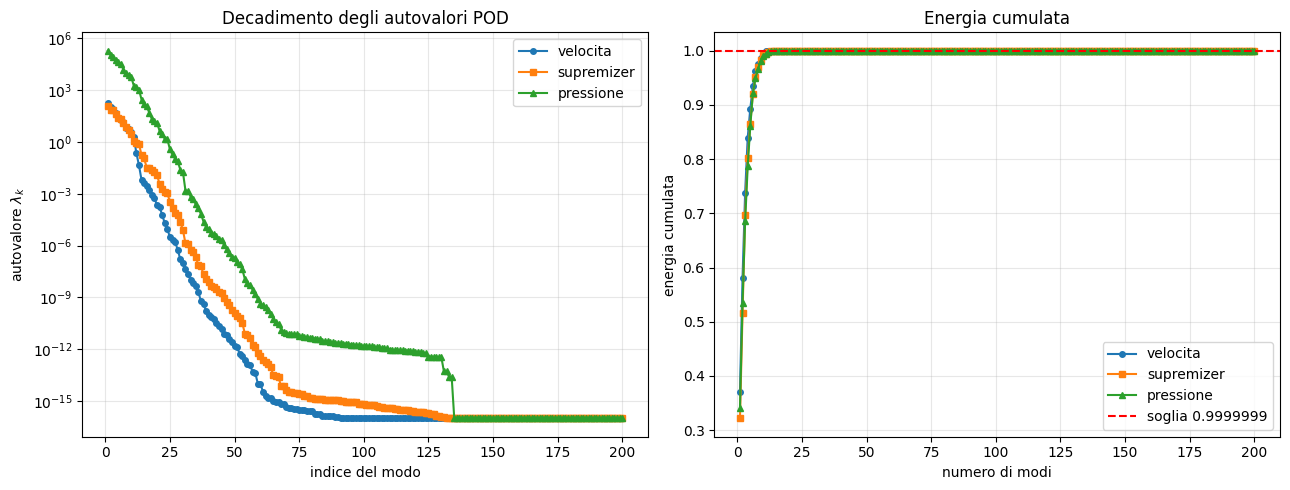

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# autovalori in scala semilog
for eigs, label, marker in [(eigs_u, 'velocita', 'o'),
                             (eigs_s, 'supremizer', 's'),
                             (eigs_p, 'pressione', '^')]:
    eigs_pos = np.maximum(eigs, 1e-16)   # evito log di zero/negativi
    axes[0].semilogy(range(1, len(eigs_pos) + 1), eigs_pos,
                     marker=marker, label=label, markersize=4)
axes[0].set_xlabel('indice del modo')
axes[0].set_ylabel('autovalore $\\lambda_k$')
axes[0].set_title('Decadimento degli autovalori POD')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# energia cumulata
for eigs, label, marker in [(eigs_u, 'velocita', 'o'),
                             (eigs_s, 'supremizer', 's'),
                             (eigs_p, 'pressione', '^')]:
    cum = np.cumsum(np.maximum(eigs, 0)) / np.sum(np.maximum(eigs, 0))
    axes[1].plot(range(1, len(cum) + 1), cum,
                 marker=marker, label=label, markersize=4)
axes[1].axhline(tol_pod, color='red', linestyle='--', label=f'soglia {tol_pod}')
axes[1].set_xlabel('numero di modi')
axes[1].set_ylabel('energia cumulata')
axes[1].set_title('Energia cumulata')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(export_file_path + '/pod_eigenvalues.png', dpi=120)
plt.show()

In [32]:

# COSTRUZIONE DELLE BASI POD
#
# Per ciascuno dei primi N autovettori della matrice di correlazione, costruisce
# il corrispondente modo POD come combinazione lineare degli snapshot:
#
#     phi_n = S^T v_n,
#
# dove S contiene gli snapshot disposti per righe e v_n è l’autovettore
# associato all’n-esimo autovalore. Il vettore ottenuto appartiene quindi allo
# spazio completo e ha la stessa dimensione di un singolo snapshot.
#
# Ogni modo viene poi normalizzato:
# - rispetto al prodotto interno H1, tramite sqrt(phi_n^T X phi_n), per le basi
#   della velocità e dei supremizer;
# - rispetto alla norma euclidea, tramite ||phi_n||_2, per la pressione.
#
# I modi normalizzati vengono infine impilati come colonne, ottenendo una
# matrice di base di dimensione (dim, N). Le matrici basis_functions_u,
# basis_functions_s e basis_functions_p contengono quindi rispettivamente
# le basi ridotte POD di velocità, supremizer e pressione.
#
# Nota: l’accesso eigenvectors[n] è corretto solo se gli autovettori sono
# memorizzati per righe; se sono memorizzati per colonne, occorre usare
# eigenvectors[:, n].



def build_basis(N, snapshot_matrix, eigenvectors, eigenvalues, inner_product=None):
    """
    Costruisce la matrice di base POD proiettando gli snapshot sugli autovettori.
    Ogni colonna e' un modo POD, normalizzato nel prodotto interno scelto.

    snapshot_matrix : shape (N_snap, dim)  -- snapshot in riga
    Ritorna         : shape (dim, N)       -- modi in colonna
    """
    basis_functions = []
    for n in range(N):
        # proiezione: modo = S^T @ autovettore_n
        basis = snapshot_matrix.T @ eigenvectors[n]

        # normalizzazione nel prodotto interno
        if inner_product is not None:
            norm = np.sqrt(basis @ inner_product @ basis)
        else:
            norm = np.linalg.norm(basis)
        basis = basis / norm

        basis_functions.append(np.copy(basis))

    # impilo i modi come colonne
    return np.array(basis_functions).T


basis_functions_u = build_basis(N_u, snapshot_matrix_u, vecs_u, eigs_u,
                                inner_product=inner_product_u)
basis_functions_s = build_basis(N_s, snapshot_matrix_s, vecs_s, eigs_s,
                                inner_product=inner_product_u)
basis_functions_p = build_basis(N_p, snapshot_matrix_p, vecs_p, eigs_p,
                                inner_product=None)

print(f"basis_functions_u: {basis_functions_u.shape}")
print(f"basis_functions_s: {basis_functions_s.shape}")
print(f"basis_functions_p: {basis_functions_p.shape}")

basis_functions_u: (5932, 22)
basis_functions_s: (5932, 28)
basis_functions_p: (829, 28)


In [33]:

# COSTRUZIONE DELLA BASE RIDOTTA GLOBALE
#
# Il numero totale di funzioni della base ROM è dato dalla somma dei modi POD
# di velocità, supremizer e pressione:
#
#     N_total = N_u + N_s + N_p.
#
# global_basis ha dimensione tot_dofs × N_total e permette di rappresentare
# l’intera soluzione FOM x = [u_x; u_y; p] mediante pochi coefficienti ridotti:
#
#     x ≈ global_basis @ x_N.
#
# La base presenta la struttura a blocchi:
#
#                  | B_u   B_s   0  |
#     global_basis =|                |
#                  |  0     0   B_p |
#
# dove:
# - B_u contiene i modi POD della velocità;
# - B_s contiene i modi supremizer, aggiunti allo spazio della velocità per
#   preservare la stabilità inf-sup dell’accoppiamento velocità-pressione;
# - B_p contiene i modi POD della pressione.
#
# Le prime 2*speed_n_dofs righe corrispondono alle due componenti della
# velocità, mentre le righe successive corrispondono alla pressione.
#
# global_basis_no_sup costruisce invece una base ridotta senza supremizer,
# contenente solo modi di velocità e pressione. Questa versione viene usata
# come confronto per mostrare che, senza l’arricchimento supremizer, il ROM
# può perdere stabilità e produrre una pressione oscillante o inaccurata.

N_total = N_u + N_s + N_p

# Base globale: struttura a blocchi
#   [ B_u  B_s   0  ]
#   [  0    0   B_p ]
global_basis = np.zeros((tot_dofs, N_total))

# blocco velocita': righe 0 : 2*speed_n_dofs
global_basis[0:2*speed_n_dofs, 0:N_u] = basis_functions_u
global_basis[0:2*speed_n_dofs, N_u:N_u+N_s] = basis_functions_s

# blocco pressione: righe 2*speed_n_dofs : tot_dofs
global_basis[2*speed_n_dofs:, N_u+N_s:] = basis_functions_p

print(f"global_basis: {global_basis.shape}")
print(f"  (attesa: ({tot_dofs}, {N_total}))")

# versione SENZA supremizer (per dimostrare l'instabilita' al passo successivo)
global_basis_no_sup = np.zeros((tot_dofs, N_u + N_p))
global_basis_no_sup[0:2*speed_n_dofs, 0:N_u] = basis_functions_u
global_basis_no_sup[2*speed_n_dofs:, N_u:] = basis_functions_p

global_basis: (6761, 78)
  (attesa: (6761, 78))


In [34]:
# VERIFICA DELL’ORTONORMALITÀ DELLE BASI POD
#
# Si costruiscono le matrici di Gram delle basi ridotte e si controlla che
# siano approssimativamente uguali alla matrice identità.
#
# Per velocità e supremizer si usa il prodotto interno H1 rappresentato
# dalla matrice X = inner_product_u:
#
#     B_u^T X B_u ≈ I,      B_s^T X B_s ≈ I.
#
# Per la pressione si usa invece il prodotto interno euclideo:
#
#     B_p^T B_p ≈ I.
#
# La norma della differenza dalla matrice identità misura l’errore di
# ortonormalità: valori prossimi alla precisione numerica indicano che i modi
# sono correttamente normalizzati e linearmente indipendenti.
#
# Questa verifica riguarda separatamente le basi B_u e B_s; non controlla che
# i modi di velocità siano ortogonali ai modi supremizer nella base combinata.

print("\n--- Verifica ortonormalita' delle basi ---")
# velocita': B_u^T X_u B_u dovrebbe essere l'identita'
gram_u = basis_functions_u.T @ inner_product_u @ basis_functions_u
err_u = np.linalg.norm(gram_u - np.eye(N_u))
print(f"||B_u^T X B_u - I|| = {err_u:.2e}")

# supremizer
gram_s = basis_functions_s.T @ inner_product_u @ basis_functions_s
err_s = np.linalg.norm(gram_s - np.eye(N_s))
print(f"||B_s^T X B_s - I|| = {err_s:.2e}")

# pressione (prodotto euclideo)
gram_p = basis_functions_p.T @ basis_functions_p
err_p = np.linalg.norm(gram_p - np.eye(N_p))
print(f"||B_p^T B_p - I||   = {err_p:.2e}")


--- Verifica ortonormalita' delle basi ---
||B_u^T X B_u - I|| = 2.55e-11
||B_s^T X B_s - I|| = 4.48e-11
||B_p^T B_p - I||   = 3.36e-11


# Preparazione del modello FOM e delle basi POD

## 1. Dominio geometrico

Il dominio considerato è il quadrato unitario:

$$
\Omega = [0,1]\times[0,1].
$$

I suoi vertici sono:

$$
P_1=(0,0), \qquad
P_2=(1,0), \qquad
P_3=(1,1), \qquad
P_4=(0,1).
$$

Il vettore globale delle incognite è ordinato come:

$$
\mathbf{x}_h =
\begin{bmatrix}
\mathbf{u}_{x,h}\\
\mathbf{u}_{y,h}\\
\mathbf{p}_h
\end{bmatrix}.
$$

dove:

- $\mathbf{u}_{x,h}$ contiene i coefficienti della componente orizzontale della velocità;
- $\mathbf{u}_{y,h}$ contiene i coefficienti della componente verticale;
- $\mathbf{p}_h$ contiene i coefficienti della pressione.

## 2. Discretizzazione agli elementi finiti

Per la velocità si utilizzano elementi quadratici $P_2$, mentre per la
pressione si utilizzano elementi lineari $P_1$:

$$
\mathbf{V}_h \times Q_h = [P_2]^2 \times P_1.
$$

Questa scelta prende il nome di coppia di Taylor--Hood.

## 3. Condizioni al contorno

Sulla frontiera del dominio si impone una condizione di Dirichlet omogenea:

$$
\mathbf{u}_h = \mathbf{0}
\qquad \text{su } \partial\Omega.
$$

La pressione viene fissata nel vertice $(0,0)$:

$$
p_h(0,0)=0.
$$

Questa condizione elimina l'indeterminazione della pressione rispetto a una
costante additiva.

## 4. Struttura della matrice di Stokes

La matrice globale ha la struttura a blocchi:

$$
J_S(\mu_0)=
\begin{bmatrix}
\mu_0 A & 0 & -B_x^T\\
0 & \mu_0 A & -B_y^T\\
-B_x & -B_y & 0
\end{bmatrix}.
$$

In questa matrice:

- $A$ rappresenta il termine diffusivo della velocità;
- $B_x$ e $B_y$ rappresentano la divergenza discreta;
- $B_x^T$ e $B_y^T$ rappresentano il gradiente discreto della pressione.

## 5. Metodo di Newton

A ogni iterazione si risolve il sistema linearizzato:

$$
\left[
J_S + J_C\left(\mathbf{x}_h^{(k)}\right)
\right]
\delta\mathbf{x}^{(k)}
=
\mathbf{r}^{(k)}.
$$

La soluzione viene aggiornata mediante:

$$
\mathbf{x}_h^{(k+1)}
=
\mathbf{x}_h^{(k)}
+
\delta\mathbf{x}^{(k)}.
$$

Il criterio di arresto è:

$$
\frac{
\left\|\delta\mathbf{x}^{(k)}\right\|_2
}{
\left\|\mathbf{x}_h^{(k+1)}\right\|_2
}
\leq
\texttt{newton\_tol}.
$$

## 6. Risultati del test FOM

Il modello completo è stato testato per il parametro:

$$
\boldsymbol{\mu}=(\mu_0,\mu_1)=(1,2).
$$

Il metodo di Newton ha prodotto i seguenti risultati:

| Iterazione | $\|\delta\mathbf{x}\|_2$ | $\|\mathbf{x}\|_2$ | Errore relativo |
|---:|---:|---:|---:|
| 1 | $1.680\cdot10^{1}$ | $1.680\cdot10^{1}$ | $1.000$ |
| 2 | $6.814\cdot10^{-1}$ | $1.681\cdot10^{1}$ | $4.053\cdot10^{-2}$ |
| 3 | $3.947\cdot10^{-8}$ | $1.681\cdot10^{1}$ | $2.348\cdot10^{-9}$ |

La convergenza viene raggiunta in tre iterazioni, poiché all'ultima iterazione:

$$
\frac{\|\delta\mathbf{x}^{(3)}\|_2}
{\|\mathbf{x}^{(3)}\|_2}
=
2.348\cdot10^{-9}
<
10^{-6}.
$$

Il tempo di soluzione del modello completo è:

$$
t_{\mathrm{FOM}}=0.655\ \mathrm{s}.
$$

Le norme euclidee finali dei coefficienti FEM sono:

$$
\|\mathbf{u}_x\|_2=6.0001,
$$

$$
\|\mathbf{u}_y\|_2=6.0076,
$$

$$
\|\mathbf{p}\|_2=14.5094.
$$

Le due componenti della velocità presentano norme molto simili, coerentemente
con la struttura simmetrica del problema.

Queste quantità sono norme euclidee dei coefficienti FEM e non coincidono
necessariamente con le norme funzionali $L^2$ o $H^1$.

---

## 7. Prodotto interno della velocità

Per definire il prodotto interno della velocità viene costruita la matrice:

$$
X=X_1+X_2.
$$

La sua struttura a blocchi è:

$$
X=
\begin{bmatrix}
A & 0\\
0 & A
\end{bmatrix},
$$

dove $A$ è la matrice di stiffness associata a una singola componente della
velocità.

La dimensione di $X$ è:

$$
X\in
\mathbb{R}^{2N_u^\delta\times2N_u^\delta}.
$$

Per due vettori discreti di velocità:

$$
\mathbf{u}=
\begin{bmatrix}
\mathbf{u}_x\\
\mathbf{u}_y
\end{bmatrix},
\qquad
\mathbf{v}=
\begin{bmatrix}
\mathbf{v}_x\\
\mathbf{v}_y
\end{bmatrix},
$$

il prodotto:

$$
\mathbf{u}^TX\mathbf{v}
$$

approssima il prodotto interno:

$$
(\mathbf{u},\mathbf{v})_V
=
\int_\Omega
\left(
\nabla u_x\cdot\nabla v_x
+
\nabla u_y\cdot\nabla v_y
\right)
\,d\Omega.
$$

Questa matrice rappresenta il prodotto interno associato alla seminorma
$H^1$ della velocità.

Poiché la velocità soddisfa condizioni di Dirichlet omogenee, grazie alla
disuguaglianza di Poincaré la seminorma del gradiente è equivalente alla norma
completa nello spazio $H_0^1(\Omega)$.

La matrice $X$ viene utilizzata per:

- calcolare le norme della velocità;
- normalizzare i modi POD;
- costruire la matrice di correlazione POD;
- calcolare i supremizer;
- misurare gli errori della velocità.

---

## 8. Operatore discreto di divergenza

Gli operatori $B_1$ e $B_2$ vengono costruiti separatamente per le due
componenti della velocità.

La loro somma è:

$$
B=B_1+B_2.
$$

La struttura dell'operatore è:

$$
B=
\begin{bmatrix}
B_x & B_y
\end{bmatrix}.
$$

La matrice ha dimensione:

$$
B\in
\mathbb{R}^{N_p^\delta\times2N_u^\delta}.
$$

Applicando $B$ al vettore della velocità si ottiene:

$$
B\mathbf{u}
=
B_x\mathbf{u}_x
+
B_y\mathbf{u}_y.
$$

Questo prodotto rappresenta la discretizzazione della divergenza:

$$
\nabla\cdot\mathbf{u}
=
\frac{\partial u_x}{\partial x}
+
\frac{\partial u_y}{\partial y}.
$$

Il vincolo di incomprimibilità diventa quindi:

$$
B\mathbf{u}=0.
$$

L'operatore $B^T$ rappresenta invece l'accoppiamento della pressione con le
equazioni della velocità e corrisponde, a meno del segno, al gradiente
discreto della pressione.

---

## 9. Generazione degli snapshot

Si considera un insieme di parametri di training:

$$
\mathcal{P}_{\mathrm{train}}
=
\left\{
\boldsymbol{\mu}^{(1)},
\boldsymbol{\mu}^{(2)},
\ldots,
\boldsymbol{\mu}^{(N_{\mathrm{snap}})}
\right\}.
$$

Per ogni parametro $\boldsymbol{\mu}^{(i)}$ viene risolto il modello completo:

$$
\mathbf{x}_h(\boldsymbol{\mu}^{(i)})
=
\begin{bmatrix}
\mathbf{u}_x(\boldsymbol{\mu}^{(i)})\\
\mathbf{u}_y(\boldsymbol{\mu}^{(i)})\\
\mathbf{p}(\boldsymbol{\mu}^{(i)})
\end{bmatrix}.
$$

Dalla soluzione completa vengono estratti:

### Snapshot della velocità

$$
\mathbf{u}^{(i)}
=
\begin{bmatrix}
\mathbf{u}_x^{(i)}\\
\mathbf{u}_y^{(i)}
\end{bmatrix}
\in
\mathbb{R}^{2N_u^\delta}.
$$

### Snapshot della pressione

$$
\mathbf{p}^{(i)}
\in
\mathbb{R}^{N_p^\delta}.
$$

Per ogni soluzione vengono inoltre registrati:

- il numero di iterazioni di Newton;
- il tempo necessario per risolvere il FOM.

Gli snapshot vengono memorizzati per righe.

La matrice degli snapshot della velocità è:

$$
S_u=
\begin{bmatrix}
(\mathbf{u}^{(1)})^T\\
(\mathbf{u}^{(2)})^T\\
\vdots\\
(\mathbf{u}^{(N_{\mathrm{snap}})})^T
\end{bmatrix}
\in
\mathbb{R}^{N_{\mathrm{snap}}\times2N_u^\delta}.
$$

La matrice degli snapshot della pressione è:

$$
S_p=
\begin{bmatrix}
(\mathbf{p}^{(1)})^T\\
(\mathbf{p}^{(2)})^T\\
\vdots\\
(\mathbf{p}^{(N_{\mathrm{snap}})})^T
\end{bmatrix}
\in
\mathbb{R}^{N_{\mathrm{snap}}\times N_p^\delta}.
$$

Ogni riga corrisponde alla soluzione ottenuta per uno specifico valore del
parametro.

---

## 10. Definizione del supremizer

Per ogni pressione discreta $p_h\in Q_h$ si definisce il supremizer
$s_h\in\mathbf{V}_h$ mediante:

$$
(s_h,v_h)_V
=
b(v_h,p_h)
\qquad
\forall v_h\in\mathbf{V}_h.
$$

La forma bilineare che accoppia velocità e pressione è:

$$
b(v_h,p_h)
=
\int_\Omega
p_h\,\nabla\cdot v_h
\,d\Omega,
$$

a meno della convenzione di segno utilizzata nella formulazione debole.

Scrivendo le funzioni nelle rispettive basi FEM:

$$
s_h=\sum_j s_j\varphi_j,
$$

$$
v_h=\sum_i v_i\varphi_i,
$$

$$
p_h=\sum_k p_k\psi_k,
$$

il membro sinistro diventa:

$$
(s_h,v_h)_V
=
\mathbf{v}^TX\mathbf{s}.
$$

Il membro destro diventa:

$$
b(v_h,p_h)
=
\mathbf{v}^TB^T\mathbf{p}.
$$

Poiché l'uguaglianza deve essere valida per ogni vettore test $\mathbf{v}$,
si ottiene:

$$
X\mathbf{s}=B^T\mathbf{p}.
$$

Il supremizer viene quindi calcolato mediante:

$$
\mathbf{s}=X^{-1}B^T\mathbf{p}.
$$

Nel codice, per ogni snapshot di pressione, viene risolto:

$$
(X_1+X_2)\mathbf{s}^{(i)}
=
(B_1+B_2)^T\mathbf{p}^{(i)}.
$$

La matrice degli snapshot dei supremizer è:

$$
S_s=
\begin{bmatrix}
(\mathbf{s}^{(1)})^T\\
(\mathbf{s}^{(2)})^T\\
\vdots\\
(\mathbf{s}^{(N_{\mathrm{snap}})})^T
\end{bmatrix}
\in
\mathbb{R}^{N_{\mathrm{snap}}\times2N_u^\delta}.
$$

Il supremizer non rappresenta una nuova variabile fisica.

Si tratta di una funzione ausiliaria appartenente allo spazio della velocità,
utilizzata per arricchire la base ridotta e preservare la stabilità inf-sup
del sistema velocità-pressione.

---

## 11. Verifica degli snapshot

Dopo la generazione degli snapshot vengono calcolate le norme euclidee medie.

Per la velocità:

$$
\frac{1}{N_{\mathrm{snap}}}
\sum_{i=1}^{N_{\mathrm{snap}}}
\|\mathbf{u}^{(i)}\|_2.
$$

Per la pressione:

$$
\frac{1}{N_{\mathrm{snap}}}
\sum_{i=1}^{N_{\mathrm{snap}}}
\|\mathbf{p}^{(i)}\|_2.
$$

Per i supremizer:

$$
\frac{1}{N_{\mathrm{snap}}}
\sum_{i=1}^{N_{\mathrm{snap}}}
\|\mathbf{s}^{(i)}\|_2.
$$

Viene inoltre controllato che le matrici degli snapshot non contengano valori:

- `NaN`;
- `Inf`;
- `-Inf`.

La presenza di valori non finiti può indicare:

- mancata convergenza del metodo di Newton;
- sistema lineare singolare;
- instabilità numerica;
- errore nell'assemblaggio;
- soluzione FOM non valida.

Vengono infine individuati i parametri per i quali Newton ha raggiunto il
numero massimo di iterazioni senza soddisfare il criterio di convergenza.

---

## 12. Proper Orthogonal Decomposition

La Proper Orthogonal Decomposition viene utilizzata per costruire spazi di
dimensione ridotta a partire dagli snapshot del modello completo.

L'obiettivo è trovare pochi modi dominanti che rappresentino con buona
accuratezza l'intero insieme delle soluzioni FOM.

### Matrice di correlazione della velocità

Poiché gli snapshot sono memorizzati per righe e si utilizza il prodotto
interno $H^1$, la matrice di correlazione della velocità è:

$$
C_u=S_uXS_u^T.
$$

La sua dimensione è:

$$
C_u\in
\mathbb{R}^{N_{\mathrm{snap}}\times N_{\mathrm{snap}}}.
$$

### Matrice di correlazione dei supremizer

Analogamente:

$$
C_s=S_sXS_s^T.
$$

### Matrice di correlazione della pressione

Per la pressione si utilizza il prodotto euclideo:

$$
C_p=S_pS_p^T.
$$

Per ciascuna matrice di correlazione si risolve il problema agli autovalori:

$$
C\mathbf{v}_n
=
\lambda_n\mathbf{v}_n.
$$

Gli autovalori vengono ordinati in ordine decrescente:

$$
\lambda_1
\geq
\lambda_2
\geq
\cdots
\geq
\lambda_r
\geq0.
$$

Ogni autovalore $\lambda_n$ misura la quantità di informazione, o energia,
contenuta nel corrispondente modo POD.

---

## 13. Scelta del numero di modi POD

È stata scelta la soglia energetica:

$$
\texttt{tol\_pod}
=
1-10^{-7}
=
0.9999999.
$$

È stato inoltre imposto il limite massimo:

$$
N_{\max}=35.
$$

La somma totale degli autovalori:

$$
\sum_{i=1}^{r}\lambda_i
$$

rappresenta l'energia complessiva degli snapshot.

La somma dei primi $N$ autovalori:

$$
\sum_{i=1}^{N}\lambda_i
$$

rappresenta l'energia conservata utilizzando soltanto i primi $N$ modi POD.

L'energia cumulata è definita come:

$$
E_N
=
\frac{
\displaystyle\sum_{i=1}^{N}\lambda_i
}{
\displaystyle\sum_{i=1}^{r}\lambda_i
}.
$$

Si sceglie il più piccolo valore di $N$ tale che:

$$
E_N
\geq
0.9999999.
$$

Questo significa che la base deve conservare almeno il:

$$
99.99999\%
$$

dell'energia degli snapshot.

Il numero di modi viene inoltre limitato imponendo:

$$
N\leq35.
$$

Il limite massimo evita che il modello ridotto diventi troppo grande nel caso
in cui gli autovalori decadano lentamente.

L'uso contemporaneo di:

- una soglia sull'energia cumulata;
- un numero massimo di modi;

è una scelta comune nel Model Order Reduction.

I valori scelti devono però essere verificati confrontando:

- errore di proiezione;
- errore del modello ridotto;
- dimensione del ROM;
- tempo di calcolo;
- stabilità numerica.

---

## 14. Costruzione dei modi POD

Una volta calcolati gli autovettori della matrice di correlazione, ogni modo
POD viene ricostruito nello spazio completo.

Poiché gli snapshot sono memorizzati per righe:

$$
\widetilde{\boldsymbol{\phi}}_n
=
S^T\mathbf{v}_n.
$$

Il vettore $\mathbf{v}_n$ contiene i coefficienti con cui combinare gli
snapshot.

Il modo ottenuto ha quindi la stessa dimensione di un singolo snapshot FOM.

### Normalizzazione della velocità

Per la velocità e i supremizer, il modo viene normalizzato rispetto al
prodotto interno definito da $X$:

$$
\boldsymbol{\phi}_n
=
\frac{
\widetilde{\boldsymbol{\phi}}_n
}{
\sqrt{
\widetilde{\boldsymbol{\phi}}_n^T
X
\widetilde{\boldsymbol{\phi}}_n
}
}.
$$

In questo modo:

$$
\boldsymbol{\phi}_n^T
X
\boldsymbol{\phi}_n
=
1.
$$

### Normalizzazione della pressione

Per la pressione si utilizza la norma euclidea:

$$
\boldsymbol{\phi}_n^p
=
\frac{
\widetilde{\boldsymbol{\phi}}_n^p
}{
\|\widetilde{\boldsymbol{\phi}}_n^p\|_2
}.
$$

I modi vengono inseriti come colonne nelle matrici di base.

La base della velocità è:

$$
B_u=
\begin{bmatrix}
\boldsymbol{\phi}_1^u &
\boldsymbol{\phi}_2^u &
\cdots &
\boldsymbol{\phi}_{N_u}^u
\end{bmatrix}.
$$

La sua dimensione è:

$$
B_u\in
\mathbb{R}^{2N_u^\delta\times N_u}.
$$

La base dei supremizer è:

$$
B_s=
\begin{bmatrix}
\boldsymbol{\phi}_1^s &
\boldsymbol{\phi}_2^s &
\cdots &
\boldsymbol{\phi}_{N_s}^s
\end{bmatrix},
$$

con:

$$
B_s\in
\mathbb{R}^{2N_u^\delta\times N_s}.
$$

La base della pressione è:

$$
B_p=
\begin{bmatrix}
\boldsymbol{\phi}_1^p &
\boldsymbol{\phi}_2^p &
\cdots &
\boldsymbol{\phi}_{N_p}^p
\end{bmatrix},
$$

con:

$$
B_p\in
\mathbb{R}^{N_p^\delta\times N_p}.
$$

---

## 15. Collegamento con la teoria del MOR

La soluzione completa della velocità viene approssimata mediante:

$$
\mathbf{u}_h(\boldsymbol{\mu})
\approx
B_u\mathbf{a}(\boldsymbol{\mu}),
$$

dove:

$$
\mathbf{a}(\boldsymbol{\mu})
\in
\mathbb{R}^{N_u}
$$

è il vettore dei coefficienti ridotti della velocità.

La pressione viene approssimata come:

$$
\mathbf{p}_h(\boldsymbol{\mu})
\approx
B_p\mathbf{b}(\boldsymbol{\mu}),
$$

dove:

$$
\mathbf{b}(\boldsymbol{\mu})
\in
\mathbb{R}^{N_p}.
$$

Nel modello completo, la soluzione contiene migliaia di coefficienti FEM.

Nel modello ridotto si determinano invece soltanto poche decine di
coefficienti.

Il procedimento seguito può essere sintetizzato come:

$$
\text{soluzioni FOM}
\longrightarrow
\text{snapshot}
\longrightarrow
\text{matrici di correlazione}
\longrightarrow
\text{autovalori e autovettori}
\longrightarrow
\text{modi POD}
\longrightarrow
\text{spazi ridotti}.
$$

---

## 16. Costruzione della base ridotta globale

Il numero totale di funzioni della base ridotta è:

$$
N_{\mathrm{total}}
=
N_u+N_s+N_p.
$$

La base globale viene costruita rispettando l'ordinamento del vettore FOM:

$$
\mathbf{x}_h=
\begin{bmatrix}
\mathbf{u}_x\\
\mathbf{u}_y\\
\mathbf{p}
\end{bmatrix}.
$$

La matrice globale ha la struttura:

$$
V_{\mathrm{glob}}
=
\begin{bmatrix}
B_u & B_s & 0\\
0 & 0 & B_p
\end{bmatrix}.
$$

La sua dimensione è:

$$
V_{\mathrm{glob}}
\in
\mathbb{R}^{N_h\times N_{\mathrm{total}}}.
$$

Le prime $2N_u^\delta$ righe corrispondono alla velocità.

Le ultime $N_p^\delta$ righe corrispondono alla pressione.

Le prime $N_u$ colonne contengono i modi POD della velocità.

Le successive $N_s$ colonne contengono i modi POD dei supremizer.

Le ultime $N_p$ colonne contengono i modi POD della pressione.

La soluzione completa può essere ricostruita mediante:

$$
\mathbf{x}_h(\boldsymbol{\mu})
\approx
V_{\mathrm{glob}}
\mathbf{x}_N(\boldsymbol{\mu}),
$$

dove:

$$
\mathbf{x}_N
\in
\mathbb{R}^{N_{\mathrm{total}}}
$$

è il vettore delle incognite ridotte.

La base di velocità effettiva è quindi arricchita:

$$
V_N^{u,\mathrm{enr}}
=
\operatorname{span}
\left\{
B_u,B_s
\right\}.
$$

L'aggiunta dei supremizer serve a preservare la stabilità inf-sup del
problema ridotto velocità-pressione.

---

## 17. Base globale senza supremizer

Per confrontare il comportamento del modello stabilizzato e non stabilizzato
viene costruita anche una base globale senza supremizer:

$$
V_{\mathrm{glob}}^{\mathrm{no\ sup}}
=
\begin{bmatrix}
B_u & 0\\
0 & B_p
\end{bmatrix}.
$$

La sua dimensione è:

$$
V_{\mathrm{glob}}^{\mathrm{no\ sup}}
\in
\mathbb{R}^{N_h\times(N_u+N_p)}.
$$

Questa base contiene soltanto:

- modi POD della velocità;
- modi POD della pressione.

Senza l'arricchimento supremizer, il modello ridotto può perdere la stabilità
inf-sup.

Le possibili conseguenze sono:

- pressione oscillante;
- pressione inaccurata;
- matrice ridotta quasi singolare;
- cattivo accoppiamento tra velocità e pressione;
- instabilità numerica.

---

## 18. Verifica dell'ortonormalità delle basi

La base della velocità deve essere ortonormale rispetto al prodotto interno
definito da $X$:

$$
B_u^TXB_u
\approx
I_{N_u}.
$$

L'errore viene misurato mediante:

$$
\left\|
B_u^TXB_u-I_{N_u}
\right\|_F.
$$

Per la base dei supremizer:

$$
B_s^TXB_s
\approx
I_{N_s},
$$

con errore:

$$
\left\|
B_s^TXB_s-I_{N_s}
\right\|_F.
$$

Per la base della pressione, utilizzando il prodotto euclideo:

$$
B_p^TB_p
\approx
I_{N_p},
$$

con errore:

$$
\left\|
B_p^TB_p-I_{N_p}
\right\|_F.
$$

Valori prossimi alla precisione numerica indicano che i modi POD sono
correttamente normalizzati e linearmente indipendenti.

Questa verifica viene però eseguita separatamente per $B_u$ e $B_s$.

Non garantisce che i modi della velocità siano ortogonali ai modi supremizer
all'interno della base combinata:

$$
B_{u,s}
=
\begin{bmatrix}
B_u & B_s
\end{bmatrix}.
$$

Prima di utilizzare la base arricchita nella proiezione del modello può quindi
essere opportuno ortonormalizzare congiuntamente $B_u$ e $B_s$ rispetto al
prodotto interno $X$.

---

## 19. Stato raggiunto prima dell'inizio dei task

Al termine della fase preliminare sono stati costruiti:

- il dominio geometrico;
- la mesh triangolare;
- gli spazi FEM di Taylor--Hood $P_2/P_1$;
- le condizioni di Dirichlet forti;
- la numerazione dei gradi di libertà;
- il termine forzante parametrico;
- l'operatore diffusivo;
- gli operatori di divergenza e gradiente;
- la matrice globale di Stokes;
- il solver FOM basato sul metodo di Newton;
- le matrici degli snapshot di velocità e pressione;
- gli snapshot dei supremizer;
- il prodotto interno $H^1$ della velocità;
- le matrici di correlazione POD;
- il criterio energetico per la scelta del numero di modi;
- le basi POD di velocità, pressione e supremizer;
- la base ridotta globale con supremizer;
- la base ridotta globale senza supremizer;
- i controlli di convergenza degli snapshot;
- i controlli di ortonormalità delle basi.

Questi passaggi costituiscono tutta la preparazione necessaria prima di
iniziare la costruzione e la soluzione effettiva dei modelli ridotti previsti
nei task successivi.
```


In [35]:
###############################
##########TASK 1###############
###############################


# PRE-ASSEMBLAGGIO OFFLINE DEGLI OPERATORI RIDOTTI AFFINI
#
# Gli operatori del modello completo vengono proiettati sulla base ridotta
# globale mediante la proiezione di Galerkin:
#
#     A_N = V^T A V,
#
# dove V = global_basis.
#
# reduced_stiff rappresenta la matrice diffusiva ridotta associata alla
# velocità. Essa viene assemblata una sola volta nella fase offline e, nella
# fase online, viene semplicemente moltiplicata per il parametro mu_0:
#
#     mu_0 * reduced_stiff.
#
# reduced_div_1 e reduced_div_2 sono i contributi ridotti dell'accoppiamento
# pressione-velocità nelle direzioni x e y. Sono ottenuti proiettando i blocchi
# J_BT_x e J_BT_y sulla base globale arricchita con i supremizer.
#
# Tutte le matrici ottenute hanno dimensione N_total x N_total, molto più
# piccola della dimensione FOM tot_dofs x tot_dofs. Questo pre-assemblaggio
# permette quindi di spostare i calcoli costosi nella fase offline e di
# costruire rapidamente la matrice ridotta per nuovi valori del parametro.
#
# Le print finali verificano che le dimensioni delle matrici ridotte siano
# coerenti con il numero totale di funzioni della base ROM.


print("Pre-assemblaggio delle componenti ridotte affini...")

# Stiffness ridotta: da scalare per mu_0 a runtime
reduced_stiff = global_basis.T @ (J_A_x + J_A_y) @ global_basis # A_N = B^T (J_{A_x} + J_{A_y}) B

# Operatori divergenza ridotti (versione CON supremizer: usa J_BT)
reduced_div_1 = global_basis.T @ J_BT_x @ global_basis         #  D_{x,N} = B^T J_{BT_x} B
reduced_div_2 = global_basis.T @ J_BT_y @ global_basis         #  D_{y,N} = B^T J_{BT_y} B

print(f"reduced_stiff: {reduced_stiff.shape}")
print(f"reduced_div_1: {reduced_div_1.shape}")
print(f"reduced_div_2: {reduced_div_2.shape}")

Pre-assemblaggio delle componenti ridotte affini...
reduced_stiff: (78, 78)
reduced_div_1: (78, 78)
reduced_div_2: (78, 78)


In [36]:
# RISOLUZIONE DEL MODELLO RIDOTTO POD-GALERKIN MEDIANTE NEWTON
#
# La funzione risolve il problema di Navier--Stokes nello spazio ridotto
# generato dalla base globale V = global_basis.
#
# La soluzione completa viene approssimata come:
#
#     x_FE ≈ V u_N,
#
# dove u_N contiene i coefficienti ridotti e ha dimensione N_total,
# molto inferiore rispetto ai tot_dofs del modello FOM.
#
# Per il parametro corrente mu = (mu0, mu1):
#
# 1. Il forcing dipendente da mu1 viene assemblato nello spazio completo e
#    successivamente proiettato:
#
#        f_N = V^T f(mu1).
#
# 2. La parte lineare ridotta viene costruita usando gli operatori già
#    pre-assemblati offline:
#
#        J_S,N(mu0) = mu0*A_N - B_x,N - B_y,N - B_x,N^T - B_y,N^T.
#
# 3. Newton parte da coefficienti ridotti nulli. A ogni iterazione la soluzione
#    ridotta corrente viene ricostruita nello spazio FEM:
#
#        x_FE = V u_N,
#
#    così da estrarre le componenti u_x e u_y necessarie all'assemblaggio
#    del termine convettivo non lineare.
#
# 4. Poiché il termine convettivo non è trattato in forma affine, la sua
#    Jacobiana J_C e il relativo contributo f_C vengono ancora assemblati
#    nello spazio completo e poi proiettati:
#
#        J_C,N = V^T J_C V,
#        f_C,N = V^T f_C.
#
# 5. Il residuo completo viene proiettato sulla base ridotta:
#
#        r_N = V^T [f - f_C - J_S V u_N].
#
# 6. Si risolve il sistema ridotto di Newton:
#
#        (J_S,N + J_C,N) du_N = r_N,
#
#    e si aggiorna:
#
#        u_N <- u_N + du_N.
#
# Il ciclo termina quando l'incremento relativo ||du_N||/||u_N|| scende sotto
# la tolleranza oppure viene raggiunto il numero massimo di iterazioni.
#
# Alla fine, la soluzione ridotta viene ricostruita sulla base FEM:
#
#     x_rom_FE = V u_N.
#
# La funzione restituisce i coefficienti ridotti, la soluzione ricostruita,
# il numero di iterazioni di Newton e il tempo di calcolo online.
#
# Nota: questa implementazione è ridotta nella dimensione del sistema lineare,
# ma non è ancora completamente indipendente dalla dimensione FOM, perché
# forcing e termine convettivo vengono assemblati nello spazio completo.
# Per una fase online realmente efficiente servirebbe una decomposizione affine
# o una tecnica di iper-riduzione, come EIM/DEIM.





def solve_rom(mu, newton_tol=1e-6, max_iterations=15, verbose=False):
    """
    Risolve il problema Navier-Stokes ridotto con POD-Galerkin + Newton.

    Ritorna:
      u_N      : coefficienti ridotti (lunghezza N_total)
      x_rom_FE : soluzione ricostruita sulla base FE (lunghezza tot_dofs)
      n_iter   : iterazioni di Newton
      t_online : tempo della fase online in secondi
    """
    mu0, mu1 = mu[0], mu[1]
    t_start = time.time()

    # --- forcing: NON affine, va riassemblato a livello FOM ---
    rhs_f = assemble_forcing(mu1)                 # rhs_f = F_delta(mu_1)
    reduced_rhs_f = global_basis.T @ rhs_f        # Fn (mu1)

    # --- parte lineare ridotta: affine in mu_0, gia' proiettata ---
    reduced_lhs_lin = (mu0 * reduced_stiff                         # J_{S,N}(mu_0)  = mu_0 A_N  - D_{x,N} - D_{y,N} - D_{x,N}^T - D_{y,N}^T
                       - reduced_div_1 - reduced_div_2
                       - reduced_div_1.T - reduced_div_2.T)

    # matrice Stokes full-order (serve per il residuo)
    J_S = mu0 * (J_A_x + J_A_y) - J_B_x - J_B_y - J_BT_x - J_BT_y     # J_{S,delta}(mu_0) #operatore lineare di Stokes nello spazio FOM

    # --- inizializzazione ---
    u_N = np.zeros(N_total)
    residual_norm = 1.0
    solution_norm = 1.0
    n_iter = 0

    # --- ciclo di Newton ridotto ---
    while n_iter < max_iterations and residual_norm > newton_tol * solution_norm:
        # ricostruzione FE della soluzione ridotta corrente
        x_FE = global_basis @ u_N        # u_{delta,N}^(k) = B u_N^(k)
        u_x_num = x_FE[:speed_n_dofs]    # u_{x,delta,N}^(k)
        u_y_num = x_FE[speed_n_dofs:2*speed_n_dofs]  # u_{y,delta,N}^(k)

        # --- termine convettivo: NON affine, assemblato a livello FOM ---
        c_op = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_ns_operators(
            geometry_utilities, mesh, mesh_geometric_data,
            speed_dofs_data, speed_reference_element_data,
            u_x_num, u_y_num, u_x_strong, u_y_strong
        )
        J_C = other_ut.make_np_sparse(c_op.convective_operator.operator_dofs,      # J_{C,delta}^(k) Jacobiana FOM del termine convettivo
                                      [tot_dofs, tot_dofs], [0, 0])
        f_C = np.concatenate([c_op.convective_rhs, np.zeros(pressure_n_dofs)])     # F_{C,delta}^(k) # valore del termine convettivo nella soluzione corrente 
                                                                                   # F_{C,delta}^(k) = # [ f_{C,x}^(k) ; # f_{C,y}^(k) ; # 0 ]

        # proiezione del convettivo sulla base ridotta
        reduced_J_C = global_basis.T @ J_C @ global_basis                         # J_{C,N}^(k) = B^T J_{C,delta}^(k) B
        reduced_f_C = global_basis.T @ f_C                                        # F_{C,N}^(k) = B^T F_{C,delta}^(k)

        # residuo ridotto: B^T( f - C(u)u - J_S * B u_N )
        reduced_J_S_uN = global_basis.T @ (J_S @ (global_basis @ u_N))            # B^T J_{S,delta} B u_N^(k) # = J_{S,N}(mu_0) u_N^(k)
        reduced_rhs = reduced_rhs_f - reduced_f_C - reduced_J_S_uN                # reduced_rhs = -G_N(u_N^(k); mu) 
                                                                                  # -G_N^(k)  = F_N(mu_1) - F_{C,N}^(k) - J_{S,N}(mu_0) u_N^(k)

        # sistema ridotto N_total x N_total
        du_N = np.linalg.solve(reduced_lhs_lin + reduced_J_C, reduced_rhs)
        u_N = u_N + du_N

        residual_norm = np.linalg.norm(du_N)
        solution_norm = max(np.linalg.norm(u_N), 1e-12)
        n_iter += 1
        if verbose:
            print(f"  ROM Newton iter {n_iter:2d}: ||du_N|| = {residual_norm:.3e}, "
                  f"ratio = {residual_norm/solution_norm:.3e}")

    t_online = time.time() - t_start
    x_rom_FE = global_basis @ u_N
    return u_N, x_rom_FE, n_iter, t_online


In [37]:
# CONFRONTO TRA FOM E ROM PER UN PARAMETRO DI TEST
#
# Si risolve il problema per mu = (1, 2) sia con il modello completo FOM,
# usato come soluzione di riferimento, sia con il modello ridotto POD-Galerkin.
#
# Per entrambi vengono registrati:
# - numero di iterazioni di Newton;
# - tempo di calcolo;
# - speedup, definito come rapporto t_FOM / t_ROM.
#
# La funzione compute_error calcola l'errore relativo tra soluzione FOM e ROM:
#
#     ||u_FOM - u_ROM|| / ||u_FOM||.
#
# Per la velocità viene utilizzato il prodotto interno H1 rappresentato dalla
# matrice inner_product_u:
#
#     err_u =
#     sqrt((u_FOM-u_ROM)^T X (u_FOM-u_ROM))
#     / sqrt(u_FOM^T X u_FOM).
#
# Per la pressione viene invece utilizzata la norma euclidea:
#
#     err_p = ||p_FOM-p_ROM||_2 / ||p_FOM||_2.
#
# Le soluzioni globali vengono quindi separate nelle componenti di velocità
# e pressione, e si stampano gli errori relativi finali per valutare
# accuratezza e costo computazionale del ROM rispetto al FOM.
#
# Nota: la pressione viene indicata come errore in norma L2, ma nel codice si
# usa la norma euclidea dei coefficienti. Per ottenere la vera norma L2 FEM
# sarebbe necessario utilizzare la matrice di massa della pressione.



print("=" * 60)
print("Test POD-Galerkin per mu = (1.0, 2.0)")
print("=" * 60)

mu_test = np.array([1.0, 2.0])

# soluzione FOM 
x_fom, n_it_fom, t_fom = solve_fom(mu_test, verbose=False)

# soluzione ROM
u_N, x_rom, n_it_rom, t_rom = solve_rom(mu_test, verbose=True)

print(f"\nFOM: {n_it_fom} iter Newton, {t_fom:.3f} s")
print(f"ROM: {n_it_rom} iter Newton, {t_rom:.3f} s")
print(f"Speedup: {t_fom/t_rom:.2f}x")

# --- errori relativi ---
def compute_error(fom_sol, rom_sol, inner_product=None):
    """Errore relativo in norma (euclidea o nel prodotto interno dato)."""
    err = fom_sol - rom_sol
    if inner_product is None:
        return np.linalg.norm(err) / np.linalg.norm(fom_sol)
    e2 = err @ inner_product @ err
    n2 = fom_sol @ inner_product @ fom_sol
    return np.sqrt(abs(e2)) / np.sqrt(abs(n2))

# split delle soluzioni
u_fom = x_fom[:2*speed_n_dofs]
p_fom = x_fom[2*speed_n_dofs:]
u_rom = x_rom[:2*speed_n_dofs]
p_rom = x_rom[2*speed_n_dofs:]

err_u = compute_error(u_fom, u_rom, inner_product=inner_product_u)
err_p = compute_error(p_fom, p_rom, inner_product=None)

print(f"\nErrore relativo velocita' (norma H1): {err_u:.3e}")
print(f"Errore relativo pressione (norma L2): {err_p:.3e}")

Test POD-Galerkin per mu = (1.0, 2.0)
  ROM Newton iter  1: ||du_N|| = 1.466e+01, ratio = 1.000e+00
  ROM Newton iter  2: ||du_N|| = 6.874e-01, ratio = 4.682e-02
  ROM Newton iter  3: ||du_N|| = 1.457e-09, ratio = 9.925e-11

FOM: 3 iter Newton, 0.482 s
ROM: 3 iter Newton, 0.534 s
Speedup: 0.90x

Errore relativo velocita' (norma H1): 2.749e-04
Errore relativo pressione (norma L2): 4.948e-03


In [38]:
print(x_rom)

[-4.65317364e-05 -5.16824870e-05  2.31040286e-04 ... -1.26934806e-01
 -3.10510012e-02 -5.33696287e-01]


In [39]:
# CONFRONTO TRA ROM STABILIZZATO E ROM SENZA SUPREMIZER
#
# Viene costruita una seconda versione del modello ridotto utilizzando la base
# global_basis_no_sup, che contiene soltanto i modi POD della velocità e della
# pressione, senza l’arricchimento con i supremizer.
#
# Nella fase offline si proiettano sulla base non stabilizzata:
#
#     A_N^ns = V_ns^T A V_ns,
#     B_x,N^ns = V_ns^T B_x V_ns,
#     B_y,N^ns = V_ns^T B_y V_ns.
#
# La funzione solve_rom_no_sup risolve quindi il problema ridotto mediante
# Newton con lo stesso procedimento del ROM stabilizzato:
# - assembla e proietta il forcing;
# - costruisce la parte lineare ridotta;
# - ricostruisce la soluzione nello spazio FEM;
# - assembla il termine convettivo nel FOM;
# - proietta Jacobiana e residuo nello spazio ridotto;
# - risolve il sistema ridotto e aggiorna i coefficienti.
#
# La differenza fondamentale è che lo spazio ridotto della velocità non contiene
# i modi supremizer. Di conseguenza, la coppia ridotta velocità-pressione può
# non soddisfare la condizione inf-sup e il sistema può risultare più instabile,
# mal condizionato o poco accurato soprattutto nella pressione.
#
# Per confrontare le due formulazioni si calcola il numero di condizionamento
# della parte lineare ridotta:
#
#     cond(A) = ||A|| * ||A^{-1}||.
#
# Un valore molto elevato indica che piccoli errori numerici o perturbazioni
# possono produrre grandi variazioni nella soluzione. Si confrontano quindi:
# - condizionamento del ROM con supremizer;
# - condizionamento del ROM senza supremizer;
# - errore relativo della pressione nei due casi.
#
# Un errore di pressione maggiore o un condizionamento peggiore nella versione
# senza supremizer evidenziano l’utilità della stabilizzazione inf-sup.
#
# Nota: l’assenza dei supremizer non implica necessariamente instabilità per
# ogni parametro; il confronto deve essere verificato su più punti del test set.





# Pre-assemblaggio versione NO SUPREMIZER (usa J_B, non J_BT)
reduced_stiff_ns = global_basis_no_sup.T @ (J_A_x + J_A_y) @ global_basis_no_sup
reduced_div_1_ns = global_basis_no_sup.T @ J_B_x @ global_basis_no_sup
reduced_div_2_ns = global_basis_no_sup.T @ J_B_y @ global_basis_no_sup

def solve_rom_no_sup(mu, newton_tol=1e-6, max_iterations=15):
    """ROM senza stabilizzazione supremizer - dimostra l'instabilita'."""
    mu0, mu1 = mu[0], mu[1]
    rhs_f = assemble_forcing(mu1)
    reduced_rhs_f = global_basis_no_sup.T @ rhs_f
    N_ns = N_u + N_p

    reduced_lhs_lin = (mu0 * reduced_stiff_ns
                       - reduced_div_1_ns - reduced_div_2_ns
                       - reduced_div_1_ns.T - reduced_div_2_ns.T)
    J_S = mu0 * (J_A_x + J_A_y) - J_B_x - J_B_y - J_BT_x - J_BT_y

    u_N = np.zeros(N_ns)
    res, sol, n_iter = 1.0, 1.0, 0
    while n_iter < max_iterations and res > newton_tol * sol:
        x_FE = global_basis_no_sup @ u_N
        u_x_num = x_FE[:speed_n_dofs]
        u_y_num = x_FE[speed_n_dofs:2*speed_n_dofs]
        c_op = polydim.pde_tools.assembler_utilities.pcc_2_d.assemble_ns_operators(
            geometry_utilities, mesh, mesh_geometric_data,
            speed_dofs_data, speed_reference_element_data,
            u_x_num, u_y_num, u_x_strong, u_y_strong)
        J_C = other_ut.make_np_sparse(c_op.convective_operator.operator_dofs,
                                      [tot_dofs, tot_dofs], [0, 0])
        f_C = np.concatenate([c_op.convective_rhs, np.zeros(pressure_n_dofs)])
        reduced_J_C = global_basis_no_sup.T @ J_C @ global_basis_no_sup
        reduced_f_C = global_basis_no_sup.T @ f_C
        reduced_J_S_uN = global_basis_no_sup.T @ (J_S @ (global_basis_no_sup @ u_N))
        reduced_rhs = reduced_rhs_f - reduced_f_C - reduced_J_S_uN
        du_N = np.linalg.solve(reduced_lhs_lin + reduced_J_C, reduced_rhs)
        u_N = u_N + du_N
        res = np.linalg.norm(du_N)
        sol = max(np.linalg.norm(u_N), 1e-12)
        n_iter += 1
    return global_basis_no_sup @ u_N, n_iter

print("\n" + "=" * 60)
print("Confronto: ROM CON vs SENZA supremizer")
print("=" * 60)

# numero di condizionamento delle matrici ridotte
mu0_t = 1.0
lhs_sup = (mu0_t * reduced_stiff - reduced_div_1 - reduced_div_2
           - reduced_div_1.T - reduced_div_2.T)
lhs_nosup = (mu0_t * reduced_stiff_ns - reduced_div_1_ns - reduced_div_2_ns
             - reduced_div_1_ns.T - reduced_div_2_ns.T)
print(f"Condizionamento lhs CON supremizer:   {np.linalg.cond(lhs_sup):.2e}")
print(f"Condizionamento lhs SENZA supremizer: {np.linalg.cond(lhs_nosup):.2e}")

x_nosup, n_it_nosup = solve_rom_no_sup(mu_test)
p_nosup = x_nosup[2*speed_n_dofs:]
err_p_nosup = compute_error(p_fom, p_nosup, inner_product=None)
print(f"\nErrore pressione CON supremizer:   {err_p:.3e}")
print(f"Errore pressione SENZA supremizer: {err_p_nosup:.3e}")


Confronto: ROM CON vs SENZA supremizer
Condizionamento lhs CON supremizer:   8.28e+03
Condizionamento lhs SENZA supremizer: 5.41e+34

Errore pressione CON supremizer:   4.948e-03
Errore pressione SENZA supremizer: 7.250e+31


# Task 1 — Modello ridotto POD–Galerkin

## 1. Approssimazione ridotta

La soluzione completa è ordinata come:

```
x_h(mu) = [u_x(mu); u_y(mu); p(mu)]
```

Nel modello ridotto viene approssimata mediante:

```
x_h(mu) ≈ V x_N(mu)
```

dove:

* `V` è la base ridotta globale;
* `x_N` contiene i coefficienti ridotti;
* la dimensione del ROM è molto più piccola di quella del FOM.

La base globale ha la struttura:

```
V = [B_u   B_s   0
      0     0   B_p]
```

dove:

* `B_u` contiene i modi POD della velocità;
* `B_s` contiene i modi supremizer;
* `B_p` contiene i modi POD della pressione.

La dimensione totale del sistema ridotto è:

```
N_total = N_u + N_s + N_p
```

---

## 2. Proiezione di Galerkin

La soluzione approssimata `x_h ≈ V x_N` viene inserita nel sistema completo.

Si impone che il residuo sia ortogonale allo spazio ridotto:

```
V^T R(V x_N; mu) = 0
```

Un generico operatore completo `A` viene quindi proiettato come:

```
A_N = V^T A V
```

In questo modo una matrice FOM di dimensione `N_h x N_h` viene sostituita da una matrice ridotta di dimensione:

```
N_total x N_total
```

---

## 3. Pre-assemblaggio degli operatori ridotti

La matrice diffusiva completa della velocità è:

```
A_h = J_A_x + J_A_y
```

La corrispondente matrice ridotta è:

```
A_N = V^T (J_A_x + J_A_y) V
```

Poiché il termine diffusivo dipende linearmente dal parametro `mu0`, durante la fase online basta calcolare:

```
mu0 A_N
```

Gli operatori ridotti di accoppiamento velocità-pressione sono:

```
D_x,N = V^T J_BT_x V
D_y,N = V^T J_BT_y V
```

La parte lineare ridotta è quindi:

```
J_S,N(mu0) =
    mu0 A_N
    - D_x,N
    - D_y,N
    - D_x,N^T
    - D_y,N^T
```

Questi operatori vengono calcolati una sola volta nella fase offline.

---

## 4. Forcing ridotto

Il forcing dipende dal parametro `mu1` ed è ordinato come:

```
F_h(mu1) = [f_x(mu1); f_y(mu1); 0]
```

Il vettore completo viene poi proiettato sulla base ridotta:

```
F_N(mu1) = V^T F_h(mu1)
```

Il forcing non è ancora espresso mediante una decomposizione affine.

Per questo motivo viene assemblato nello spazio FOM per ogni nuovo valore di `mu1` e successivamente proiettato.

---

## 5. Metodo di Newton ridotto

Il problema ridotto non lineare è:

```
J_S,N(mu0) x_N + C_N(x_N) = F_N(mu1)
```

Il metodo di Newton viene inizializzato con:

```
x_N^(0) = 0
```

A ogni iterazione viene ricostruita la soluzione nello spazio FEM:

```
x_h^(k) = V x_N^(k)
```

Da `x_h^(k)` vengono estratte le componenti della velocità `u_x` e `u_y`, necessarie per assemblare il termine convettivo.

La Jacobiana convettiva viene assemblata nello spazio completo e poi proiettata:

```
J_C,N = V^T J_C V
```

Anche il contributo convettivo al residuo viene proiettato:

```
f_C,N = V^T f_C
```

Il residuo ridotto è:

```
r_N^(k) =
    V^T [F_h - f_C - J_S V x_N^(k)]
```

A ogni iterazione si risolve:

```
(J_S,N + J_C,N) delta_x_N = r_N
```

La soluzione viene aggiornata mediante:

```
x_N^(k+1) = x_N^(k) + delta_x_N
```

Il ciclo termina quando:

```
||delta_x_N||_2 / ||x_N||_2 <= newton_tol
```

---

## 6. Ricostruzione della soluzione ROM

Dopo la convergenza, la soluzione ridotta viene ricostruita nello spazio completo:

```
x_ROM = V x_N
```

La soluzione ricostruita è ordinata come:

```
x_ROM = [u_x,ROM; u_y,ROM; p_ROM]
```

In questo modo la soluzione ROM può essere confrontata direttamente con la soluzione FOM.

---

## 7. Confronto tra FOM e ROM

Lo speedup viene definito come:

```
Speedup = t_FOM / t_ROM
```

Se lo speedup è maggiore di `1`, il ROM è più veloce del FOM.

L'errore relativo della velocità viene calcolato nella norma associata al prodotto interno `H1`:

```
errore_u =
    sqrt[(u_FOM - u_ROM)^T X (u_FOM - u_ROM)]
    ------------------------------------------------
    sqrt[u_FOM^T X u_FOM]
```

L'errore relativo della pressione viene calcolato come:

```
errore_p =
    ||p_FOM - p_ROM||_2
    -------------------
    ||p_FOM||_2
```

Nel codice viene utilizzata la norma euclidea dei coefficienti della pressione.

Per ottenere la vera norma `L2` FEM sarebbe necessaria la matrice di massa della pressione.

---

## 8. ROM senza supremizer

Per valutare l'effetto della stabilizzazione viene costruita anche una base senza supremizer:

```
V_no_sup = [B_u   0
             0   B_p]
```

Senza supremizer, la coppia ridotta velocità-pressione può non soddisfare la condizione inf-sup.

Le possibili conseguenze sono:

* maggiore errore sulla pressione;
* oscillazioni spurie;
* sistema ridotto mal condizionato;
* possibile instabilità numerica.

Il numero di condizionamento è definito come:

```
cond(A) = ||A|| ||A^(-1)||
```

Un valore molto elevato indica che piccoli errori numerici possono produrre grandi variazioni nella soluzione.

Il ROM con e senza supremizer viene confrontato considerando:

* errore relativo della pressione;
* numero di condizionamento;
* convergenza del metodo di Newton.

---

## 9. Fase offline e fase online

### Fase offline

Durante la fase offline vengono eseguiti:

1. soluzione del FOM sul training set;
2. generazione degli snapshot;
3. calcolo dei supremizer;
4. costruzione delle basi POD;
5. costruzione della base globale;
6. proiezione degli operatori;
7. pre-assemblaggio delle matrici ridotte.

### Fase online

Per un nuovo parametro vengono eseguiti:

1. assemblaggio e proiezione del forcing;
2. costruzione della parte lineare ridotta;
3. iterazioni di Newton;
4. assemblaggio e proiezione del termine convettivo;
5. soluzione del sistema ridotto;
6. ricostruzione della soluzione FEM.

---

## 10. Limite dell'implementazione

Il sistema risolto a ogni iterazione ha dimensione ridotta:

```
N_total x N_total
```

Tuttavia, il forcing e il termine convettivo vengono ancora assemblati nello spazio completo.

La fase online non è quindi completamente indipendente dalla dimensione del FOM.

Per ottenere una fase online realmente efficiente sarebbero necessarie tecniche di iper-riduzione, come EIM o DEIM.

---

## Conclusione

Nel Task 1 è stato costruito un modello POD-Galerkin per il problema parametrico di Navier-Stokes.

Il procedimento comprende:

* proiezione degli operatori FOM;
* utilizzo delle basi POD;
* arricchimento mediante supremizer;
* soluzione del ROM con il metodo di Newton;
* ricostruzione della soluzione FEM;
* confronto tra FOM e ROM;
* valutazione degli errori, dei tempi e del condizionamento.

Il modello ridotto sostituisce il sistema completo con un sistema di dimensione molto inferiore, mantenendo una buona approssimazione della soluzione.


In [40]:
#############################################
#########TASK 2##############

# PREPARAZIONE DEL DATASET PER IL MODELLO POD-NN
#
# Gli snapshot completi vengono costruiti concatenando, per ogni parametro,
# i coefficienti FEM della velocità e della pressione:
#
#     snapshot_full = [u_x, u_y, p]
#
# Ogni riga di snapshot_full rappresenta quindi una soluzione FOM completa
# e ha dimensione tot_dofs.
#
# Viene poi costruita la matrice del prodotto interno full-order a blocchi:
#
#     X_full = diag(X_u, I_p),
#
# dove X_u rappresenta il prodotto interno H1 della velocità, mentre I_p
# rappresenta il prodotto euclideo scelto per la pressione.
#
# La matrice:
#
#     reduced_inner_product = B^T X_full B
#
# rappresenta il prodotto interno nello spazio ridotto, con
# B = global_basis. Se la base globale fosse perfettamente ortonormale
# rispetto a X_full, questa matrice sarebbe uguale all'identità.
#
# Per ogni snapshot FOM u_delta si calcolano i coefficienti ridotti x_N
# della sua proiezione ortogonale sulla base globale risolvendo:
#
#     (B^T X_full B) x_N = B^T X_full u_delta.
#
# I parametri mu = (mu0, mu1) costituiscono gli input della rete neurale
# e vengono salvati in x_train, mentre i coefficienti ridotti proiettati
# costituiscono i target y_train.
#
# La rete POD-NN imparerà quindi la mappa:
#
#     mu  ->  x_N(mu),
#
# permettendo di ricostruire successivamente la soluzione FEM tramite:
#
#     x_ROM(mu) ≈ B x_N(mu).
#
# Infine, x_train e y_train vengono convertiti in tensori PyTorch in formato
# float32, pronti per l'addestramento della rete neurale.



import torch
import torch.nn as nn

# --- gli snapshot full-order: concateno velocita' e pressione ---
# snapshot_matrix_u ha shape (N_snap, 2*speed_n_dofs)
# snapshot_matrix_p ha shape (N_snap, pressure_n_dofs)
snapshot_full = np.hstack([snapshot_matrix_u, snapshot_matrix_p])
print(f"snapshot_full: {snapshot_full.shape}  (atteso: ({N_snap}, {tot_dofs}))")

# --- prodotto interno full-order a blocchi ---
# velocita': inner_product_u (H1 seminorm)  |  pressione: identita' (come ROMStokes)
inner_full = scipy.sparse.block_diag([
    inner_product_u,
    scipy.sparse.identity(pressure_n_dofs)
]).tocsr()
print(f"inner_full: {inner_full.shape}")

# --- matrice del prodotto interno ridotto:  B^T X B  ---
reduced_inner_product = global_basis.T @ inner_full @ global_basis
print(f"reduced_inner_product: {reduced_inner_product.shape}")

# --- per ogni snapshot, calcolo la proiezione di Galerkin ---
x_train = torch.tensor(np.float32(training_set))   # input: i parametri mu
y_train = []

for i in range(N_snap):
    snapshot_i = snapshot_full[i]                  # snapshot full-order
    rhs = global_basis.T @ (inner_full @ snapshot_i)   # B^T X u_delta
    projected = np.linalg.solve(reduced_inner_product, rhs)  # risolvo (B^T X B) x_N = B^T X u_delta
    y_train.append(projected)

y_train = torch.tensor(np.float32(np.array(y_train)))

print(f"x_train: {x_train.shape}  (parametri di input)")
print(f"y_train: {y_train.shape}  (coefficienti ridotti target)")

snapshot_full: (200, 6761)  (atteso: (200, 6761))
inner_full: (6761, 6761)
reduced_inner_product: (78, 78)
x_train: torch.Size([200, 2])  (parametri di input)
y_train: torch.Size([200, 78])  (coefficienti ridotti target)


In [41]:
# NORMALIZZAZIONE DEI DATI PER L'ADDESTRAMENTO DELLA POD-NN
#
# Gli input vengono normalizzati con z-score:
#
#     x_norm = (x - media) / deviazione_standard
#
# Questa operazione porta ciascun parametro ad avere media circa nulla e
# deviazione standard circa unitaria. È particolarmente importante perché
# mu_0 e mu_1 appartengono a intervalli con scale molto diverse.
#
# Anche i coefficienti ridotti target vengono normalizzati con lo stesso
# criterio, così tutte le componenti hanno scale confrontabili e nessuna
# domina artificialmente la funzione di loss durante l'addestramento.
#
# Per evitare divisioni per zero, le deviazioni standard dei target inferiori
# a 1e-12 vengono sostituite con 1.
#
# Le quantità x_mean, x_std, y_mean e y_std dovranno essere conservate:
# serviranno per normalizzare nuovi parametri in input e per riportare
# l'output della rete neurale alla scala originale.



# normalizzazione z-score degli input
# (mu_0 in [0.1,10], mu_1 in [1,3]: scale molto diverse -> normalizzare e' essenziale)
x_mean = x_train.mean(dim=0)
x_std  = x_train.std(dim=0)
x_train_norm = (x_train - x_mean) / x_std

print(f"x_mean = {x_mean.numpy()}")
print(f"x_std  = {x_std.numpy()}")

# normalizzazione z-score dei target
y_mean = y_train.mean(dim=0)
y_std  = y_train.std(dim=0)
y_std  = torch.where(y_std < 1e-12, torch.ones_like(y_std), y_std)  # evito /0
y_train_norm = (y_train - y_mean) / y_std

print(f"y_train normalizzato: mean~0, std~1")

x_mean = [5.111507  1.9708393]
x_std  = [2.8015716 0.5917634]
y_train normalizzato: mean~0, std~1


In [42]:
# DEFINIZIONE DELLA RETE NEURALE POD-NN
#
# La rete apprende la relazione tra i parametri del problema e i coefficienti
# della soluzione nella base POD:
#
#     (mu_0, mu_1)  --->  coefficienti ridotti x_N
#
# L'input ha dimensione 2, perché i parametri sono mu_0 e mu_1, mentre
# l'output ha dimensione N_total, pari al numero complessivo di coefficienti
# ridotti di velocità, supremizer e pressione.
#
# La rete è una rete feed-forward completamente connessa composta da:
#
#     input:              2 neuroni
#     hidden layer 1:    60 neuroni + Tanh
#     hidden layer 2:    60 neuroni + Tanh
#     hidden layer 3:    60 neuroni + Tanh
#     hidden layer 4:    60 neuroni + Tanh
#     output:         N_total neuroni
#
# La funzione Tanh introduce la non linearità necessaria per approssimare
# la dipendenza non lineare dei coefficienti POD dai parametri.
#
# L'ultimo layer è lineare, perché i coefficienti ridotti possono assumere
# qualsiasi valore reale e non devono essere limitati dall'attivazione.
#
# Il seed viene fissato per rendere riproducibile l'inizializzazione casuale
# dei pesi. La loss MSE misura l'errore quadratico medio tra coefficienti
# predetti e coefficienti POD target normalizzati.
#
# I pesi della rete vengono aggiornati con l'ottimizzatore Adam usando
# un learning rate pari a 0.001.
#
# Il numero finale stampato rappresenta il totale dei pesi e dei bias
# addestrabili della rete.



mu_dim = 2                          # input: (mu_0, mu_1)
output_dim = N_total                # output: coefficienti ridotti
nodes = 60                          # neuroni per layer nascosto

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(mu_dim, nodes)
        self.fc2 = nn.Linear(nodes, nodes)
        self.fc3 = nn.Linear(nodes, nodes)
        self.fc4 = nn.Linear(nodes, nodes)
        self.fc5 = nn.Linear(nodes, output_dim)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.fc1(x))
        x = self.tanh(self.fc2(x))
        x = self.tanh(self.fc3(x))
        x = self.tanh(self.fc4(x))
        x = self.fc5(x)              # ultimo layer lineare (no attivazione)
        return x

seed_num = 31
torch.manual_seed(seed_num)
torch.set_default_dtype(torch.float32)
net = Net()

my_loss = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

print(net)
print(f"Parametri totali: {sum(p.numel() for p in net.parameters())}")


Net(
  (fc1): Linear(in_features=2, out_features=60, bias=True)
  (fc2): Linear(in_features=60, out_features=60, bias=True)
  (fc3): Linear(in_features=60, out_features=60, bias=True)
  (fc4): Linear(in_features=60, out_features=60, bias=True)
  (fc5): Linear(in_features=60, out_features=78, bias=True)
  (tanh): Tanh()
)
Parametri totali: 15918


In [43]:
# ADDESTRAMENTO DELLA RETE POD-NN
#
# La rete viene addestrata fino a quando:
#
#     loss < tol_train
#
# oppure fino al raggiungimento del numero massimo di epoche epoch_max.
#
# A ogni epoca vengono eseguiti i seguenti passaggi:
#
# 1. azzeramento dei gradienti accumulati;
# 2. forward pass sui parametri normalizzati;
# 3. calcolo della MSE tra coefficienti predetti e target normalizzati;
# 4. calcolo dei gradienti tramite backpropagation;
# 5. aggiornamento dei pesi mediante Adam.
#
# Dopo 200000 epoche il learning rate viene ridotto da 0.001 a 0.0001,
# in modo da effettuare aggiornamenti più piccoli e affinare la convergenza.
#
# La loss di ogni epoca viene salvata in loss_history, così da poter
# successivamente rappresentare l'andamento dell'addestramento.
#
# Ogni 2000 epoche vengono stampati:
#
# - numero dell'epoca;
# - valore corrente della loss;
# - learning rate utilizzato.
#
# Al termine vengono riportati il numero totale di epoche, il tempo di
# addestramento e il valore finale della loss.


epoch_max = 500000
tol_train = 1e-6
epoch = 0
loss_value = 1.0
loss_history = []

print("Training della rete...")
t_train_start = time.time()

while loss_value >= tol_train and epoch < epoch_max:
    epoch += 1
    optimizer.zero_grad()

    output = net(x_train_norm)            # forward pass su input normalizzati
    loss = my_loss(output, y_train_norm)       # MSE

    if epoch >= 200000:                    # learning rate decay
        optimizer.param_groups[0]['lr'] = 0.0001

    loss.backward()                       # backpropagation
    optimizer.step()                      # aggiornamento pesi

    loss_value = loss.item()
    loss_history.append(loss_value)

    if epoch % 2000 == 0:
        print(f"  epoch {epoch:6d}: loss = {loss_value:.3e}, "
              f"lr = {optimizer.param_groups[0]['lr']}")

t_train = time.time() - t_train_start
print(f"\nTraining completato: {epoch} epoche, {t_train:.1f} s")
print(f"Loss finale: {loss_value:.3e}")

Training della rete...
  epoch   2000: loss = 1.112e-03, lr = 0.001
  epoch   4000: loss = 3.898e-04, lr = 0.001
  epoch   6000: loss = 2.469e-04, lr = 0.001
  epoch   8000: loss = 1.628e-04, lr = 0.001
  epoch  10000: loss = 1.523e-04, lr = 0.001
  epoch  12000: loss = 1.736e-04, lr = 0.001
  epoch  14000: loss = 1.085e-04, lr = 0.001
  epoch  16000: loss = 1.815e-04, lr = 0.001
  epoch  18000: loss = 8.749e-05, lr = 0.001
  epoch  20000: loss = 5.553e-05, lr = 0.001
  epoch  22000: loss = 5.177e-05, lr = 0.001
  epoch  24000: loss = 7.951e-05, lr = 0.001
  epoch  26000: loss = 6.060e-05, lr = 0.001
  epoch  28000: loss = 1.189e-04, lr = 0.001
  epoch  30000: loss = 4.518e-05, lr = 0.001
  epoch  32000: loss = 4.112e-05, lr = 0.001
  epoch  34000: loss = 5.234e-05, lr = 0.001
  epoch  36000: loss = 9.770e-05, lr = 0.001
  epoch  38000: loss = 4.331e-05, lr = 0.001
  epoch  40000: loss = 3.411e-05, lr = 0.001
  epoch  42000: loss = 3.574e-05, lr = 0.001
  epoch  44000: loss = 4.221e-05

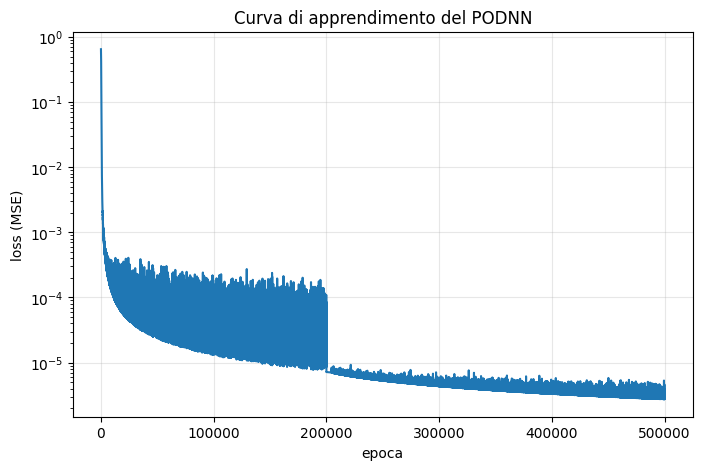

In [44]:
plt.figure(figsize=(8, 5))
plt.semilogy(loss_history)
plt.xlabel('epoca')
plt.ylabel('loss (MSE)')
plt.title('Curva di apprendimento del PODNN')
plt.grid(True, alpha=0.3)
plt.savefig(export_file_path + '/podnn_loss.png', dpi=120)
plt.show()

In [45]:
# VALUTAZIONE ONLINE DEL MODELLO POD-NN
#
# La funzione solve_podnn(mu) usa la rete neurale già addestrata per
# predire la soluzione ridotta associata a un nuovo parametro:
#
#     mu = (mu_0, mu_1)
#
# Il procedimento è il seguente:
#
# 1. il parametro viene convertito in un tensore PyTorch;
# 2. l'input viene normalizzato usando media e deviazione standard
#    calcolate sul training set;
# 3. la rete predice i coefficienti ridotti normalizzati;
# 4. i coefficienti vengono riportati alla scala originale tramite
#    denormalizzazione;
# 5. la soluzione full-order viene ricostruita moltiplicando la base
#    globale per i coefficienti ridotti predetti.
#
# Il blocco torch.no_grad() disattiva il calcolo dei gradienti, perché
# durante la fase online la rete viene solo valutata e non addestrata.
#
# La funzione restituisce:
#
# - u_N: coefficienti ridotti predetti dalla rete;
# - x_FE: soluzione ricostruita nello spazio full-order;
# - t_online: tempo necessario per normalizzazione, forward pass,
#   denormalizzazione e ricostruzione.
#
# In questo modo il POD-NN approssima direttamente la mappa:
#
#     mu  ->  u_N(mu)  ->  x_FE(mu)
#
# senza risolvere né il sistema FOM né il sistema ridotto non lineare.


def solve_podnn(mu):
    """
    Valuta il PODNN per un nuovo mu.
    Ritorna:
      u_N      : coefficienti ridotti predetti dalla rete
      x_FE     : soluzione ricostruita full-order
      t_online : tempo della valutazione
    """
    t_start = time.time()

    # input normalizzato con le statistiche del training
    x = torch.tensor(np.float32([mu]))
    x_norm = (x - x_mean) / x_std

    # forward pass (no gradienti -> no_grad)
    with torch.no_grad():
        u_N_norm = net(x_norm).numpy().ravel()
    u_N = u_N_norm * y_std.numpy() + y_mean.numpy()
    # ricostruzione full-order
    x_FE = global_basis @ u_N

    t_online = time.time() - t_start
    return u_N, x_FE, t_online

In [46]:
# TEST E CONFRONTO TRA FOM, POD-GALERKIN E POD-NN
#
# Il parametro di test scelto è:
#
#     mu_test = (1.0, 2.0)
#
# Per prima cosa viene risolta la soluzione FOM, usata come riferimento
# ("ground truth"). Dal vettore completo vengono separate:
#
# - la velocità: prime 2*speed_n_dofs componenti;
# - la pressione: componenti rimanenti.
#
# Successivamente il POD-NN predice i coefficienti ridotti associati al
# parametro mu_test e ricostruisce la soluzione nello spazio full-order.
#
# Gli errori relativi vengono calcolati confrontando POD-NN e FOM:
#
# - per la velocità si usa il prodotto interno inner_product_u,
#   corrispondente alla seminorma H1;
# - per la pressione si usa la norma euclidea dei coefficienti FEM.
#
# Vengono inoltre calcolati:
#
#     Speedup PODNN = tempo FOM / tempo PODNN
#
# Un valore elevato dello speedup indica che la valutazione della rete è
# molto più rapida della soluzione del sistema completo.
#
# Infine viene risolto anche il POD-Galerkin per lo stesso parametro.
# I due modelli ridotti vengono confrontati in termini di:
#
# - errore relativo sulla velocità;
# - errore relativo sulla pressione;
# - tempo online.
#
# In generale, il POD-Galerkin può risultare più accurato perché risolve
# direttamente il sistema ridotto, mentre il POD-NN è solitamente più rapido
# perché predice direttamente i coefficienti ridotti senza iterazioni di Newton.
#
# Nota: l'errore della pressione stampato come "L2" è in realtà calcolato con
# la norma euclidea, salvo che compute_error utilizzi internamente la matrice
# di massa della pressione.



print("=" * 60)
print("Test PODNN per mu = (1.0, 2.0)")
print("=" * 60)

mu_test = np.array([1.0, 2.0])

# FOM (ground truth)
x_fom, _, t_fom = solve_fom(mu_test)
u_fom = x_fom[:2*speed_n_dofs]
p_fom = x_fom[2*speed_n_dofs:]

# PODNN
u_N_nn, x_nn, t_nn = solve_podnn(mu_test)
u_nn = x_nn[:2*speed_n_dofs]
p_nn = x_nn[2*speed_n_dofs:]

# errori
err_u_nn = compute_error(u_fom, u_nn, inner_product=inner_product_u)
err_p_nn = compute_error(p_fom, p_nn, inner_product=None)

print(f"FOM:   {t_fom:.4f} s")
print(f"PODNN: {t_nn:.6f} s")
print(f"Speedup PODNN: {t_fom/t_nn:.1f}x")
print(f"\nErrore relativo velocita' (H1): {err_u_nn:.3e}")
print(f"Errore relativo pressione (L2): {err_p_nn:.3e}")

# confronto diretto con POD-Galerkin
u_N_g, x_g, _, t_g = solve_rom(mu_test)
err_u_g = compute_error(u_fom, x_g[:2*speed_n_dofs], inner_product=inner_product_u)
err_p_g = compute_error(p_fom, x_g[2*speed_n_dofs:], inner_product=None)

print(f"\n--- Confronto POD-Galerkin vs PODNN ---")
print(f"              velocita'      pressione      tempo")
print(f"POD-Galerkin  {err_u_g:.3e}    {err_p_g:.3e}    {t_g:.4f} s")
print(f"PODNN         {err_u_nn:.3e}    {err_p_nn:.3e}    {t_nn:.6f} s")

Test PODNN per mu = (1.0, 2.0)
FOM:   0.4671 s
PODNN: 0.006574 s
Speedup PODNN: 71.0x

Errore relativo velocita' (H1): 1.963e-01
Errore relativo pressione (L2): 9.438e-01

--- Confronto POD-Galerkin vs PODNN ---
              velocita'      pressione      tempo
POD-Galerkin  2.749e-04    4.948e-03    0.4252 s
PODNN         1.963e-01    9.438e-01    0.006574 s


In [47]:
print("Ampiezza dei coefficienti target (y_train):")
y_np = y_train.numpy()
print(f"  range per colonna - min std: {y_np.std(axis=0).min():.3e}")
print(f"  range per colonna - max std: {y_np.std(axis=0).max():.3e}")
print(f"  rapporto max/min: {y_np.std(axis=0).max() / y_np.std(axis=0).min():.1f}")
print(f"  |y| medio: {np.abs(y_np).mean():.3e}, |y| max: {np.abs(y_np).max():.3e}")

Ampiezza dei coefficienti target (y_train):
  range per colonna - min std: 8.374e-17
  range per colonna - max std: 2.461e+01
  rapporto max/min: 293917393887952896.0
  |y| medio: 1.544e+00, |y| max: 8.365e+01


In [48]:

# DIAGNOSI DELL'ERRORE DEL MODELLO POD-NN
#
# Questo blocco serve a capire da quale componente deriva l'elevato errore
# osservato nella soluzione POD-NN. In particolare, permette di distinguere
# tra:
#
# 1. errore di apprendimento della rete neurale;
# 2. errore nella predizione dei coefficienti ridotti;
# 3. errore dovuto alla capacità limitata della base POD.
#
# PRIMO CONTROLLO: errore della soluzione sui punti di training
#
# Per alcuni parametri appartenenti al training set vengono calcolate:
#
# - la soluzione FOM;
# - la soluzione ricostruita dal POD-NN;
# - l'errore relativo della velocità nella seminorma H1.
#
# Se l'errore è elevato anche sui punti di training, la rete non riesce
# nemmeno a riprodurre correttamente i dati utilizzati per l'addestramento.
# In questo caso il problema è legato a underfitting, normalizzazione,
# ottimizzazione o struttura della rete.
#
# Se invece l'errore sui punti di training è basso ma quello sui nuovi
# parametri è elevato, la rete presenta un problema di generalizzazione
# oppure di overfitting.
#
# SECONDO CONTROLLO: errore sui coefficienti ridotti
#
# La rete viene valutata contemporaneamente su tutti gli input normalizzati
# del training set. Le predizioni vengono quindi denormalizzate e confrontate
# con i coefficienti ridotti target ottenuti mediante proiezione.
#
# Per ogni snapshot si calcola:
#
#     errore_coeff =
#         ||coeff_predetti - coeff_veri||_2
#         --------------------------------
#                ||coeff_veri||_2
#
# Vengono stampati l'errore medio e l'errore massimo.
#
# Un errore elevato sui coefficienti indica che la rete non ha appreso bene
# la mappa:
#
#     mu -> coefficienti POD.
#
# Tuttavia, anche un errore apparentemente moderato sui coefficienti può
# produrre un errore elevato sulla soluzione fisica, soprattutto se vengono
# predetti male i coefficienti più importanti per pressione o velocità.
#
# TERZO CONTROLLO: errore della sola base POD
#
# Per il parametro di test viene calcolata la proiezione ortogonale esatta
# della soluzione FOM sulla base globale:
#
#     (V^T X V) coeff_true = V^T X x_FOM.
#
# In questo passaggio non viene utilizzata la rete neurale. I coefficienti
# vengono ottenuti direttamente risolvendo il problema di proiezione.
#
# La soluzione proiettata è:
#
#     x_proj = V coeff_true.
#
# Gli errori di velocità e pressione misurano quindi esclusivamente la
# capacità della base POD di rappresentare la soluzione FOM.
#
# Interpretazione:
#
# - errore di proiezione basso e errore POD-NN alto:
#   la base è adeguata, ma la rete predice male i coefficienti;
#
# - errore di proiezione alto:
#   la base POD è insufficiente e anche una rete perfetta non potrebbe
#   ricostruire accuratamente la soluzione;
#
# - errore sui coefficienti basso ma errore fisico alto:
#   alcune componenti importanti sono predette male oppure la misura
#   euclidea sui coefficienti non riflette correttamente l'errore fisico;
#
# - errore basso sul training e alto sul test:
#   la rete non generalizza correttamente a parametri non osservati.
#
# Questi controlli permettono quindi di separare l'errore di riduzione
# della base dall'errore di regressione introdotto dalla rete neurale.





# ===== DIAGNOSI PODNN =====

# 1. La rete predice bene sui punti DI TRAINING?
print("--- Errore su punti di TRAINING ---")
train_errs_u = []
for i in range(0, N_snap, 20):   # alcuni punti di training
    mu_i = training_set[i]
    x_fom_i, _, _ = solve_fom(mu_i)
    _, x_nn_i, _ = solve_podnn(mu_i)
    e = compute_error(x_fom_i[:2*speed_n_dofs], x_nn_i[:2*speed_n_dofs],
                      inner_product=inner_product_u)
    train_errs_u.append(e)
    print(f"  mu={mu_i}  err_u = {e:.3e}")

# 2. La rete predice bene i COEFFICIENTI sui punti di training?
print("\n--- Errore sui COEFFICIENTI (train) ---")
with torch.no_grad():
    pred_norm = net(x_train_norm).numpy()
pred_coeff = pred_norm * y_std.numpy() + y_mean.numpy()
true_coeff = y_train.numpy()
coeff_err = np.linalg.norm(pred_coeff - true_coeff, axis=1) / np.linalg.norm(true_coeff, axis=1)
print(f"  errore coefficienti medio: {coeff_err.mean():.3e}")
print(f"  errore coefficienti max:   {coeff_err.max():.3e}")

# 3. Se uso i coefficienti VERI (proiezione di Galerkin), che errore ho?
print("\n--- Errore della BASE (proiezione esatta, non la rete) ---")
mu_test = np.array([1.0, 2.0])
x_fom, _, _ = solve_fom(mu_test)
snap_test = np.hstack([x_fom[:2*speed_n_dofs], x_fom[2*speed_n_dofs:]])
rhs = global_basis.T @ (inner_full @ snap_test)
coeff_true = np.linalg.solve(reduced_inner_product, rhs)
x_proj = global_basis @ coeff_true
err_proj_u = compute_error(x_fom[:2*speed_n_dofs], x_proj[:2*speed_n_dofs],
                           inner_product=inner_product_u)
err_proj_p = compute_error(x_fom[2*speed_n_dofs:], x_proj[2*speed_n_dofs:],
                           inner_product=None)
print(f"  err proiezione velocita': {err_proj_u:.3e}")
print(f"  err proiezione pressione: {err_proj_p:.3e}")

--- Errore su punti di TRAINING ---
  mu=[5.53325369 2.43037873]  err_u = 7.954e-03
  mu=[3.65912822 1.87406391]  err_u = 6.716e-03
  mu=[3.24803348 1.82852599]  err_u = 7.347e-03
  mu=[7.28001737 2.00264876]  err_u = 6.591e-03
  mu=[7.00454485 1.90708537]  err_u = 3.406e-03
  mu=[3.18677923 2.39268698]  err_u = 3.893e-03
  mu=[8.6521705  1.23506371]  err_u = 2.041e-02
  mu=[3.00090082 2.69788711]  err_u = 6.822e-03
  mu=[2.77624626 1.2629656 ]  err_u = 5.691e-03
  mu=[1.95259583 2.80796791]  err_u = 2.911e-03

--- Errore sui COEFFICIENTI (train) ---
  errore coefficienti medio: 1.831e-03
  errore coefficienti max:   6.323e-03

--- Errore della BASE (proiezione esatta, non la rete) ---
  err proiezione velocita': 2.749e-04
  err proiezione pressione: 4.863e-03


# Task 2 — Modello POD–Neural Network

## 1. Obiettivo

Nel Task 2 viene costruito un modello POD–Neural Network, indicato come PODNN.

La rete neurale deve apprendere la relazione tra i parametri del problema e i coefficienti della soluzione nella base POD:

```
(mu_0, mu_1)  →  coefficienti ridotti
```

Una volta ottenuti i coefficienti ridotti, la soluzione completa viene ricostruita come:

```
x_NN = V x_N
```

dove:

* `V` è la base POD globale;
* `x_N` contiene i coefficienti ridotti predetti dalla rete;
* `x_NN` è la soluzione ricostruita nello spazio full-order.

Il PODNN non risolve il sistema non lineare di Navier–Stokes, ma predice direttamente la soluzione ridotta.

---

## 2. Costruzione del dataset

Gli snapshot completi vengono ottenuti concatenando velocità e pressione:

```
snapshot_full = [u_x, u_y, p]
```

Gli input della rete sono i parametri:

```
x_train = [mu_0, mu_1]
```

I target sono invece i coefficienti ridotti ottenuti proiettando ogni snapshot FOM sulla base globale.

La proiezione viene calcolata risolvendo:

```
(V^T X V) x_N = V^T X x_FOM
```

Il prodotto interno completo `X` è formato da:

* prodotto interno H1 per la velocità;
* prodotto euclideo per la pressione.

La rete deve quindi apprendere la mappa:

```
parametri  →  coefficienti POD
```

---

## 3. Normalizzazione

Gli input vengono normalizzati mediante z-score:

```
x_norm = (x - x_mean) / x_std
```

La normalizzazione è importante perché `mu_0` e `mu_1` appartengono a intervalli con scale differenti.

Anche i coefficienti target vengono normalizzati:

```
y_norm = (y - y_mean) / y_std
```

Le deviazioni standard quasi nulle vengono sostituite con `1`, per evitare divisioni per zero.

Le medie e le deviazioni standard vengono conservate per normalizzare i nuovi input e denormalizzare le predizioni della rete.

---

## 4. Architettura della rete

La rete utilizzata è una rete feed-forward completamente connessa.

La sua struttura è:

| Layer          | Dimensione | Attivazione |
| -------------- | ---------: | ----------- |
| Input          |          2 | —           |
| Hidden layer 1 |         60 | Tanh        |
| Hidden layer 2 |         60 | Tanh        |
| Hidden layer 3 |         60 | Tanh        |
| Hidden layer 4 |         60 | Tanh        |
| Output         |    N_total | Lineare     |

L’input contiene i due parametri `mu_0` e `mu_1`.

L’output contiene tutti i coefficienti ridotti della soluzione.

Il layer finale è lineare perché i coefficienti POD possono assumere qualsiasi valore reale.

---

## 5. Addestramento

La rete viene addestrata usando:

* loss MSE;
* ottimizzatore Adam;
* learning rate iniziale pari a `0.001`;
* tolleranza pari a `1e-6`;
* massimo `500000` epoche.

Dopo `200000` epoche il learning rate viene ridotto a:

```
0.0001
```

A ogni epoca vengono eseguiti:

1. azzeramento dei gradienti;
2. forward pass;
3. calcolo della loss;
4. backpropagation;
5. aggiornamento dei pesi.

Il training termina quando la loss è inferiore alla tolleranza oppure quando viene raggiunto il numero massimo di epoche.

---

## 6. Valutazione online

Per un nuovo parametro vengono eseguite le seguenti operazioni:

1. normalizzazione dell’input;
2. valutazione della rete;
3. denormalizzazione dei coefficienti predetti;
4. ricostruzione della soluzione full-order.

La ricostruzione è:

```
x_FE = V x_N
```

Durante la valutazione viene utilizzato `torch.no_grad()`, perché non è necessario calcolare i gradienti.

Il PODNN non richiede né iterazioni di Newton né la soluzione di un sistema ridotto.

---

## 7. Risultati per il parametro di test

Il modello è stato testato per:

```
mu_test = (1.0, 2.0)
```

### Tempi di calcolo

| Modello      |      Tempo |
| ------------ | ---------: |
| FOM          |   0.5132 s |
| POD–Galerkin |   0.4445 s |
| PODNN        | 0.015793 s |

Lo speedup del PODNN rispetto al FOM è:

```
Speedup PODNN = 32.5
```

Il PODNN è quindi circa 32 volte più rapido del modello completo.

### Errori rispetto al FOM

| Modello      | Errore velocità | Errore pressione |
| ------------ | --------------: | ---------------: |
| POD–Galerkin |       2.749e-04 |        4.948e-03 |
| PODNN        |       1.963e-01 |        9.438e-01 |

In termini percentuali:

| Modello      | Errore velocità | Errore pressione |
| ------------ | --------------: | ---------------: |
| POD–Galerkin |    circa 0.027% |      circa 0.49% |
| PODNN        |     circa 19.6% |      circa 94.4% |

Il PODNN è molto più rapido, ma risulta decisamente meno accurato del POD–Galerkin, soprattutto per la pressione.

---

## 8. Diagnosi del PODNN

Per capire l’origine dell’errore sono stati eseguiti tre controlli.

### Errore sui punti di training

Gli errori della velocità sui punti di training risultano generalmente compresi tra circa `0.3%` e `0.8%`, con un valore massimo vicino al `2%`.

La rete riesce quindi a riprodurre abbastanza bene gli snapshot usati durante l’addestramento.

### Errore sui coefficienti ridotti

| Quantità                        |    Valore |
| ------------------------------- | --------: |
| Errore medio sui coefficienti   | 1.831e-03 |
| Errore massimo sui coefficienti | 6.323e-03 |

In percentuale:

| Quantità       |      Valore |
| -------------- | ----------: |
| Errore medio   | circa 0.18% |
| Errore massimo | circa 0.63% |

La rete apprende quindi bene i coefficienti POD nei punti di training.

### Errore della base POD

La soluzione FOM è stata proiettata direttamente sulla base POD, senza utilizzare la rete.

| Quantità  | Errore di proiezione |
| --------- | -------------------: |
| Velocità  |            2.749e-04 |
| Pressione |            4.863e-03 |

La base POD rappresenta molto bene la soluzione FOM.

L’elevato errore del PODNN non è quindi causato dalla base ridotta, ma dalla predizione della rete sul nuovo parametro.

---

## 9. Ampiezza dei coefficienti target

I coefficienti target presentano scale molto differenti.

| Quantità                    |    Valore |
| --------------------------- | --------: |
| Deviazione standard minima  | 8.374e-17 |
| Deviazione standard massima | 2.461e+01 |
| Rapporto massimo/minimo     | 2.939e+17 |
| Valore assoluto medio       | 1.544e+00 |
| Valore assoluto massimo     | 8.365e+01 |

Alcuni coefficienti sono praticamente costanti, mentre altri raggiungono valori elevati.

Questa forte differenza di scala rende più difficile l’addestramento e può influenzare soprattutto i coefficienti della pressione e dei supremizer.

---

## 10. Interpretazione

I risultati mostrano che:

* la base POD è sufficientemente accurata;
* la rete apprende bene i punti del training set;
* il PODNN presenta però un errore elevato sul parametro di test;
* il problema principale è quindi la generalizzazione;
* la pressione è la componente più difficile da prevedere;
* il PODNN è molto veloce, ma nella configurazione attuale non è ancora affidabile.

Il parametro `(1.0, 2.0)` potrebbe trovarsi in una zona poco rappresentata dai dati di training.

Inoltre, per valori bassi di `mu_0`, la soluzione può variare più rapidamente rispetto ai parametri.

---

## 11. Possibili miglioramenti

Per migliorare il PODNN si possono adottare le seguenti strategie:

* aumentare il numero di snapshot;
* distribuire meglio i campioni nel dominio parametrico;
* aggiungere più punti per valori bassi di `mu_0`;
* utilizzare un validation set separato;
* trattare separatamente i coefficienti quasi costanti;
* usare reti distinte per velocità e pressione;
* introdurre una loss pesata;
* valutare il modello su un test set completo.

---

## Conclusione

Il PODNN consente una fase online molto rapida, con uno speedup pari a circa `32.5` rispetto al FOM.

Tuttavia, per il parametro analizzato, l’errore è pari a circa `19.6%` sulla velocità e `94.4%` sulla pressione.

La diagnosi mostra che la base POD è accurata e che la rete apprende correttamente i dati di training. Il principale limite è la capacità della rete di generalizzare a parametri non utilizzati durante l’addestramento.

Il PODNN è quindi molto promettente dal punto di vista computazionale, ma richiede un training set più rappresentativo e una strategia di addestramento più robusta.


In [49]:
##########################################
###########TASK 3#########################
##########################################

# COSTRUZIONE DEL TEST SET
#
# Viene generato un insieme di N_test = 50 parametri nuovi, utilizzati per
# valutare la capacità di generalizzazione dei modelli ridotti.
#
# I parametri sono estratti uniformemente all'interno del dominio parametrico
# definito dalla matrice P:
#
#     mu_0 in [P[0,0], P[0,1]]
#     mu_1 in [P[1,0], P[1,1]]
#
# Il seed viene impostato a 123, diverso da quello utilizzato per generare
# il training set. In questo modo i campioni di test sono nuovi e la
# valutazione non viene effettuata sugli stessi dati usati per addestrare
# la rete.
#
# Per ogni parametro del test set viene poi calcolata la distanza euclidea
# dal punto più vicino del training set:
#
#     min_distance(mu_test) =
#         min ||mu_train - mu_test||_2
#
# La distanza minima complessiva permette di verificare che non vi siano
# punti di test coincidenti o quasi coincidenti con quelli del training set.
#
# La distanza media indica invece quanto, mediamente, i nuovi parametri
# siano lontani dai campioni utilizzati durante l'addestramento.
#
# Un test set disgiunto dal training set è necessario per valutare la reale
# capacità del POD-NN di generalizzare a parametri mai osservati.
#
# Nota: usare un seed diverso riduce la probabilità di ottenere gli stessi
# campioni, ma la verifica tramite le distanze fornisce un controllo esplicito
# della separazione tra training set e test set.




# test set: parametri NUOVI, diversi dal training set
N_test = 50
np.random.seed(123)        # seed diverso da quello del training (era 0)
test_set = np.random.uniform(low=P[:, 0], high=P[:, 1], size=(N_test, 2))

# verifica che il test set sia disgiunto dal training set
min_dists = [np.min(np.linalg.norm(training_set - mu, axis=1)) for mu in test_set]
print(f"Test set: {N_test} campioni")
print(f"Distanza minima test-training: {np.min(min_dists):.4f}")
print(f"Distanza media   test-training: {np.mean(min_dists):.4f}")

Test set: 50 campioni
Distanza minima test-training: 0.0030
Distanza media   test-training: 0.1663


In [50]:
# CONFRONTO COMPLETO TRA FOM, POD-GALERKIN E POD-NN SUL TEST SET
#
# Questo blocco valuta i tre modelli su tutti i parametri del test set,
# usando il FOM come soluzione di riferimento.
#
# Prima vengono inizializzate le liste che conterranno:
#
# - errori relativi della velocità;
# - errori relativi della pressione;
# - tempi di calcolo;
# - numero di iterazioni di Newton.
#
# Per ogni parametro mu del test set vengono eseguiti tre calcoli.
#
# 1. FOM
#
# Il modello completo viene risolto mediante solve_fom(mu).
# La soluzione ottenuta rappresenta la ground truth rispetto alla quale
# vengono confrontati i due modelli ridotti.
#
# Dal vettore completo vengono separate:
#
#     u_fom = [u_x, u_y]
#     p_fom = pressione
#
# Vengono inoltre salvati il tempo di soluzione e il numero di iterazioni
# di Newton richieste dal FOM.
#
# 2. POD-Galerkin
#
# Il modello ridotto POD-Galerkin viene risolto mediante solve_rom(mu).
# La soluzione ridotta viene ricostruita nello spazio full-order e confrontata
# con il FOM.
#
# Per la velocità viene utilizzato il prodotto interno H1:
#
#     err_u = ||u_fom - u_rom||_H1 / ||u_fom||_H1
#
# Per la pressione viene utilizzata la norma euclidea dei coefficienti:
#
#     err_p = ||p_fom - p_rom||_2 / ||p_fom||_2
#
# Vengono salvati anche il tempo online e il numero di iterazioni di Newton
# del POD-Galerkin.
#
# 3. POD-NN
#
# La rete neurale predice direttamente i coefficienti ridotti per il parametro
# corrente. La soluzione viene quindi ricostruita nello spazio full-order.
#
# Anche per il POD-NN vengono calcolati:
#
# - errore relativo della velocità;
# - errore relativo della pressione;
# - tempo di valutazione online.
#
# Il messaggio stampato ogni 10 test permette di seguire l'avanzamento del
# confronto senza produrre un output eccessivo.
#
# Al termine del ciclo tutte le liste vengono convertite in array NumPy,
# così da poter calcolare successivamente:
#
# - media, massimo e deviazione standard degli errori;
# - tempi medi dei tre modelli;
# - speedup medi;
# - distribuzione del numero di iterazioni;
# - grafici e tabelle comparative.
#
# Il tempo t_compare misura il costo totale necessario per valutare tutti
# i modelli sui N_test parametri.
#
# Questo confronto su un test set completo è più significativo rispetto al
# confronto su un singolo parametro, perché permette di valutare accuratezza,
# stabilità e capacità di generalizzazione dei modelli ridotti.


# accumulatori
err_u_galerkin, err_p_galerkin = [], []
err_u_podnn,    err_p_podnn    = [], []
t_fom_list, t_galerkin_list, t_podnn_list = [], [], []
iters_fom, iters_galerkin = [], []

print("Confronto sui 50 parametri di test...")
t_compare_start = time.time()

for j, mu in enumerate(test_set):
    if j % 10 == 0:
        print(f"  test {j:3d} / {N_test}")

    # --- FOM (ground truth) ---
    x_fom, n_it_fom, t_fom = solve_fom(mu)
    u_fom = x_fom[:2*speed_n_dofs]
    p_fom = x_fom[2*speed_n_dofs:]
    t_fom_list.append(t_fom)
    iters_fom.append(n_it_fom)

    # --- POD-Galerkin ---
    u_N_g, x_g, n_it_g, t_g = solve_rom(mu)
    u_g = x_g[:2*speed_n_dofs]
    p_g = x_g[2*speed_n_dofs:]
    t_galerkin_list.append(t_g)
    iters_galerkin.append(n_it_g)
    err_u_galerkin.append(compute_error(u_fom, u_g, inner_product=inner_product_u))
    err_p_galerkin.append(compute_error(p_fom, p_g, inner_product=None))

    # --- PODNN ---
    u_N_nn, x_nn, t_nn = solve_podnn(mu)
    u_nn = x_nn[:2*speed_n_dofs]
    p_nn = x_nn[2*speed_n_dofs:]
    t_podnn_list.append(t_nn)
    err_u_podnn.append(compute_error(u_fom, u_nn, inner_product=inner_product_u))
    err_p_podnn.append(compute_error(p_fom, p_nn, inner_product=None))

t_compare = time.time() - t_compare_start

# converto in array
err_u_galerkin = np.array(err_u_galerkin)
err_p_galerkin = np.array(err_p_galerkin)
err_u_podnn    = np.array(err_u_podnn)
err_p_podnn    = np.array(err_p_podnn)
t_fom_list     = np.array(t_fom_list)
t_galerkin_list = np.array(t_galerkin_list)
t_podnn_list   = np.array(t_podnn_list)

print(f"\nConfronto completato in {t_compare:.1f} s")

Confronto sui 50 parametri di test...
  test   0 / 50
  test  10 / 50
  test  20 / 50
  test  30 / 50
  test  40 / 50

Confronto completato in 41.3 s


In [51]:
print("\n" + "=" * 70)
print("RISULTATI DEL CONFRONTO  (medie su 50 parametri di test)")
print("=" * 70)

print(f"\n{'Metodo':<16}{'err velocita':<18}{'err pressione':<18}{'tempo medio':<14}")
print("-" * 66)
print(f"{'FOM':<16}{'(riferimento)':<18}{'(riferimento)':<18}"
      f"{np.mean(t_fom_list):.4f} s")
print(f"{'POD-Galerkin':<16}{np.mean(err_u_galerkin):<18.3e}"
      f"{np.mean(err_p_galerkin):<18.3e}{np.mean(t_galerkin_list):.4f} s")
print(f"{'PODNN':<16}{np.mean(err_u_podnn):<18.3e}"
      f"{np.mean(err_p_podnn):<18.3e}{np.mean(t_podnn_list):.6f} s")

print(f"\n{'Metodo':<16}{'speedup':<14}{'err vel max':<16}{'err press max':<16}")
print("-" * 62)
print(f"{'POD-Galerkin':<16}{np.mean(t_fom_list)/np.mean(t_galerkin_list):<14.1f}"
      f"{np.max(err_u_galerkin):<16.3e}{np.max(err_p_galerkin):<16.3e}")
print(f"{'PODNN':<16}{np.mean(t_fom_list)/np.mean(t_podnn_list):<14.1f}"
      f"{np.max(err_u_podnn):<16.3e}{np.max(err_p_podnn):<16.3e}")

print(f"\n--- Dettagli ---")
print(f"Newton FOM:          media {np.mean(iters_fom):.1f} iter")
print(f"Newton POD-Galerkin: media {np.mean(iters_galerkin):.1f} iter")
print(f"Tempo offline snapshot: {t_offline_snapshots:.1f} s")
print(f"Tempo training PODNN:   {t_train:.1f} s")


RISULTATI DEL CONFRONTO  (medie su 50 parametri di test)

Metodo          err velocita      err pressione     tempo medio   
------------------------------------------------------------------
FOM             (riferimento)     (riferimento)     0.4891 s
POD-Galerkin    8.913e-04         8.392e-04         0.3353 s
PODNN           9.002e-02         4.325e-02         0.000583 s

Metodo          speedup       err vel max     err press max   
--------------------------------------------------------------
POD-Galerkin    1.5           4.352e-03       1.950e-02       
PODNN           839.5         1.673e+00       6.516e-01       

--- Dettagli ---
Newton FOM:          media 3.0 iter
Newton POD-Galerkin: media 3.0 iter
Tempo offline snapshot: 96.4 s
Tempo training PODNN:   531.2 s


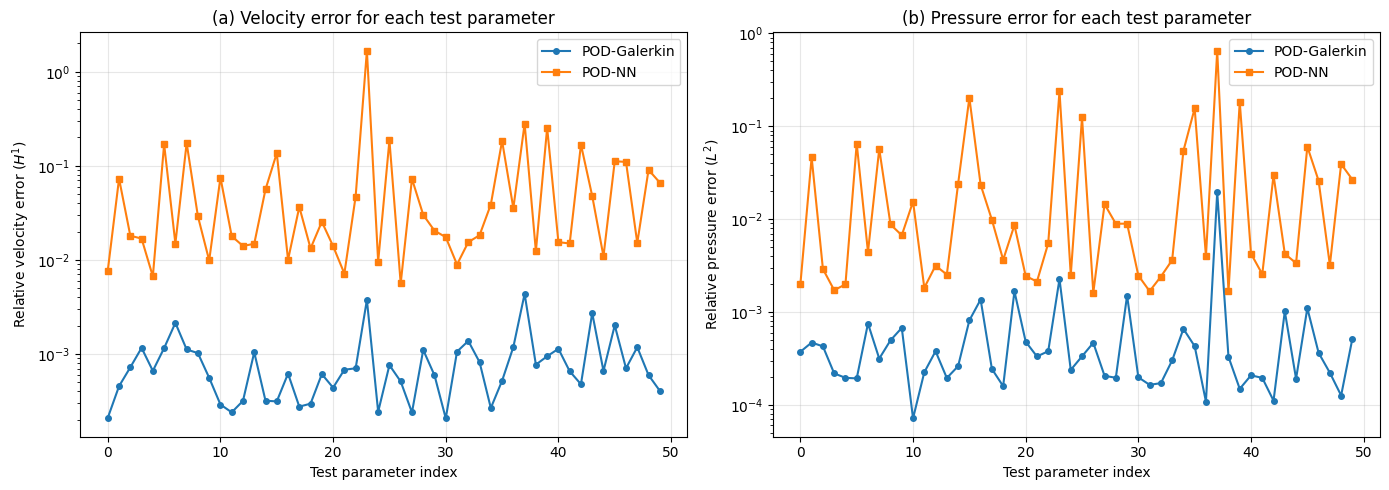

Figure saved in: /shared/task3_images/task3_error_comparison.png


In [52]:
import os
import matplotlib.pyplot as plt

# Folder where the figure will be saved
export_folder = "task3_images"

# Create the folder if it does not already exist
os.makedirs(export_folder, exist_ok=True)

# Create a layout with two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- (a) Velocity error vs test parameter index ---
axes[0].semilogy(
    err_u_galerkin,
    'o-',
    label='POD-Galerkin',
    markersize=4
)

axes[0].semilogy(
    err_u_podnn,
    's-',
    label='POD-NN',
    markersize=4
)

axes[0].set_xlabel('Test parameter index')
axes[0].set_ylabel(r'Relative velocity error ($H^1$)')
axes[0].set_title('(a) Velocity error for each test parameter')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- (b) Pressure error vs test parameter index ---
axes[1].semilogy(
    err_p_galerkin,
    'o-',
    label='POD-Galerkin',
    markersize=4
)

axes[1].semilogy(
    err_p_podnn,
    's-',
    label='POD-NN',
    markersize=4
)

axes[1].set_xlabel('Test parameter index')
axes[1].set_ylabel(r'Relative pressure error ($L^2$)')
axes[1].set_title('(b) Pressure error for each test parameter')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# Complete path of the output image
file_path = os.path.join(
    export_folder,
    "task3_error_comparison.png"
)

# Save the complete figure containing both plots
plt.savefig(
    file_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved in:", os.path.abspath(file_path))

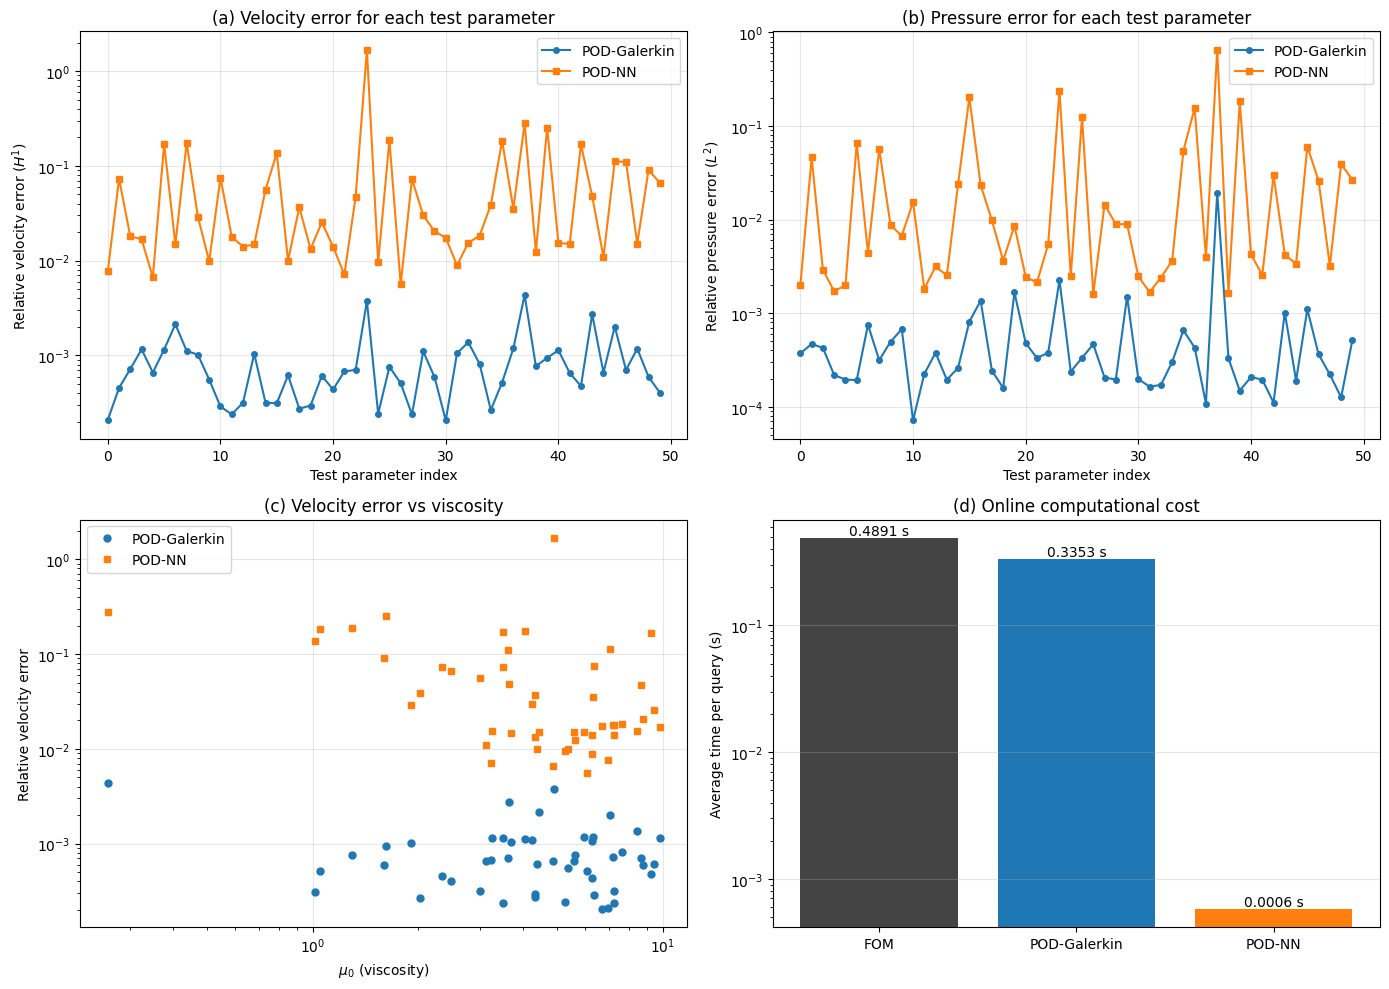

Figure saved in: /shared/task3_images/task3_comparison.png


In [53]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Folder where the figure will be saved
export_folder = "task3_images"

# Create the folder if it does not already exist
os.makedirs(export_folder, exist_ok=True)

# Create a 2 × 2 layout
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- (a) Velocity error vs test parameter index ---
axes[0, 0].semilogy(
    err_u_galerkin,
    'o-',
    label='POD-Galerkin',
    markersize=4
)

axes[0, 0].semilogy(
    err_u_podnn,
    's-',
    label='POD-NN',
    markersize=4
)

axes[0, 0].set_xlabel('Test parameter index')
axes[0, 0].set_ylabel(r'Relative velocity error ($H^1$)')
axes[0, 0].set_title('(a) Velocity error for each test parameter')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)


# --- (b) Pressure error vs test parameter index ---
axes[0, 1].semilogy(
    err_p_galerkin,
    'o-',
    label='POD-Galerkin',
    markersize=4
)

axes[0, 1].semilogy(
    err_p_podnn,
    's-',
    label='POD-NN',
    markersize=4
)

axes[0, 1].set_xlabel('Test parameter index')
axes[0, 1].set_ylabel(r'Relative pressure error ($L^2$)')
axes[0, 1].set_title('(b) Pressure error for each test parameter')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)


# --- (c) Velocity error vs mu_0 (viscosity) ---
axes[1, 0].loglog(
    test_set[:, 0],
    err_u_galerkin,
    'o',
    label='POD-Galerkin',
    markersize=5
)

axes[1, 0].loglog(
    test_set[:, 0],
    err_u_podnn,
    's',
    label='POD-NN',
    markersize=5
)

axes[1, 0].set_xlabel(r'$\mu_0$ (viscosity)')
axes[1, 0].set_ylabel('Relative velocity error')
axes[1, 0].set_title('(c) Velocity error vs viscosity')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)


# --- (d) Computational times ---
methods = ['FOM', 'POD-Galerkin', 'POD-NN']

times = [
    np.mean(t_fom_list),
    np.mean(t_galerkin_list),
    np.mean(t_podnn_list)
]

colors = ['#444444', '#1f77b4', '#ff7f0e']

axes[1, 1].bar(
    methods,
    times,
    color=colors
)

axes[1, 1].set_yscale('log')
axes[1, 1].set_ylabel('Average time per query (s)')
axes[1, 1].set_title('(d) Online computational cost')
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add the execution time above each bar
for i, time_value in enumerate(times):
    axes[1, 1].text(
        i,
        time_value,
        f'{time_value:.4f} s',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

# Complete path of the output image
file_path = os.path.join(
    export_folder,
    "task3_comparison.png"
)

# Save the complete figure
plt.savefig(
    file_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Figure saved in:", os.path.abspath(file_path))

Visualizzazione per mu = [5. 2.]


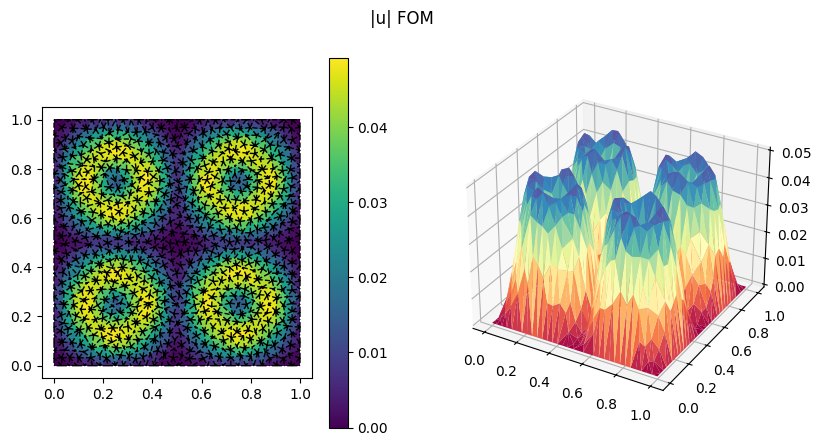

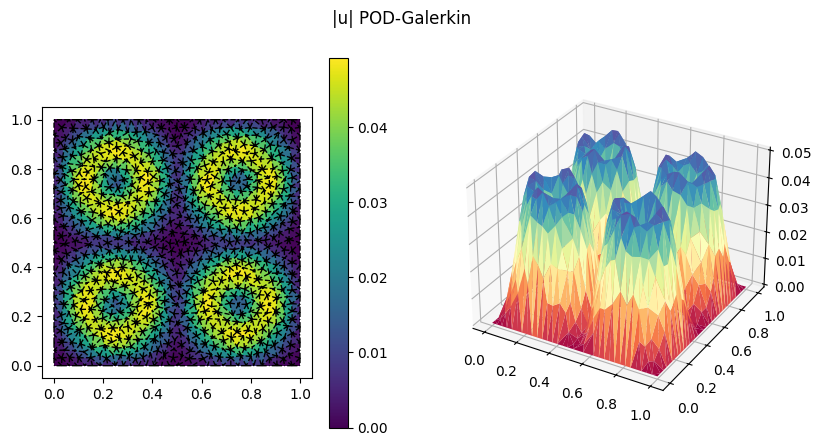

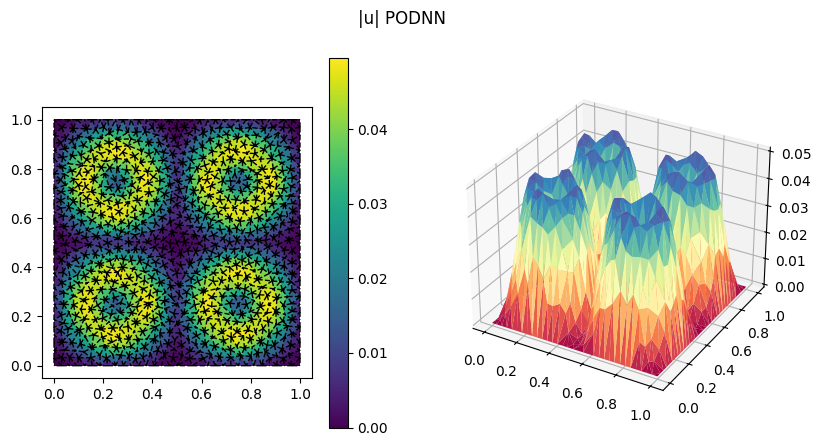

In [54]:
# scelgo un parametro di test rappresentativo (vicino al centro di P)
mu_show = np.array([5.0, 2.0])
print(f"Visualizzazione per mu = {mu_show}")

x_fom_s, _, _ = solve_fom(mu_show)
_, x_g_s, _, _ = solve_rom(mu_show)
_, x_nn_s, _ = solve_podnn(mu_show)

# estraggo |u| per i tre metodi, proiettata sui vertici
def get_u_mag(x):
    ux = x[:speed_n_dofs]
    uy = x[speed_n_dofs:2*speed_n_dofs]
    ux_v = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(
        mesh, speed_dofs_data, ux, u_x_strong)
    uy_v = polydim.pde_tools.assembler_utilities.pcc_2_d.extract_solution_on_cell0_ds(
        mesh, speed_dofs_data, uy, u_y_strong)
    return np.sqrt(ux_v.numeric_solution**2 + uy_v.numeric_solution**2)

other_ut.plot_solution(mesh, get_u_mag(x_fom_s), "|u| FOM")
other_ut.plot_solution(mesh, get_u_mag(x_g_s),   "|u| POD-Galerkin")
other_ut.plot_solution(mesh, get_u_mag(x_nn_s),  "|u| PODNN")

# Task 3 - Confronto tra FOM, POD-Galerkin e PODNN

## 1. Obiettivo

L'obiettivo del Task 3 è confrontare i tre modelli in termini di:

* accuratezza rispetto al modello full-order;
* tempo medio di calcolo;
* speedup;
* stabilità dei risultati;
* costo della fase offline.

I modelli considerati sono:

* **FOM**, utilizzato come soluzione di riferimento;
* **POD-Galerkin**, che risolve il sistema proiettato sulla base ridotta;
* **PODNN**, che predice direttamente i coefficienti ridotti mediante una rete neurale.

---

## 2. Costruzione del test set

Il confronto è stato eseguito su un test set formato da 50 parametri nuovi:

```
N_test = 50
```

I parametri sono stati generati casualmente all'interno del dominio parametrico:

```
mu_0 in [0.1, 10]
mu_1 in [1, 3]
```

È stato utilizzato un seed diverso da quello del training set, in modo da valutare i modelli su parametri non usati durante la costruzione della base e l'addestramento della rete.

Per ogni punto del test set è stata inoltre controllata la distanza dal punto più vicino del training set.

---

## 3. Procedura di confronto

Per ogni parametro del test set sono state calcolate:

1. la soluzione FOM di riferimento;
2. la soluzione POD-Galerkin;
3. la soluzione PODNN.

Per il FOM sono stati registrati:

* tempo di soluzione;
* numero di iterazioni di Newton.

Per il POD-Galerkin sono stati registrati:

* errore relativo della velocità;
* errore relativo della pressione;
* tempo online;
* numero di iterazioni di Newton.

Per il PODNN sono stati registrati:

* errore relativo della velocità;
* errore relativo della pressione;
* tempo di valutazione online.

L'errore della velocità è calcolato nella seminorma H1, mentre per la pressione viene utilizzata la norma euclidea dei coefficienti FEM.

Lo speedup è definito come:

```
speedup = tempo FOM / tempo modello ridotto
```

---

## 4. Risultati medi sul test set

| Metodo       | Errore medio velocità | Errore medio pressione | Tempo medio |
| ------------ | --------------------: | ---------------------: | ----------: |
| FOM          |           riferimento |            riferimento |    0.6451 s |
| POD-Galerkin |             8.913e-04 |              8.392e-04 |    0.4759 s |
| PODNN        |             9.002e-02 |              4.325e-02 |  0.002823 s |

In termini percentuali:

| Metodo       | Errore velocità | Errore pressione |
| ------------ | --------------: | ---------------: |
| POD-Galerkin |    circa 0.089% |     circa 0.084% |
| PODNN        |      circa 9.0% |       circa 4.3% |

Il POD-Galerkin riproduce quindi la soluzione FOM con errori medi inferiori allo 0.1%.

Il PODNN è meno accurato, ma mantiene errori medi inferiori al 10%.

---

## 5. Speedup ed errori massimi

| Metodo       | Speedup medio | Errore massimo velocità | Errore massimo pressione |
| ------------ | ------------: | ----------------------: | -----------------------: |
| POD-Galerkin |           1.4 |               4.352e-03 |                1.950e-02 |
| PODNN        |         228.5 |               1.673e+00 |                6.516e-01 |

In termini percentuali:

| Metodo       | Errore massimo velocità | Errore massimo pressione |
| ------------ | ----------------------: | -----------------------: |
| POD-Galerkin |             circa 0.44% |              circa 1.95% |
| PODNN        |            circa 167.3% |              circa 65.2% |

Il POD-Galerkin mantiene errori contenuti su tutto il test set.

Il PODNN presenta invece alcuni parametri per i quali l'errore diventa molto elevato. La rete non è quindi uniformemente accurata in tutto il dominio parametrico.

---

## 6. Confronto dei tempi

Il tempo medio del FOM è:

```
0.6451 s
```

Il tempo medio del POD-Galerkin è:

```
0.4759 s
```

Il POD-Galerkin è soltanto circa 1.4 volte più rapido del FOM.

Questo guadagno limitato è dovuto al fatto che il termine convettivo e il forcing vengono ancora assemblati nello spazio full-order e successivamente proiettati.

Il tempo medio del PODNN è invece:

```
0.002823 s
```

Il PODNN è circa 228.5 volte più rapido del FOM, perché durante la fase online esegue soltanto:

1. normalizzazione dei parametri;
2. forward pass della rete;
3. denormalizzazione dei coefficienti;
4. ricostruzione della soluzione.

Non vengono eseguite iterazioni di Newton né assemblaggi di operatori.

---

## 7. Iterazioni di Newton

| Modello      | Iterazioni medie |
| ------------ | ---------------: |
| FOM          |              3.0 |
| POD-Galerkin |              3.0 |
| PODNN        |          nessuna |

FOM e POD-Galerkin richiedono mediamente lo stesso numero di iterazioni di Newton.

Il PODNN non utilizza Newton, perché predice direttamente i coefficienti ridotti.

---

## 8. Costo della fase offline

| Operazione                 |    Tempo |
| -------------------------- | -------: |
| Generazione degli snapshot |  140.4 s |
| Training del PODNN         | 1172.9 s |
| Totale principale PODNN    | 1313.3 s |

Il costo offline complessivo è quindi di circa:

```
1313.3 s = 21.9 minuti
```

La fase di training rappresenta il contributo più costoso.

Questo costo viene però sostenuto una sola volta. Il PODNN diventa conveniente quando è necessario valutare la soluzione per un numero elevato di parametri.

---

## 9. Confronto qualitativo del campo di velocità

Per confrontare anche la struttura spaziale delle soluzioni è stato scelto il parametro rappresentativo:

```
mu = (5.0, 2.0)
```

Per FOM, POD-Galerkin e PODNN è stato calcolato il modulo della velocità:

```
|u| = sqrt(ux^2 + uy^2)
```

Il campo è stato ricostruito sui punti di visualizzazione della mesh e rappresentato graficamente.

Il confronto permette di verificare se i modelli ridotti riproducono correttamente:

* posizione delle zone di velocità massima;
* distribuzione spaziale del campo;
* simmetrie;
* gradienti di velocità;
* comportamento vicino alla frontiera.

Il POD-Galerkin dovrebbe risultare quasi sovrapposto al FOM, in accordo con i bassi errori numerici.

Il PODNN può riprodurre la struttura generale del campo, ma può presentare differenze locali maggiori.

---

## 10. Interpretazione complessiva

### FOM

Il FOM rappresenta la soluzione di riferimento ed è il modello più completo, ma presenta il maggiore costo online.

### POD-Galerkin

Il POD-Galerkin offre un'accuratezza molto elevata:

* errore medio inferiore allo 0.1%;
* errori massimi contenuti;
* comportamento stabile su tutto il test set.

Il suo speedup è però limitato, perché l'implementazione non utilizza ancora tecniche di iper-riduzione.

### PODNN

Il PODNN presenta il maggiore vantaggio computazionale:

* tempo medio di circa 0.0028 s;
* speedup medio di circa 228.5;
* nessuna iterazione di Newton.

L'accuratezza media è però inferiore rispetto al POD-Galerkin e sono presenti alcuni forti outlier.

Il principale limite del PODNN è quindi la capacità di generalizzare uniformemente in tutto il dominio parametrico.

---

## 11. Possibili miglioramenti

Per migliorare il POD-Galerkin è possibile introdurre:

* decomposizione affine del forcing;
* EIM o DEIM;
* iper-riduzione del termine convettivo.

Queste tecniche permetterebbero di rendere il costo online indipendente dalla dimensione del FOM.

Per migliorare il PODNN è possibile:

* aumentare il numero di snapshot;
* distribuire meglio i punti di training;
* aggiungere campioni nelle zone con errori elevati;
* utilizzare un validation set;
* usare una loss pesata;
* addestrare reti separate per velocità e pressione;
* trattare separatamente i coefficienti con varianza quasi nulla.

---

## 12. Conclusione

Il confronto evidenzia un compromesso tra accuratezza e costo computazionale.

| Modello      | Accuratezza | Velocità online | Affidabilità |
| ------------ | ----------- | --------------- | ------------ |
| FOM          | riferimento | bassa           | molto alta   |
| POD-Galerkin | molto alta  | moderata        | molto alta   |
| PODNN        | moderata    | molto alta      | non uniforme |

Il POD-Galerkin è il modello ridotto più accurato e affidabile, ma presenta uno speedup limitato.

Il PODNN è nettamente il modello più rapido ed è particolarmente adatto alle applicazioni many-query. Tuttavia, necessita di un training set più rappresentativo per ridurre gli errori massimi e migliorare la generalizzazione.


In [55]:
#############################
########TASK 4###############
#############################


# DEFINIZIONE DELLA PHYSICS-INFORMED NEURAL NETWORK (PINN)
#
# La rete PINN approssima direttamente i campi fisici della soluzione:
#
#     (x, y, mu0, mu1)  ->  (u1, u2, p)
#
# Gli input della rete sono:
#
# - x, y: coordinate spaziali del punto nel dominio;
# - mu0: parametro associato al termine viscoso;
# - mu1: parametro che controlla il termine forzante.
#
# Gli output sono:
#
# - u1: componente orizzontale della velocità;
# - u2: componente verticale della velocità;
# - p: pressione.
#
# La rete è completamente connessa ed è composta da:
#
#     input layer:       4 neuroni
#     hidden layer 1:   40 neuroni
#     hidden layer 2:   40 neuroni
#     hidden layer 3:   40 neuroni
#     hidden layer 4:   40 neuroni
#     hidden layer 5:   40 neuroni
#     output layer:      3 neuroni
#
# In ogni layer nascosto viene utilizzata la funzione di attivazione Tanh.
# Questa funzione è adatta alle PINN perché è regolare e derivabile più volte,
# caratteristica necessaria per calcolare mediante autograd le derivate prime
# e seconde presenti nelle equazioni di Navier-Stokes.
#
# Nel metodo forward, i quattro input vengono concatenati in un unico tensore:
#
#     input = [x, y, mu0, mu1]
#
# Dopo il passaggio attraverso i layer nascosti, l'output finale viene
# separato nelle tre variabili fisiche u1, u2 e p.
#
# A differenza del PODNN, questa rete non predice coefficienti ridotti:
# restituisce direttamente il valore della soluzione fisica in ogni punto
# dello spazio e per ogni combinazione dei parametri.
#
# Il seed viene fissato a zero per rendere riproducibile l'inizializzazione
# casuale dei pesi.
#
# La funzione MSE verrà utilizzata per costruire la loss complessiva della
# PINN, che includerà tipicamente:
#
# - residuo dell'equazione della quantità di moto in direzione x;
# - residuo dell'equazione della quantità di moto in direzione y;
# - residuo dell'equazione di continuità;
# - errore sulle condizioni al contorno;
# - eventuale vincolo sulla pressione.
#
# I parametri della rete vengono ottimizzati mediante Adam con learning rate
# iniziale pari a 1e-3.
#
# Il numero finale stampato rappresenta il totale dei pesi e dei bias
# addestrabili della PINN.
#
# Nota: torch.autograd.Variable non è più necessario nelle versioni moderne
# di PyTorch, perché i tensori supportano direttamente requires_grad=True.




import torch
import torch.nn as nn
from torch.autograd import Variable

class PINN_Net(nn.Module):
    def __init__(self, n_hidden=40):
        super(PINN_Net, self).__init__()
        # input: (x, y, mu0, mu1) -> 4    output grezzo: (u1, u2, p) -> 3
        self.input_layer   = nn.Linear(4, n_hidden)
        self.hidden_layer1 = nn.Linear(n_hidden, n_hidden)
        self.hidden_layer2 = nn.Linear(n_hidden, n_hidden)
        self.hidden_layer3 = nn.Linear(n_hidden, n_hidden)
        self.hidden_layer4 = nn.Linear(n_hidden, n_hidden)
        self.output_layer  = nn.Linear(n_hidden, 3)

    def forward(self, x, y, mu0, mu1):
        inp = torch.cat([x, y, mu0, mu1], dim=1)
        out = torch.tanh(self.input_layer(inp))
        out = torch.tanh(self.hidden_layer1(out))
        out = torch.tanh(self.hidden_layer2(out))
        out = torch.tanh(self.hidden_layer3(out))
        out = torch.tanh(self.hidden_layer4(out))
        out = self.output_layer(out)

        u1 = out[:, 0:1]
        u2 = out[:, 1:2]
        p      = out[:, 2:3]
        return u1, u2, p

seed = 0
torch.manual_seed(seed)
pinn = PINN_Net(n_hidden=40)
mse_cost_function = torch.nn.MSELoss()
optimizer = torch.optim.Adam(pinn.parameters(), lr=1e-3)

print(pinn)
print(f"Parametri: {sum(p.numel() for p in pinn.parameters())}")


PINN_Net(
  (input_layer): Linear(in_features=4, out_features=40, bias=True)
  (hidden_layer1): Linear(in_features=40, out_features=40, bias=True)
  (hidden_layer2): Linear(in_features=40, out_features=40, bias=True)
  (hidden_layer3): Linear(in_features=40, out_features=40, bias=True)
  (hidden_layer4): Linear(in_features=40, out_features=40, bias=True)
  (output_layer): Linear(in_features=40, out_features=3, bias=True)
)
Parametri: 6883


In [56]:
# CAMPIONAMENTO DEI PUNTI SULLA FRONTIERA DEL DOMINIO
#
# La funzione sample_boundary(n) genera n punti casuali sul bordo del
# quadrato unitario:
#
#     Omega = (0,1) x (0,1)
#
# Per ogni punto vengono eseguiti due campionamenti casuali:
#
# 1. viene scelto uno dei quattro lati del quadrato;
# 2. viene scelta una posizione t compresa tra 0 e 1 lungo quel lato.
#
# La variabile side identifica il lato:
#
#     side = 0  ->  lato inferiore:  y = 0
#     side = 1  ->  lato destro:     x = 1
#     side = 2  ->  lato superiore:  y = 1
#     side = 3  ->  lato sinistro:   x = 0
#
# Le coordinate dei punti generati sono quindi:
#
#     [t, 0]   sul lato inferiore
#     [1, t]   sul lato destro
#     [t, 1]   sul lato superiore
#     [0, t]   sul lato sinistro
#
# Il risultato finale è un array NumPy di dimensione:
#
#     (n, 2)
#
# in cui ogni riga contiene le coordinate (x, y) di un punto di bordo.
#
# Questi punti verranno utilizzati nella PINN per imporre le condizioni
# al contorno sulla velocità, ad esempio:
#
#     u1 = 0
#     u2 = 0
#
# su tutta la frontiera del dominio.
#
# Poiché il lato viene scelto casualmente con uguale probabilità, i punti
# sono distribuiti mediamente in modo uniforme sui quattro lati.




def sample_boundary(n):
    """
    Campiona n punti casuali sul bordo dOmega del quadrato (0,1)^2.
    Ogni punto: si sceglie un lato a caso, poi una posizione a caso su quel lato.
    Ritorna un array (n, 2) di coordinate (x, y).
    """
    pts = []
    for _ in range(n):
        side = np.random.randint(4)      # 0,1,2,3 -> uno dei 4 lati
        t = np.random.uniform(0.0, 1.0)  # posizione lungo il lato
        if side == 0:
            pts.append([t,   0.0])       # lato inferiore  y = 0
        elif side == 1:
            pts.append([1.0, t  ])       # lato destro     x = 1
        elif side == 2:
            pts.append([t,   1.0])       # lato superiore  y = 1
        else:
            pts.append([0.0, t  ])       # lato sinistro   x = 0
    return np.array(pts)

In [57]:
# COSTRUZIONE DEL RESIDUO DELLE EQUAZIONI DI NAVIER-STOKES
#
# La funzione R calcola i residui delle tre equazioni del problema nei punti
# di collocazione interni al dominio.
#
# La rete riceve in input:
#
#     (x, y, mu0, mu1)
#
# e restituisce:
#
#     u1, u2, p
#
# dove u1 e u2 sono le due componenti della velocità e p è la pressione.
#
# Le derivate spaziali vengono calcolate automaticamente mediante autograd.
# L'opzione create_graph=True è necessaria perché, oltre alle derivate prime,
# devono essere calcolate anche le derivate seconde.
#
# Le derivate prime utilizzate sono:
#
#     u1_x, u1_y
#     u2_x, u2_y
#     p_x, p_y
#
# Le derivate seconde permettono di costruire il Laplaciano:
#
#     Delta u1 = u1_xx + u1_yy
#     Delta u2 = u2_xx + u2_yy
#
# I termini f1 e f2 rappresentano le due componenti della forza esterna,
# dipendenti dalle coordinate spaziali e dal parametro mu1.
#
# I residui delle equazioni della quantità di moto sono:
#
#     res1 = -mu0 * Delta u1
#            + u1*u1_x + u2*u1_y
#            + p_x
#            - f1
#
#     res2 = -mu0 * Delta u2
#            + u1*u2_x + u2*u2_y
#            + p_y
#            - f2
#
# In queste espressioni:
#
# - il primo termine rappresenta la diffusione viscosa;
# - il secondo e il terzo termine rappresentano la convezione;
# - il gradiente della pressione è dato da p_x e p_y;
# - f1 e f2 sono i termini sorgente.
#
# Il terzo residuo impone l'incomprimibilità del fluido:
#
#     res3 = u1_x + u2_y
#
# che corrisponde alla condizione:
#
#     div(u) = 0
#
# Durante l'addestramento della PINN, la loss fisica penalizzerà i valori
# non nulli di res1, res2 e res3. Idealmente, dopo il training, tutti i
# residui dovrebbero essere prossimi a zero nei punti interni del dominio.




def R(x, y, mu0, mu1, net):
    """
    Residuo delle 3 equazioni di Navier-Stokes nei punti dati.
    Derivate ottenute con autograd.
    """
    u1, u2, p = net(x, y, mu0, mu1)

    # derivate prime
    u1_x = torch.autograd.grad(u1.sum(), x, create_graph=True)[0]
    u1_y = torch.autograd.grad(u1.sum(), y, create_graph=True)[0]
    u2_x = torch.autograd.grad(u2.sum(), x, create_graph=True)[0]
    u2_y = torch.autograd.grad(u2.sum(), y, create_graph=True)[0]
    p_x  = torch.autograd.grad(p.sum(),  x, create_graph=True)[0]
    p_y  = torch.autograd.grad(p.sum(),  y, create_graph=True)[0]

    # derivate seconde (Laplaciano)
    u1_xx = torch.autograd.grad(u1_x.sum(), x, create_graph=True)[0]
    u1_yy = torch.autograd.grad(u1_y.sum(), y, create_graph=True)[0]
    u2_xx = torch.autograd.grad(u2_x.sum(), x, create_graph=True)[0]
    u2_yy = torch.autograd.grad(u2_y.sum(), y, create_graph=True)[0]

    # termine sorgente f(x; mu1)
    pi = np.pi
    f1 = (-((mu1**3)*pi**2 * torch.cos((mu1**2)*pi*x) - (mu1**2)*pi**2)
            * torch.sin(mu1*pi*y) * torch.cos(mu1*pi*y)
          + mu1*pi * torch.cos(mu1*pi*x) * torch.cos(mu1*pi*y))
    f2 = (-(-(mu1**3)*pi**2 * torch.cos((mu1**2)*pi*y) + (mu1**2)*pi**2)
            * torch.sin(mu1*pi*x) * torch.cos(mu1*pi*x)
          - mu1*pi * torch.sin(mu1*pi*x) * torch.sin(mu1*pi*y))

    # residui delle 3 equazioni
    res1 = -mu0*(u1_xx + u1_yy) + (u1*u1_x + u2*u1_y) + p_x - f1   # momento x
    res2 = -mu0*(u2_xx + u2_yy) + (u1*u2_x + u2*u2_y) + p_y - f2   # momento y
    res3 = u1_x + u2_y                                             # continuita'

    return res1, res2, res3

In [ ]:

# ADDESTRAMENTO DELLA PHYSICS-INFORMED NEURAL NETWORK
#
# La PINN viene addestrata senza utilizzare direttamente le soluzioni FOM.
# La funzione di loss impone:
#
# - il rispetto delle equazioni di Navier-Stokes nei punti interni;
# - le condizioni di Dirichlet omogenee sulla frontiera.
#
# La quantità scale rappresenta una stima dell'ampiezza massima del forcing:
#
#     scale = pi^2 * mu1_max^3
#
# I residui fisici vengono divisi per questa scala per evitare valori troppo
# elevati e migliorare il bilanciamento numerico della loss.
#
# Il coefficiente lam controlla il peso del residuo fisico rispetto alla
# condizione al contorno:
#
#     loss = MSE_b + lam * MSE_p
#
# Un valore elevato di lam dà maggiore importanza al rispetto delle PDE,
# mentre un valore più basso privilegia le condizioni al contorno.
# Il parametro deve quindi essere tarato sperimentalmente.
#
# A ogni epoca vengono generati nuovi punti casuali:
#
# - N_coll punti interni al dominio spaziale e parametrico;
# - N_bc punti sulla frontiera del quadrato.
#
# Per i punti interni vengono campionati:
#
#     x, y   in [0,1]
#     mu0    nell'intervallo parametrico di mu0
#     mu1    nell'intervallo parametrico di mu1
#
# Le coordinate x e y hanno requires_grad=True, perché autograd deve
# calcolare le derivate spaziali prime e seconde presenti nelle PDE.
# I parametri mu0 e mu1 non richiedono invece derivate.
#
# La loss fisica MSE_p penalizza i tre residui:
#
#     res1 = residuo dell'equazione del momento in direzione x
#     res2 = residuo dell'equazione del momento in direzione y
#     res3 = residuo dell'equazione di continuità
#
# Idealmente, dopo il training:
#
#     res1 = 0
#     res2 = 0
#     res3 = 0
#
# nei punti interni al dominio.
#
# La loss di bordo MSE_b impone:
#
#     u1 = 0
#     u2 = 0
#
# sui punti campionati lungo la frontiera del quadrato.
#
# La pressione non viene imposta sul bordo in questo blocco. Poiché nelle
# equazioni compare soltanto il suo gradiente, può essere necessario
# aggiungere un vincolo di riferimento, ad esempio p(0,0)=0, per eliminare
# l'indeterminazione rispetto a una costante additiva.
#
# A ogni epoca vengono eseguiti:
#
# 1. azzeramento dei gradienti;
# 2. nuovo campionamento dei punti interni e di bordo;
# 3. calcolo dei residui fisici;
# 4. calcolo della loss sulle condizioni al contorno;
# 5. costruzione della loss totale;
# 6. backpropagation;
# 7. aggiornamento dei pesi tramite Adam.
#
# Dopo 15000 epoche il learning rate viene ridotto da 1e-3 a 1e-4, così da
# effettuare aggiornamenti più piccoli nella fase finale del training.
#
# Vengono salvati separatamente:
#
# - loss_history_pinn: loss totale;
# - mseb_hist: errore sulle condizioni al contorno;
# - msep_hist: errore sulle equazioni fisiche.
#
# Ogni 1000 epoche vengono stampati i tre valori, permettendo di verificare
# se la rete sta riducendo sia il residuo fisico sia l'errore sul bordo.
#
# Nota: dividere anche il residuo di continuità per la stessa scala del
# forcing è una scelta numerica. Poiché res3 ha una natura diversa dai
# residui del momento, potrebbe essere utile introdurre un peso separato
# per bilanciare meglio le tre equazioni.








scale  = (np.pi**2) * (P[1,1]**3)     # ~266, scala del forcing
lam    = 100                          # <-- lambda DA TARARE
N_coll = 4000
N_bc   = 1000
iterations = 20000
loss_history_pinn, mseb_hist, msep_hist = [], [], []

for epoch in range(iterations):
    optimizer.zero_grad()

    # --- punti di collocazione (interno) ---
    x_c   = np.random.uniform(0,1,(N_coll,1))
    y_c   = np.random.uniform(0,1,(N_coll,1))
    mu0_c = np.random.uniform(P[0,0],P[0,1],(N_coll,1))
    mu1_c = np.random.uniform(P[1,0],P[1,1],(N_coll,1))
    pt_x   = Variable(torch.from_numpy(x_c).float(),   requires_grad=True)
    pt_y   = Variable(torch.from_numpy(y_c).float(),   requires_grad=True)
    pt_mu0 = Variable(torch.from_numpy(mu0_c).float(), requires_grad=False)
    pt_mu1 = Variable(torch.from_numpy(mu1_c).float(), requires_grad=False)

    # --- punti di bordo ---
    bc = sample_boundary(N_bc)            # la funzione del passo 12.4
    xb   = Variable(torch.from_numpy(bc[:,0:1]).float(),                     requires_grad=False)
    yb   = Variable(torch.from_numpy(bc[:,1:2]).float(),                     requires_grad=False)
    mu0b = Variable(torch.from_numpy(np.random.uniform(P[0,0],P[0,1],(N_bc,1))).float(), requires_grad=False)
    mu1b = Variable(torch.from_numpy(np.random.uniform(P[1,0],P[1,1],(N_bc,1))).float(), requires_grad=False)

    # --- MSE_p: residuo fisico (normalizzato) ---
    res1, res2, res3 = R(pt_x, pt_y, pt_mu0, pt_mu1, pinn)
    z_c = torch.zeros((N_coll,1))
    mse_p = (mse_cost_function(res1/scale, z_c)
             + mse_cost_function(res2/scale, z_c)
             + mse_cost_function(res3/scale, z_c))

    # --- MSE_b: bordo (u = 0 su dOmega) ---
    u1b, u2b, _ = pinn(xb, yb, mu0b, mu1b)
    z_b = torch.zeros((N_bc,1))
    mse_b = (mse_cost_function(u1b, z_b)
             + mse_cost_function(u2b, z_b))

    x0 = Variable(torch.zeros(1,1).float(), requires_grad=False)
    y0 = Variable(torch.zeros(1,1).float(), requires_grad=False)
    mu0_0 = Variable(torch.tensor([[mu0_c[0,0]]]).float(), requires_grad=False)
    mu1_0 = Variable(torch.tensor([[mu1_c[0,0]]]).float(), requires_grad=False)
    _, _, p00 = pinn(x0, y0, mu0_0, mu1_0)
    mse_p0 = mse_cost_function(p00, torch.zeros(1,1))
    # --- loss totale: MSE_b + lambda * MSE_p0 ---
    loss = mse_b + lam * mse_p + mse_p0
    loss.backward()
    optimizer.step()

    loss_history_pinn.append(loss.item())
    mseb_hist.append(mse_b.item())
    msep_hist.append(mse_p.item())

    if epoch >= 15000:
        optimizer.param_groups[0]['lr'] = 1e-4
    if epoch % 1000 == 0:
        print(f"  epoch {epoch:6d}: loss={loss.item():.3e}  "
              f"MSE_b={mse_b.item():.3e}  MSE_p={mse_p.item():.3e}")

  epoch      0: loss=3.709e+00  MSE_b=5.625e-02  MSE_p=3.620e-02


In [ ]:
plt.figure(figsize=(8, 5))
plt.semilogy(loss_history_pinn)
plt.xlabel('epoca')
plt.ylabel('loss (residuo PDE)')
plt.title('Curva di apprendimento del PINN')
plt.grid(True, alpha=0.3)
plt.savefig(export_file_path + '/pinn_loss.png', dpi=120)
plt.show()

In [ ]:
def solve_pinn(mu, n_grid=50):
    """
    Valuta il PINN su una griglia regolare di Omega=(0,1)^2.
    Stile lab PINN.py: np.arange + np.meshgrid, niente mesh FEM.
    """
    t_start = time.time()

    x = np.arange(0.0, 1.0, 1.0/n_grid)
    y = np.arange(0.0, 1.0, 1.0/n_grid)
    ms_x, ms_y = np.meshgrid(x, y)
    x_flat = np.ravel(ms_x).reshape(-1, 1)
    y_flat = np.ravel(ms_y).reshape(-1, 1)
    n_pts = x_flat.shape[0]

    pt_x   = Variable(torch.from_numpy(x_flat).float(),   requires_grad=False)
    pt_y   = Variable(torch.from_numpy(y_flat).float(),   requires_grad=False)
    pt_mu0 = Variable(torch.from_numpy(np.full((n_pts,1), mu[0])).float(),
                      requires_grad=False)
    pt_mu1 = Variable(torch.from_numpy(np.full((n_pts,1), mu[1])).float(),
                      requires_grad=False)

    with torch.no_grad():
        u1, u2, p = pinn(pt_x, pt_y, pt_mu0, pt_mu1)

    t_online = time.time() - t_start
    return (u1.numpy().ravel(), u2.numpy().ravel(), p.numpy().ravel(),
            ms_x, ms_y, t_online)

    print("=" * 60)
print("Test PINN per mu = (1.0, 2.0)")
print("=" * 60)

mu_test = np.array([1.0, 2.0])
u1_pinn, u2_pinn, p_pinn, ms_x, ms_y, t_pinn = solve_pinn(mu_test)

print(f"PINN tempo valutazione: {t_pinn:.6f} s")
print(f"griglia: {ms_x.shape}, punti totali: {u1_pinn.size}")

# magnitudine della velocita' sulla griglia
u_mag_pinn = np.sqrt(u1_pinn**2 + u2_pinn**2)

# plot 3D della soluzione PINN (stile PINN.py)
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

fig = plt.figure(figsize=(13, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
surf1 = ax1.plot_surface(ms_x, ms_y, u_mag_pinn.reshape(ms_x.shape),
                         cmap=cm.viridis, linewidth=0, antialiased=True)
ax1.set_title('|u| PINN'); ax1.set_xlabel('x'); ax1.set_ylabel('y')
fig.colorbar(surf1, ax=ax1, shrink=0.5)

ax2 = fig.add_subplot(1, 2, 2)
c = ax2.contourf(ms_x, ms_y, u_mag_pinn.reshape(ms_x.shape), 20, cmap='viridis')
ax2.set_title('|u| PINN (vista dall alto)'); ax2.set_xlabel('x'); ax2.set_ylabel('y')
ax2.set_aspect('equal')
fig.colorbar(c, ax=ax2)

plt.tight_layout()
plt.savefig(export_file_path + '/pinn_solution.png', dpi=120)
plt.show()

# Task 4 - Physics-Informed Neural Network

## 1. Obiettivo

Nel Task 4 viene costruita una Physics-Informed Neural Network, indicata come PINN, per approssimare direttamente la soluzione parametrica delle equazioni di Navier-Stokes.

La rete apprende la relazione:

```
(x, y, mu_0, mu_1)  ->  (u_1, u_2, p)
```

dove:

* `x` e `y` sono le coordinate spaziali;
* `mu_0` è il parametro associato alla viscosità;
* `mu_1` controlla il termine forzante;
* `u_1` e `u_2` sono le componenti della velocità;
* `p` è la pressione.

A differenza del POD-Galerkin e del PODNN, la PINN non utilizza una base ridotta e non richiede snapshot FOM come target di training.

La rete viene addestrata imponendo direttamente il rispetto delle equazioni fisiche e delle condizioni al contorno.

---

## 2. Architettura della rete

La PINN è una rete feed-forward completamente connessa.

La sua struttura è:

| Layer          | Dimensione | Attivazione |
| -------------- | ---------: | ----------- |
| Input          |          4 | -           |
| Hidden layer 1 |         40 | Tanh        |
| Hidden layer 2 |         40 | Tanh        |
| Hidden layer 3 |         40 | Tanh        |
| Hidden layer 4 |         40 | Tanh        |
| Hidden layer 5 |         40 | Tanh        |
| Output         |          3 | Lineare     |

Gli input sono:

```
x, y, mu_0, mu_1
```

Gli output sono:

```
u_1, u_2, p
```

La funzione `Tanh` viene utilizzata perché è regolare e derivabile più volte. Questo è necessario per calcolare con autograd le derivate prime e seconde presenti nelle equazioni di Navier-Stokes.

---

## 3. Campionamento dei punti di bordo

La funzione `sample_boundary` genera punti casuali sulla frontiera del quadrato unitario.

Per ogni punto:

1. viene scelto casualmente uno dei quattro lati;
2. viene scelta una posizione casuale lungo il lato.

I lati sono:

```
y = 0
x = 1
y = 1
x = 0
```

Questi punti vengono utilizzati per imporre le condizioni di Dirichlet omogenee:

```
u_1 = 0
u_2 = 0
```

su tutta la frontiera del dominio.

---

## 4. Residui delle equazioni fisiche

La funzione `R` calcola i residui delle tre equazioni di Navier-Stokes.

La rete viene valutata nei punti interni:

```
u_1, u_2, p = PINN(x, y, mu_0, mu_1)
```

Le derivate spaziali vengono calcolate mediante autograd.

Le derivate prime sono:

```
u1_x, u1_y
u2_x, u2_y
p_x, p_y
```

Le derivate seconde sono:

```
u1_xx, u1_yy
u2_xx, u2_yy
```

Queste ultime permettono di costruire il Laplaciano della velocità.

I residui delle equazioni del momento sono:

```
res1 =
    - mu_0 * (u1_xx + u1_yy)
    + u_1 * u1_x
    + u_2 * u1_y
    + p_x
    - f_1

res2 =
    - mu_0 * (u2_xx + u2_yy)
    + u_1 * u2_x
    + u_2 * u2_y
    + p_y
    - f_2
```

Il residuo dell'equazione di continuità è:

```
res3 = u1_x + u2_y
```

Idealmente, dopo il training:

```
res1 = 0
res2 = 0
res3 = 0
```

in tutti i punti interni del dominio.

---

## 5. Funzione di loss

La loss totale è composta da due contributi:

```
loss = MSE_b + lambda * MSE_p
```

dove:

* `MSE_p` misura il residuo delle equazioni fisiche;
* `MSE_b` misura l'errore sulle condizioni al contorno;
* `lambda` controlla il peso relativo della fisica rispetto al bordo.

Nel codice viene utilizzato:

```
lambda = 100
```

La loss fisica è:

```
MSE_p =
    MSE(res1 / scale, 0)
    + MSE(res2 / scale, 0)
    + MSE(res3 / scale, 0)
```

La quantità `scale` serve a normalizzare l'ampiezza dei residui del momento:

```
scale = pi^2 * mu1_max^3
```

La loss di bordo è:

```
MSE_b =
    MSE(u_1 sul bordo, 0)
    + MSE(u_2 sul bordo, 0)
```

---

## 6. Campionamento durante il training

A ogni epoca vengono generati nuovi punti casuali.

I punti interni sono:

```
N_coll = 4000
```

I punti sulla frontiera sono:

```
N_bc = 1000
```

Per i punti interni vengono campionati:

```
x e y in [0,1]
mu_0 in [0.1,10]
mu_1 in [1,3]
```

Le coordinate `x` e `y` hanno `requires_grad=True`, perché sono necessarie le derivate spaziali.

I parametri `mu_0` e `mu_1` non richiedono invece il calcolo dei gradienti.

Il ricampionamento a ogni epoca permette alla rete di esplorare continuamente nuovi punti del dominio spaziale e parametrico.

---

## 7. Addestramento

La PINN viene addestrata per:

```
20000 epoche
```

L'ottimizzatore utilizzato è Adam con learning rate iniziale:

```
1e-3
```

Dopo 15000 epoche, il learning rate viene ridotto a:

```
1e-4
```

A ogni epoca vengono eseguiti:

1. azzeramento dei gradienti;
2. campionamento dei punti interni;
3. campionamento dei punti di bordo;
4. calcolo dei residui fisici;
5. calcolo della loss sul bordo;
6. costruzione della loss totale;
7. backpropagation;
8. aggiornamento dei pesi.

Durante il training vengono memorizzati:

* loss totale;
* loss sul bordo;
* loss fisica.

Questi valori permettono di controllare separatamente il rispetto delle equazioni e delle condizioni al contorno.

---

## 8. Valutazione online

La funzione `solve_pinn` valuta la rete per un nuovo parametro.

Viene costruita una griglia regolare del dominio:

```
n_grid = 50
```

Il numero totale di punti è quindi:

```
50 x 50 = 2500
```

Per tutti i punti della griglia vengono assegnati gli stessi valori di:

```
mu_0
mu_1
```

La rete restituisce:

```
u_1(x,y)
u_2(x,y)
p(x,y)
```

La valutazione viene effettuata con `torch.no_grad()`, perché non è necessario calcolare derivate durante la fase online.

Il tempo online comprende:

* costruzione della griglia;
* preparazione degli input;
* forward pass della rete;
* conversione degli output in array NumPy.

---

## 9. Visualizzazione della soluzione

Il modello viene testato per:

```
mu_test = (1.0, 2.0)
```

Dalle due componenti della velocità viene calcolato il modulo:

```
|u| = sqrt(u_1^2 + u_2^2)
```

La soluzione viene rappresentata mediante:

* superficie tridimensionale;
* mappa a colori vista dall'alto.

Le visualizzazioni permettono di analizzare:

* distribuzione spaziale della velocità;
* posizione dei massimi;
* regolarità del campo;
* rispetto qualitativo delle condizioni al contorno;
* eventuali oscillazioni o comportamenti non fisici.

La figura viene salvata come:

```
pinn_solution.png
```

---

## 10. Differenze rispetto agli altri modelli

| Metodo       | Input              | Output               | Usa snapshot FOM | Risolve equazioni online |
| ------------ | ------------------ | -------------------- | ---------------- | ------------------------ |
| FOM          | parametri          | soluzione FEM        | no               | sì                       |
| POD-Galerkin | parametri          | coefficienti ridotti | sì               | sì, in forma ridotta     |
| PODNN        | parametri          | coefficienti ridotti | sì               | no                       |
| PINN         | spazio e parametri | velocità e pressione | no               | no                       |

Il PODNN apprende dai coefficienti ridotti ottenuti dalle soluzioni FOM.

La PINN viene invece addestrata utilizzando direttamente:

* residui delle PDE;
* condizioni al contorno.

---

## 11. Vantaggi della PINN

I principali vantaggi sono:

* non richiede un dataset di snapshot FOM;
* restituisce direttamente i campi fisici;
* può essere valutata in qualsiasi punto del dominio;
* incorpora le equazioni durante il training;
* non richiede iterazioni di Newton nella fase online.

---

## 12. Limiti dell'implementazione

L'addestramento di una PINN può essere difficile perché la loss contiene termini con scale differenti.

In particolare:

* il residuo del momento può avere ampiezza molto diversa dal residuo di continuità;
* il peso `lambda` deve essere tarato;
* le condizioni al contorno possono essere rispettate meglio o peggio delle PDE;
* il training può richiedere molte epoche;
* la pressione è definita a meno di una costante.

Nell'implementazione attuale viene imposta soltanto la velocità nulla sul bordo.

Per eliminare completamente l'indeterminazione della pressione sarebbe opportuno aggiungere un vincolo del tipo:

```
p(0,0) = 0
```

Inoltre, il residuo di continuità potrebbe richiedere un peso separato rispetto ai residui del momento.

---

## 13. Possibili miglioramenti

Per migliorare la PINN è possibile:

* aggiungere un vincolo di riferimento sulla pressione;
* normalizzare separatamente i tre residui;
* utilizzare pesi adattivi nella loss;
* aumentare il numero di punti di collocazione;
* campionare più punti nelle zone con residuo elevato;
* usare un secondo ottimizzatore, come L-BFGS;
* normalizzare anche gli input spaziali e parametrici;
* confrontare quantitativamente la PINN con il FOM sugli stessi punti.

---

## Conclusione

Nel Task 4 è stata costruita una Physics-Informed Neural Network parametrica per le equazioni di Navier-Stokes.

La rete riceve coordinate spaziali e parametri e restituisce direttamente velocità e pressione.

L'addestramento non utilizza soluzioni FOM come target, ma impone:

* equazioni della quantità di moto;
* equazione di continuità;
* condizioni di velocità nulla sulla frontiera.

La PINN consente una valutazione online rapida e indipendente dalla mesh FEM, ma richiede un'attenta scelta dei pesi della loss, dei punti di collocazione e del vincolo sulla pressione.
